<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/ml3-time-series-forecasting/blob/main/taller2/taller2_pronostico_ocupados.ipynb)

# Pronóstico del número de ocupados en las 13 principales ciudades de Colombia: suavización exponencial, ARIMA y Prophet con optimización bayesiana

**Aprendizaje Automático III — Universidad Icesi**

**Integrantes:** Juan Esteban Cardona, Daniel Velasco

Este notebook continúa el pronóstico del número mensual de ocupados, en miles de personas, de las 13 principales ciudades de Colombia, con el objetivo de pronosticar los próximos 6 meses. En el taller anterior se compararon promedios móviles, suavización exponencial y regresión lineal, y el mejor modelo fue la combinación de un Holt-Winters aditivo sin tendencia y una regresión con tendencia lineal y dummies de mes estimada con los últimos 24 meses. Aquí se agregan tres familias de modelos sobre el mismo problema: suavización exponencial con parámetros ajustados por optimización bayesiana, modelos ARIMA con y sin componente estacional, y Prophet.

Los hiperparámetros de cada familia se ajustan con optimización bayesiana mediante la librería Optuna. En lugar de evaluar todas las combinaciones posibles, como en una búsqueda en grilla, Optuna usa los resultados de los intentos anteriores para decidir qué combinación probar a continuación, lo que permite explorar espacios con hiperparámetros continuos o con muchas combinaciones que una grilla no podría cubrir.

Todos los modelos se evalúan con el mismo esquema del taller anterior: una validación con origen móvil dentro del entrenamiento, con los mismos 6 cortes y las mismas métricas, y una muestra de prueba con los 6 meses más recientes, que no se usa para tomar ninguna decisión de modelado. Así, los modelos nuevos se comparan directamente con los del taller anterior.

### Contenido

**Preparación común**

1. **Carga de paquetes:** librerías y versiones del entorno.
2. **Carga, exploración y partición de los datos:** periodo, comportamiento general, muestra de prueba y rasgos de la serie de entrenamiento que orientan los modelos.
3. **Esquema de validación y funciones comunes:** cortes de validación, métricas y funciones de evaluación y de optimización compartidas por todas las familias.
4. **Punto de partida: resultados del taller anterior:** modelos de referencia y mejor modelo del taller anterior, recalculados con el mismo protocolo.

**Parte I — Suavización exponencial**

5. **Suavización exponencial con optimización bayesiana:** estructura, ventana de estimación y parámetros de suavización elegidos para el horizonte de 6 meses.

**Parte II — Modelos ARIMA**

6. **Identificación:** estacionariedad, orden de diferenciación y autocorrelaciones de la serie.
7. **ARIMA y SARIMA con optimización bayesiana:** espacio de búsqueda, optimización, supuestos de los residuales, elección del modelo de la familia y comparación con la selección automática por criterios de información (`auto_arima`).

**Parte III — Prophet**

8. **Prophet con optimización bayesiana:** tendencia por tramos, estacionalidad anual y puntos de cambio.

**Parte IV — Comparación final, prueba y pronóstico**

9. **Comparación de los modelos y elección del modelo final:** mejor modelo de cada familia, una combinación definida de antemano, comparación con el mejor modelo del taller anterior, prueba de Diebold-Mariano y error por horizonte.
10. **Evaluación en la muestra de prueba:** desempeño de los modelos finalistas en enero a junio de 2019.
11. **Pronóstico de los próximos 6 meses:** pronóstico de julio a diciembre de 2019 con sus intervalos de predicción.
12. **Informe de resultados y limitaciones.**

## 1. Carga de paquetes

El notebook se desarrolló con Python 3.13 y las versiones de las librerías que se instalan en la celda siguiente. En un entorno que ya las tenga no hace falta instalarlas; en Google Colab, la celda de instalación se descomenta y se reinicia la sesión antes de continuar.

Además de las librerías del taller anterior, se usan Optuna para la optimización bayesiana, Prophet para los modelos con tendencia por tramos y pmdarima para la selección automática de modelos ARIMA por criterios de información. Después de cargar los paquetes se imprimen las versiones del entorno. Los modelos de suavización exponencial, ARIMA y Prophet se estiman con optimizadores numéricos, por lo que sus resultados pueden variar levemente entre sistemas operativos o procesadores, aun con las mismas versiones. La optimización bayesiana, en cambio, usa una semilla fija, de modo que la secuencia de intentos se repite en cada ejecución.

In [1]:
# Instalación de las librerías con las versiones usadas en este notebook.
# Solo es necesaria en Google Colab o en un entorno que no las tenga instaladas:
# quitar el comentario de la línea %pip y, en Colab, reiniciar la sesión después
# de instalar (Entorno de ejecución > Reiniciar sesión) para que se carguen las
# versiones nuevas. Requiere Python 3.12 o superior.

# %pip install pandas==3.1.1 numpy==2.5.4 matplotlib==3.11.2 statsmodels==0.15.0 scikit-learn==1.9.1 scipy==1.18.1 openpyxl==3.1.5 optuna==5.1.0 prophet==1.5.0 pmdarima==2.1.1

In [2]:
import hashlib
import json
import logging
import os
import warnings
from pathlib import Path

# Optuna y Prophet (a través de cmdstanpy) imprimen un mensaje por cada intento o ajuste, y Prophet
# avisa al importarse que no encuentra plotly, que no se usa porque las gráficas se hacen con matplotlib.
# Se dejan solo las advertencias y los errores relevantes. Debe configurarse antes de importar Prophet.
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)
logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)

import joblib
import numpy as np
import pandas as pd
from joblib import Parallel, delayed                               # caché en disco y ajustes en paralelo
from matplotlib import pyplot as plt

# Validación y métricas
from sklearn.model_selection import TimeSeriesSplit                # validación con origen móvil
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# Descripción de la serie e identificación de modelos ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose            # descomposición (solo para describir la serie)
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf    # raíz unitaria, estacionariedad, ACF y PACF
from statsmodels.tools.sm_exceptions import InterpolationWarning   # aviso de KPSS fuera de su tabla de p-valores
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf      # gráficas de la ACF y la PACF
from pmdarima.arima import ndiffs, nsdiffs                          # órdenes de diferenciación sugeridos

# Modelos
from statsmodels.tsa.exponential_smoothing.ets import ETSModel     # suavización exponencial (SES, Holt, Holt-Winters)
from statsmodels.tsa.statespace.sarimax import SARIMAX             # ARIMA y SARIMA
import statsmodels.api as sm                                       # regresión lineal por MCO y gráfico Q-Q
from pmdarima import auto_arima                                    # selección de ARIMA por criterios de información
from prophet import Prophet                                        # tendencia por tramos y estacionalidad de Fourier
from prophet.plot import add_changepoints_to_plot 

# Optimización bayesiana de hiperparámetros
import optuna
from optuna.visualization import matplotlib as optuna_graficas    # gráficas de los estudios con matplotlib

# Supuestos de los errores
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch  # autocorrelación y efectos ARCH
from statsmodels.sandbox.stats.runs import runstest_1samp          # prueba de rachas
from scipy import stats                                            # Jarque-Bera, Shapiro-Wilk, normal y t de Student

# Optuna solo muestra advertencias y errores, no un mensaje por cada intento
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [3]:
# Versiones del entorno de ejecución, para poder reproducir los resultados
import platform
import sys

import matplotlib
import openpyxl
import pmdarima
import prophet
import scipy
import sklearn
import statsmodels

print(f"{'Python':<14}{sys.version.split()[0]}")
print(f"{'Plataforma':<14}{platform.platform()}")
for nombre_libreria, modulo in [
    ("pandas", pd),
    ("numpy", np),
    ("matplotlib", matplotlib),
    ("statsmodels", statsmodels),
    ("scikit-learn", sklearn),
    ("scipy", scipy),
    ("openpyxl", openpyxl),
    ("optuna", optuna),
    ("prophet", prophet),
    ("pmdarima", pmdarima),
]:
    print(f"{nombre_libreria:<14}{modulo.__version__}")

Python        3.13.9
Plataforma    macOS-27.0.1-arm64-arm-64bit-Mach-O
pandas        3.1.1
numpy         2.5.4
matplotlib    3.11.2
statsmodels   0.15.0
scikit-learn  1.9.1
scipy         1.18.1
openpyxl      3.1.5
optuna        5.1.0
prophet       1.5.0
pmdarima      2.1.1


## 2. Carga, exploración y partición de los datos

Los datos provienen del archivo `datosEmpleo.xlsx`, que contiene series mensuales del mercado laboral de las 13 principales ciudades de Colombia. Se usa la columna `Ocupados`, que corresponde al número de ocupados en miles de personas, la misma serie del taller anterior. Primero se revisa el periodo cubierto, si hay valores faltantes y el comportamiento general de la serie. Después se separa la muestra de prueba y, solo con el entrenamiento, se miden los rasgos que orientan la configuración de las tres familias de modelos: el cambio de la tendencia en los últimos años y la forma y el tamaño del patrón estacional.

Observaciones: 222
Periodo: 2001-01 a 2019-06
Valores faltantes: 0
count      222.0
mean      9160.9
std       1295.5
min       6923.6
25%       7971.1
50%       9139.1
75%      10458.5
max      11037.2
Name: Ocupados, dtype: float64


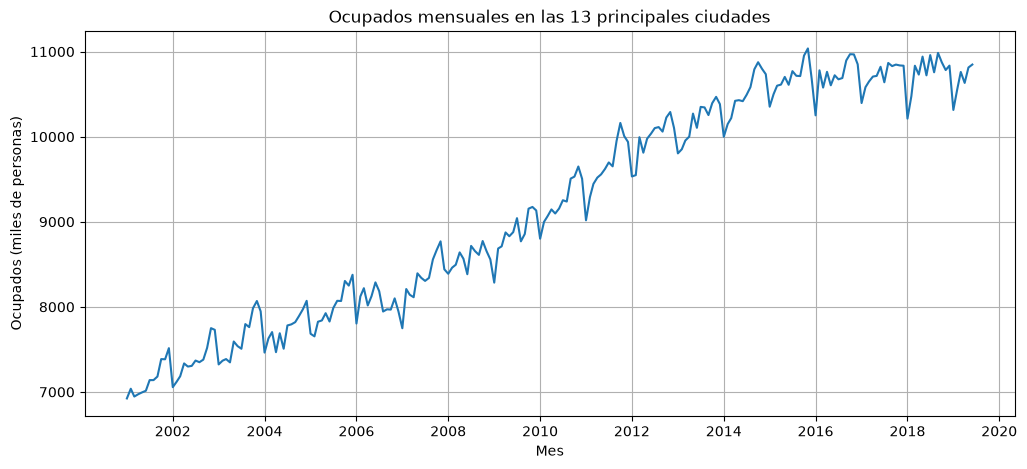

In [4]:
# Carga de datos: la columna "mes" se usa como índice de fechas
data = pd.read_excel(
    "https://raw.githubusercontent.com/dagudelo30/Aprendizaje-automatico-III/main/Clase_1/datosEmpleo.xlsx",
    index_col="mes",
    parse_dates=True,
)

# Serie de ocupados (miles de personas).
# asfreq("MS") declara la frecuencia mensual (inicio de mes): si faltara algún mes,
# aparecería como valor faltante, y además evita la advertencia de frecuencia de statsmodels.
ocupados = data["Ocupados"].asfreq("MS")

print("Observaciones:", len(ocupados))
print("Periodo:", ocupados.index.min().strftime("%Y-%m"), "a", ocupados.index.max().strftime("%Y-%m"))
print("Valores faltantes:", ocupados.isna().sum())
print(ocupados.describe().round(1))

# Gráfica de la serie completa
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ocupados)
ax.set_title("Ocupados mensuales en las 13 principales ciudades")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.grid()
plt.show()

### Lectura de la serie

La serie tiene 222 observaciones mensuales, de enero de 2001 a junio de 2019, sin valores faltantes. El número de ocupados va de un mínimo de 6,924 mil personas a un máximo de 11,037 mil, con una media de 9,161 mil. La serie crece de forma casi continua hasta 2015 y desde entonces se mantiene en un nivel casi constante, con un patrón que se repite todos los años: una caída fuerte en enero y los valores más altos hacia el final del año.

Como el objetivo es pronosticar los próximos 6 meses, los últimos 6 meses de la serie, de enero a junio de 2019, se reservan como muestra de prueba, igual que en el taller anterior. La partición respeta el orden temporal, y la muestra de prueba solo se usa al final, para evaluar los modelos finalistas ya elegidos.

In [5]:
# Horizonte de pronóstico: 6 meses
horizonte = 6

# Partición temporal: los últimos 6 meses se reservan como prueba y no se usan
# para ninguna decisión de modelado hasta la sección 11
train = ocupados.iloc[:-horizonte]
test = ocupados.iloc[-horizonte:]

print("Entrenamiento:", train.index.min().strftime("%Y-%m"), "a", train.index.max().strftime("%Y-%m"), f"({len(train)} meses)")
print("Prueba:       ", test.index.min().strftime("%Y-%m"), "a", test.index.max().strftime("%Y-%m"), f"({len(test)} meses)")

Entrenamiento: 2001-01 a 2018-12 (216 meses)
Prueba:        2019-01 a 2019-06 (6 meses)


Pendiente de la tendencia (miles de personas por año):
2001-2015    261.7
2016-2018     15.2

Efecto estacional de cada mes frente a la tendencia:
     Aditivo (miles)  Multiplicativo (%)
Ene           -310.5                -3.4
Feb           -134.2                -1.4
Mar            -59.5                -0.7
Abr            -57.3                -0.7
May              6.5                 0.1
Jun            -35.8                -0.4
Jul             27.7                 0.3
Ago             14.3                 0.1
Sep             63.8                 0.6
Oct            186.0                 2.0
Nov            200.8                 2.2
Dic             98.1                 1.2

Caída de enero frente a la tendencia, por año:
      Tendencia (miles)  Caída (miles)  Caída (%)
mes                                              
2002             7263.4          207.0        2.9
2003             7476.8          153.3        2.1
2004             7722.0          259.6        3.4
2005             7849.

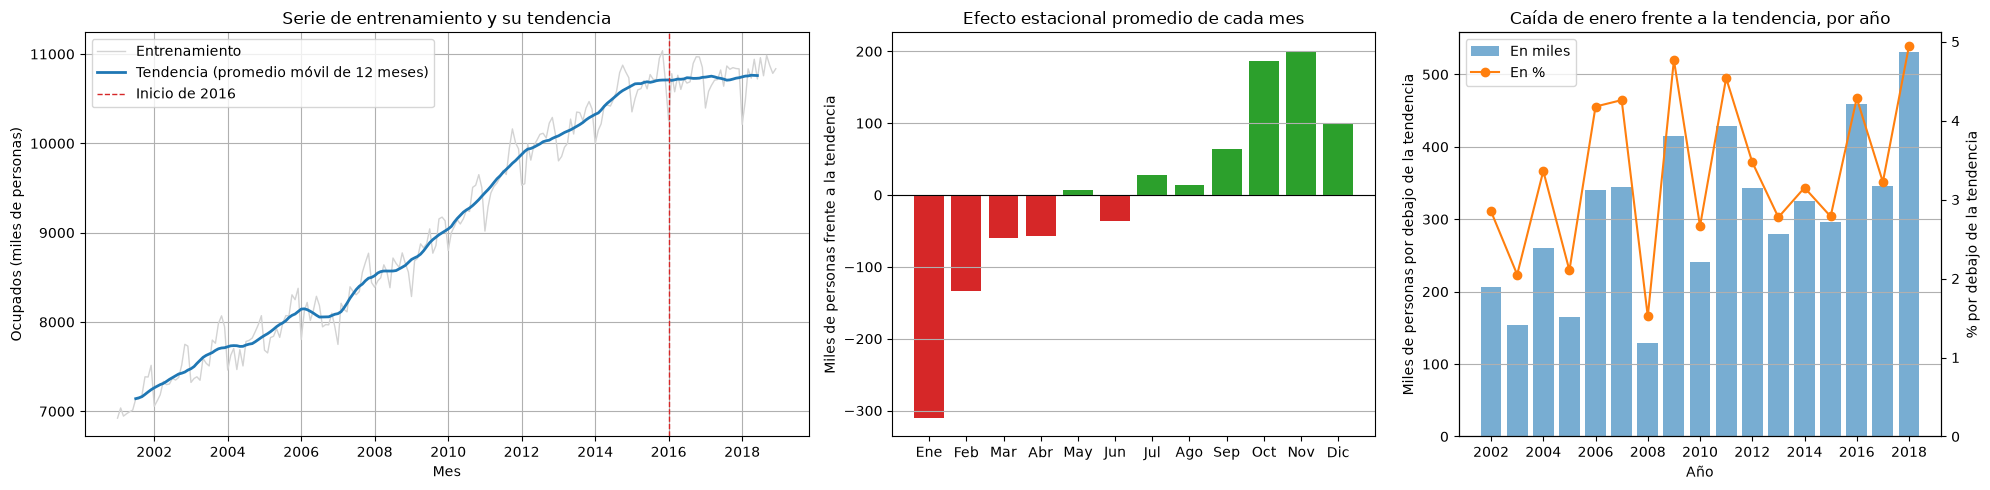

In [6]:
# Rasgos de la serie de entrenamiento que orientan la configuración de los modelos.
# Solo se usa el entrenamiento, para que ninguna decisión dependa de la muestra de prueba.
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
anio_cambio = "2016"   # año desde el que la serie deja de crecer, según la gráfica anterior


def pendiente_anual(serie):
    """Pendiente de una tendencia lineal con dummies de mes, en miles de personas por año.

    Las dummies evitan que el patrón estacional se confunda con la tendencia
    cuando el periodo no empieza y termina en el mismo mes.
    """
    t = np.arange(len(serie)) / 12
    dummies_mes = pd.get_dummies(serie.index.month, drop_first=True, dtype=float).to_numpy()
    X = sm.add_constant(np.column_stack([t, dummies_mes]))
    return sm.OLS(serie.to_numpy(), X).fit().params[1]


# 1. Cambio de la tendencia: pendiente antes y después del año de cambio
periodos = {"2001-2015": train.loc[:"2015"], f"{anio_cambio}-2018": train.loc[anio_cambio:]}
pendientes = pd.Series({nombre: pendiente_anual(serie) for nombre, serie in periodos.items()})
print("Pendiente de la tendencia (miles de personas por año):")
print(pendientes.round(1).to_string())

# 2. Patrón estacional: efecto de cada mes con la descomposición clásica aditiva y multiplicativa
desc_aditiva = seasonal_decompose(train, model="additive")
desc_multiplicativa = seasonal_decompose(train, model="multiplicative")
efectos_estacionales = pd.DataFrame({
    "Aditivo (miles)": desc_aditiva.seasonal.iloc[:12].to_numpy(),          # el entrenamiento empieza en enero
    "Multiplicativo (%)": 100 * (desc_multiplicativa.seasonal.iloc[:12].to_numpy() - 1),
}, index=nombres_meses)
print("\nEfecto estacional de cada mes frente a la tendencia:")
print(efectos_estacionales.round(1).to_string())

# 3. Tamaño de la caída de enero frente a la tendencia en cada año.
# Si la caída fuera estable en miles, el efecto sería aditivo; si fuera estable en porcentaje,
# multiplicativo; si crece incluso en porcentaje, el patrón estacional cambió con el tiempo.
es_enero = train.index.month == 1
tendencia_enero = desc_aditiva.trend[es_enero].dropna()   # enero de 2001 no tiene tendencia
caida_enero = pd.DataFrame({
    "Tendencia (miles)": tendencia_enero,
    "Caída (miles)": tendencia_enero - train[tendencia_enero.index],
})
caida_enero["Caída (%)"] = 100 * caida_enero["Caída (miles)"] / caida_enero["Tendencia (miles)"]
caida_enero.index = caida_enero.index.year
print("\nCaída de enero frente a la tendencia, por año:")
print(caida_enero.round(1).to_string())

tabla_enero = pd.DataFrame({
    "2002-2005": caida_enero.loc[2002:2005].mean(),
    "2016-2018": caida_enero.loc[2016:2018].mean(),
}).T
tabla_enero.loc["Cociente 2016-2018 / 2002-2005"] = tabla_enero.loc["2016-2018"] / tabla_enero.loc["2002-2005"]
print("\nPromedio de enero al inicio y al final del entrenamiento:")
print(tabla_enero.round(2).to_string())

# Gráficas: tendencia con el año de cambio, efecto de cada mes y caída de enero por año
fig, axes = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={"width_ratios": [3, 2, 2]})

axes[0].plot(train, color="lightgray", linewidth=1, label="Entrenamiento")
axes[0].plot(desc_aditiva.trend, color="C0", linewidth=2, label="Tendencia (promedio móvil de 12 meses)")
axes[0].axvline(pd.Timestamp(f"{anio_cambio}-01-01"), color="C3", linestyle="--", linewidth=1,
                label=f"Inicio de {anio_cambio}")
axes[0].set_title("Serie de entrenamiento y su tendencia")
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Ocupados (miles de personas)")
axes[0].legend(loc="upper left")
axes[0].grid()

colores_barras = ["C3" if efecto < 0 else "C2" for efecto in efectos_estacionales["Aditivo (miles)"]]
axes[1].bar(nombres_meses, efectos_estacionales["Aditivo (miles)"], color=colores_barras)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Efecto estacional promedio de cada mes")
axes[1].set_ylabel("Miles de personas frente a la tendencia")
axes[1].grid(axis="y")

# Caída de enero en miles (barras, eje izquierdo) y en porcentaje (línea, eje derecho)
axes[2].bar(caida_enero.index, caida_enero["Caída (miles)"], color="C0", alpha=0.6, label="En miles")
axes[2].set_ylabel("Miles de personas por debajo de la tendencia")
axes[2].set_xlabel("Año")
axes[2].set_xticks(caida_enero.index[::2])   # años enteros, uno de cada dos para que se lean
eje_porcentaje = axes[2].twinx()
eje_porcentaje.plot(caida_enero.index, caida_enero["Caída (%)"], color="C1", marker="o", label="En %")
eje_porcentaje.set_ylabel("% por debajo de la tendencia")
eje_porcentaje.set_ylim(bottom=0)
axes[2].set_title("Caída de enero frente a la tendencia, por año")
lineas = axes[2].get_legend_handles_labels()[0] + eje_porcentaje.get_legend_handles_labels()[0]
etiquetas = axes[2].get_legend_handles_labels()[1] + eje_porcentaje.get_legend_handles_labels()[1]
axes[2].legend(lineas, etiquetas, loc="upper left")
axes[2].grid(axis="y")

fig.tight_layout()
plt.show()

### Rasgos de la serie de entrenamiento

**Cambio de la tendencia.** Con una tendencia lineal y dummies de mes, la serie creció 261.7 mil personas por año entre 2001 y 2015, y solo 15.2 mil por año entre 2016 y 2018, cerca de 94 % menos. En la gráfica «Serie de entrenamiento y su tendencia», la tendencia sube de forma casi continua hasta 2015 y luego se aplana alrededor de 10,700 mil. Este cambio afecta a cualquier modelo que estime una pendiente con toda la historia, porque tendería a extender hacia el futuro un crecimiento que ya no ocurre. Por eso, en cada familia se incluyen alternativas que pueden adaptarse a él: tendencias amortiguadas o ausentes y ventanas de estimación cortas en la suavización exponencial, diferenciación en los modelos ARIMA, que pronostican a partir del nivel reciente, y puntos de cambio de la tendencia en Prophet.

**Forma del patrón estacional.** En la gráfica «Efecto estacional promedio de cada mes», enero es el mes con el mayor efecto: queda 310.5 mil personas (3.4 %) por debajo de la tendencia, y febrero 134.2 mil. Desde septiembre la serie sube, hasta alcanzar sus valores más altos en octubre y noviembre, con 186.0 y 200.8 mil por encima de la tendencia. Entre diciembre y enero el efecto pasa de +98.1 a -310.5 mil, un cambio de 408.6 mil personas en un solo mes. Un patrón tan brusco requiere que cada mes pueda tener su propio efecto, o una representación con suficientes términos de alta frecuencia.

**Tamaño del patrón estacional.** Entre 2002-2005 y 2016-2018, la tendencia de enero aumentó 42 % (de 7,577.8 a 10,731.9 mil). Si el efecto estacional fuera aditivo, la caída de enero sería parecida en miles de personas en ambos periodos; si fuera multiplicativo, habría crecido en la misma proporción que el nivel, es decir, 1.42 veces. En realidad se multiplicó por 2.27 (de 196.3 a 445.5 mil personas) y pasó de 2.59 % a 4.15 % del nivel. El supuesto multiplicativo describe mejor la serie que el aditivo, porque la caída sí creció con el nivel, pero tampoco basta: creció incluso como porcentaje. Además, como muestra la gráfica «Caída de enero frente a la tendencia, por año», varía bastante de un año a otro, entre 129.6 mil (1.5 %) en 2008 y 531.6 mil (4.9 %) en 2018. Esto es un indicio, no una prueba, porque la descomposición clásica supone un mismo patrón para todos los años y estima la tendencia con un promedio móvil, pero sugiere que el patrón estacional cambió con el tiempo.

Estos rasgos orientan dos decisiones comunes a las tres familias. Primero, se evalúan versiones aditivas y multiplicativas de la estacionalidad: la multiplicativa describe mejor la historia completa, pero en los años recientes, en los que el nivel cambió poco, las dos pueden pronosticar de forma parecida, de modo que los datos no permiten descartar ninguna antes de la validación. Segundo, los modelos deben poder darle más peso al patrón estacional reciente: en la suavización exponencial, con el parámetro de actualización de la estacionalidad $\gamma$; en los modelos ARIMA, con la componente estacional, que relaciona cada mes con el mismo mes de años anteriores; y en las tres familias, con ventanas de estimación que usan solo los años más recientes. La elección final entre estas alternativas se hace con el error de pronóstico en la validación.

## 3. Esquema de validación y funciones comunes

Para elegir entre modelos y configuraciones sin usar la muestra de prueba, se aplica la misma validación con origen móvil del taller anterior. Se definen 6 cortes en el tiempo dentro del entrenamiento, y en cada uno el modelo se ajusta con los meses anteriores al corte y pronostica los 6 meses siguientes. Ajustar significa volver a estimar los parámetros del modelo solo con los datos disponibles hasta el corte, de modo que ningún pronóstico usa información posterior. Los 6 cortes cubren los semestres de 2016 a 2018, y en cada uno se calculan dos métricas:

- **RMSE** (raíz del error cuadrático medio), en miles de personas, que penaliza más los errores grandes.
- **MAPE** (error porcentual absoluto medio), en porcentaje del valor real, que permite leer el error en términos relativos.

El criterio principal de selección es el RMSE promedio de los 6 cortes, y el MAPE promedio se usa como complemento. Entre los mejores modelos se revisa además en cuántos cortes cada uno supera al naive estacional, para que la elección no dependa de un solo semestre.

En este esquema hay que distinguir dos ventanas. La primera es la del protocolo de evaluación: en cada corte, los datos disponibles van desde enero de 2001 hasta el mes anterior al corte, de modo que la historia disponible crece de un corte al siguiente (ventana recursiva). La segunda es la ventana de estimación de cada modelo: dentro de los datos disponibles en un corte, el modelo puede usar toda la historia (ventana recursiva) o solo los últimos $w$ meses (ventana móvil). La primera es igual para todos los modelos, y la segunda es un hiperparámetro que se busca en cada familia.

Corte 1: ajuste 2001-01 a 2015-12 (180 meses) | validación 2016-01 a 2016-06
Corte 2: ajuste 2001-01 a 2016-06 (186 meses) | validación 2016-07 a 2016-12
Corte 3: ajuste 2001-01 a 2016-12 (192 meses) | validación 2017-01 a 2017-06
Corte 4: ajuste 2001-01 a 2017-06 (198 meses) | validación 2017-07 a 2017-12
Corte 5: ajuste 2001-01 a 2017-12 (204 meses) | validación 2018-01 a 2018-06
Corte 6: ajuste 2001-01 a 2018-06 (210 meses) | validación 2018-07 a 2018-12


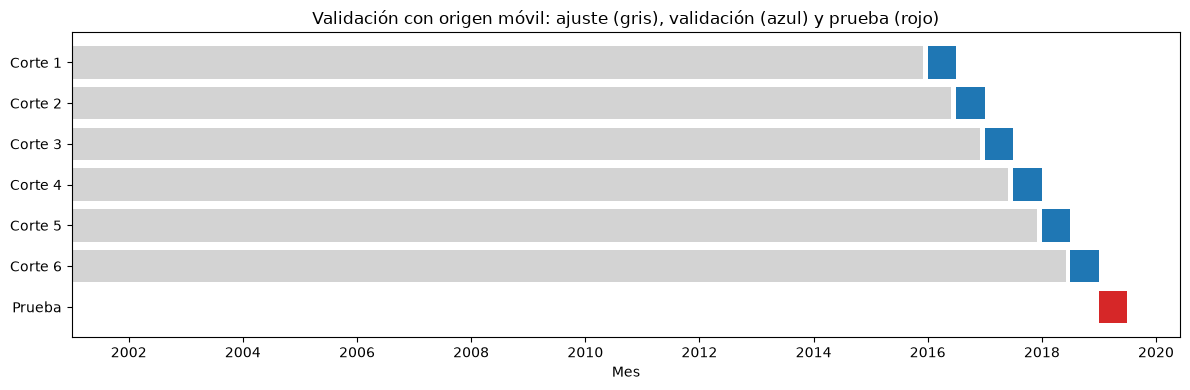

In [7]:
# Validación con origen móvil dentro del entrenamiento (la muestra de prueba no se usa aquí).
# TimeSeriesSplit no mezcla los datos: cada corte ajusta con los meses anteriores
# y valida con los 6 meses siguientes. Por defecto la ventana de ajuste es expansiva
# (max_train_size=None), es decir, cada corte tiene disponible toda la historia hasta ese punto.
n_cortes = 6
tscv = TimeSeriesSplit(n_splits=n_cortes, test_size=horizonte)

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    print(
        f"Corte {numero}: ajuste {train.index[idx_ajuste[0]]:%Y-%m} a {train.index[idx_ajuste[-1]]:%Y-%m} "
        f"({len(idx_ajuste)} meses) | validación {train.index[idx_validacion[0]]:%Y-%m} "
        f"a {train.index[idx_validacion[-1]]:%Y-%m}"
    )

# Diagrama de los cortes de validación y de la muestra de prueba
fig, ax = plt.subplots(figsize=(12, 4))
for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    inicio_ajuste, fin_ajuste = train.index[idx_ajuste[0]], train.index[idx_ajuste[-1]]
    inicio_validacion, fin_validacion = train.index[idx_validacion[0]], train.index[idx_validacion[-1]]
    # Barra gris: meses disponibles para ajustar; barra azul: meses de validación
    ax.barh(numero, fin_ajuste - inicio_ajuste, left=inicio_ajuste, color="lightgray")
    ax.barh(numero, fin_validacion - inicio_validacion + pd.Timedelta(days=30),
            left=inicio_validacion, color="C0")

# Muestra de prueba, reservada hasta el final
ax.barh(n_cortes + 1, test.index[-1] - test.index[0] + pd.Timedelta(days=30),
        left=test.index[0], color="C3")

ax.set_yticks(range(1, n_cortes + 2))
ax.set_yticklabels([f"Corte {numero}" for numero in range(1, n_cortes + 1)] + ["Prueba"])
ax.invert_yaxis()
ax.set_title("Validación con origen móvil: ajuste (gris), validación (azul) y prueba (rojo)")
ax.set_xlabel("Mes")
plt.tight_layout()
plt.show()

Los 6 cortes validan semestres consecutivos entre enero de 2016 y diciembre de 2018. En la gráfica «Validación con origen móvil: ajuste (gris), validación (azul) y prueba (rojo)», los datos disponibles para ajustar el modelo en cada corte van desde enero de 2001 hasta el mes anterior al corte (gris), entre 180 y 210 meses, y el modelo se evalúa en los 6 meses siguientes (azul). La muestra de prueba (rojo) queda por fuera de todos los cortes. Son exactamente los mismos cortes del taller anterior, lo que permite comparar los modelos nuevos con los anteriores corte por corte.

### Caché de evaluaciones

La optimización bayesiana evalúa cientos de configuraciones, y cada una requiere ajustar el modelo en los 6 cortes. Para no repetir esos ajustes cada vez que se ejecuta el notebook, el resultado de cada configuración en cada corte se guarda en un archivo de la carpeta `cache/`, que no forma parte del repositorio. Cada archivo guarda las métricas y los pronósticos del corte, o el mensaje de error si el ajuste falló, junto con una firma: un hash SHA-256 de todos los campos que determinan el resultado.

- **La configuración del modelo:** la familia y sus hiperparámetros. Una configuración distinta se guarda en otro archivo, de modo que cambiar un hiperparámetro solo obliga a ajustar esa configuración.
- **Los datos:** un hash de los valores y de las fechas de la serie disponible en el corte y de los meses validados.
- **El corte:** sus fechas de inicio y fin de ajuste y de validación, el horizonte, la separación entre ajuste y validación y el tipo de ventana del protocolo.
- **Las versiones** de las librerías que intervienen en el ajuste y en las métricas.
- **La constante `CACHE_VERSION`.**

Al leer un archivo, si la firma guardada no coincide con la actual, el resultado se descarta, se vuelve a ajustar el modelo y se muestra una advertencia con los campos que cambiaron. Así, el caché se invalida solo si cambian los datos, los cortes o las versiones de las librerías. Lo único que la firma no puede detectar es un cambio en el código de una función de ajuste o de pronóstico; en ese caso, hay que subir `CACHE_VERSION`, lo que invalida todos los archivos. Con `RECALCULAR = True`, el caché se ignora y todos los modelos se vuelven a ajustar.

Los archivos se escriben primero con la extensión `.tmp` y luego se renombran, de modo que una ejecución interrumpida nunca deja un resultado incompleto que pueda leerse como válido. El caché no cambia ningún resultado: el notebook se puede ejecutar completo sin él, por ejemplo en Google Colab, y solo tarda más.

In [8]:
# --- Caché de evaluaciones por corte ---
CARPETA_CACHE = Path("cache")   # ruta relativa a la carpeta del notebook (incluida en .gitignore)
CACHE_VERSION = 1               # se sube a mano cuando cambia el código de una función de ajuste o de pronóstico
RECALCULAR = False              # True ignora el caché y vuelve a ajustar todos los modelos

# Versiones de las librerías que intervienen en el ajuste y en las métricas: si cambian, el caché se invalida
VERSIONES_CACHE = {
    "numpy": np.__version__, "pandas": pd.__version__, "statsmodels": statsmodels.__version__,
    "scikit-learn": sklearn.__version__, "prophet": prophet.__version__, "pmdarima": pmdarima.__version__,
}

# Procesos para ajustar en paralelo los cortes pendientes de una evaluación, por función de pronóstico.
# Solo conviene en los modelos lentos de estimar; no cambia ningún resultado ni la firma del caché.
N_PROCESOS = min(n_cortes, os.cpu_count() or 1)
PROCESOS_POR_MODELO = {"crear_pronostico_sarima": N_PROCESOS}


class ErrorDeAjuste(Exception):
    """Fallo del ajuste o del pronóstico en algún corte; el mensaje es el del error original."""


def hash_datos(datos: pd.Series | pd.DataFrame) -> str:
    """SHA-256 de los valores, el tipo, los nombres y el índice temporal de una serie o tabla."""
    contenido = pd.util.hash_pandas_object(datos, index=True).to_numpy().tobytes()
    descripcion = repr((getattr(datos, "name", None), list(getattr(datos, "columns", [])), str(datos.dtypes)))
    return hashlib.sha256(contenido + descripcion.encode()).hexdigest()


def forma_canonica(valor: object) -> object:
    """Convierte un valor a una forma estable y serializable en JSON, para que la firma no dependa
    del orden de las claves ni del tipo concreto de los números o las fechas."""
    if isinstance(valor, dict):
        return {str(clave): forma_canonica(valor[clave]) for clave in sorted(valor, key=str)}
    if isinstance(valor, (list, tuple)):
        return [forma_canonica(elemento) for elemento in valor]
    if isinstance(valor, (pd.Series, pd.DataFrame)):
        return hash_datos(valor)
    if isinstance(valor, np.ndarray):
        return hashlib.sha256(np.ascontiguousarray(valor).tobytes() + str(valor.dtype).encode()).hexdigest()
    if isinstance(valor, (pd.Timestamp, np.datetime64)):
        return pd.Timestamp(valor).isoformat()
    if isinstance(valor, np.generic):
        return valor.item()
    if valor is None or isinstance(valor, (bool, int, float, str)):
        return valor
    return repr(valor)


def hash_campos(campos: dict) -> str:
    """SHA-256 de unos campos ya en forma canónica."""
    return hashlib.sha256(json.dumps(campos, sort_keys=True, ensure_ascii=False).encode()).hexdigest()


def campos_corte(identidad: dict, serie_ajuste: pd.Series, serie_validacion: pd.Series, cv) -> dict:
    """Campos que determinan el resultado de una configuración en un corte, en forma canónica."""
    max_train_size = getattr(cv, "max_train_size", None)
    return forma_canonica({
        "modelo": identidad["modelo"],
        "config": identidad["config"],
        "corte": {
            "inicio_ajuste": serie_ajuste.index[0], "fin_ajuste": serie_ajuste.index[-1],
            "inicio_validacion": serie_validacion.index[0], "fin_validacion": serie_validacion.index[-1],
            "horizonte": len(serie_validacion), "separacion": getattr(cv, "gap", 0),
            "ventana_protocolo": "expansiva" if max_train_size is None else f"deslizante de {max_train_size}",
        },
        "datos": {"ajuste": serie_ajuste, "validacion": serie_validacion},
        "versiones": VERSIONES_CACHE,
        "cache_version": CACHE_VERSION,
    })


def ruta_cache(identidad: dict, numero_corte: int) -> Path:
    """Archivo de una configuración en un corte: <familia>_<hash de 10 caracteres>_c<k>.joblib."""
    familia = identidad["modelo"].removeprefix("crear_pronostico_")
    huella = hash_campos(forma_canonica(identidad["config"]))[:10]
    return CARPETA_CACHE / f"{familia}_{huella}_c{numero_corte}.joblib"


def leer_cache(ruta: Path, campos: dict) -> tuple[dict | None, str]:
    """Lee el resultado de un corte. Devuelve (resultado, estado), con estado "missing" si no hay archivo,
    "corrupt" si no se puede leer, "invalid" si la firma no coincide y "loaded" si es válido."""
    if not ruta.exists():
        return None, "missing"
    try:
        contenido = joblib.load(ruta)
        campos_guardados, firma_guardada, resultado = contenido["fields"], contenido["fields_hash"], contenido["result"]
    except Exception:
        warnings.warn(f"Caché ilegible, se vuelve a ajustar: {ruta.name}", stacklevel=2)
        return None, "corrupt"
    if firma_guardada != hash_campos(campos):
        cambiados = sorted(campo for campo in set(campos) | set(campos_guardados)
                           if campos.get(campo) != campos_guardados.get(campo))
        warnings.warn(f"Caché desactualizado en {ruta.name}; cambiaron: {', '.join(cambiados)}", stacklevel=2)
        return None, "invalid"
    return resultado, "loaded"


def guardar_cache(ruta: Path, campos: dict, resultado: dict) -> None:
    """Guarda el resultado de un corte de forma atómica: escribe un .tmp y luego lo renombra."""
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_name(ruta.name + ".tmp")
    joblib.dump({"fields": campos, "fields_hash": hash_campos(campos), "result": resultado}, temporal)
    os.replace(temporal, ruta)

### Funciones de evaluación

Las funciones de evaluación son las del taller anterior, con tres cambios. Primero, la evaluación verifica que el modelo entregue 6 pronósticos finitos en cada corte, y si no lo hace en alguno, el modelo no se evalúa: así, ningún modelo se promedia sobre menos cortes que los demás. Segundo, cuando se indica la configuración del modelo, cada corte se lee del caché si su firma coincide, y solo se ajustan los cortes pendientes, en paralelo en los modelos lentos de estimar; la tabla de resultados indica si cada corte se leyó del caché (`loaded`) o se calculó (`computed`). Tercero, cada modelo evaluado se guarda en un registro común con su familia y su función de pronóstico, de modo que la comparación final, la evaluación en la prueba y el pronóstico se construyen recorriendo el registro, sin repetir código para cada familia. Todas las funciones de pronóstico tienen la misma forma: reciben la serie disponible hasta el corte y el número de meses a pronosticar, y devuelven los pronósticos. Si un modelo elige su especificación dentro de cada corte, su función de pronóstico puede describirla en los atributos de la serie que devuelve, y esa descripción se guarda y se muestra junto con las métricas del corte.

In [9]:
def calcular_metricas(real, pronostico):
    """RMSE (miles de personas) y MAPE (%) de un pronóstico frente a los valores reales."""
    return {
        "rmse": np.sqrt(mean_squared_error(real, pronostico)),
        # sklearn devuelve el MAPE como fracción, por eso se multiplica por 100
        "mape": 100 * mean_absolute_percentage_error(real, pronostico),
    }


def evaluar_corte(funcion_pronostico, serie_ajuste, serie_validacion, campos=None, ruta=None) -> dict:
    """Ajusta y evalúa un modelo en un corte; si se indica una ruta, guarda el resultado apenas termina.

    Devuelve las métricas y los pronósticos, o el mensaje de error si el ajuste falla o el pronóstico
    no tiene h valores finitos. Si la función de pronóstico devuelve una serie con atributos (attrs),
    por ejemplo el modelo que eligió en el corte, se guardan como detalle del corte.
    """
    try:
        salida = funcion_pronostico(serie_ajuste, len(serie_validacion))
        pronostico = np.asarray(salida, dtype=float)
        if pronostico.shape != (len(serie_validacion),) or not np.isfinite(pronostico).all():
            raise ValueError(f"pronóstico inválido en el corte que inicia en {serie_validacion.index[0]:%Y-%m}")
        resultado = {**calcular_metricas(serie_validacion, pronostico),
                     "pronostico": pd.Series(pronostico, index=serie_validacion.index)}
        detalle = dict(getattr(salida, "attrs", {}))
        if detalle:
            resultado["detalle"] = detalle
    except Exception as error:
        resultado = {"error": f"{type(error).__name__}: {error}"[:200]}
    if ruta is not None:
        guardar_cache(ruta, campos, resultado)
    return resultado


def evaluar_validacion(funcion_pronostico, serie=train, cv=tscv, identidad=None, n_procesos=1):
    """Evalúa un método de pronóstico en cada corte de la validación con origen móvil.

    funcion_pronostico(serie_ajuste, h) debe devolver h pronósticos usando solo serie_ajuste.
    identidad: {"modelo": nombre de la función que crea el pronóstico, "config": configuración}. Si se
    indica, cada corte se lee del caché cuando su firma coincide, y solo se ajustan los cortes pendientes.
    n_procesos: procesos para ajustar en paralelo los cortes pendientes (no cambia el resultado).
    Si el ajuste falla en algún corte, los demás se guardan igual y al final se lanza ErrorDeAjuste:
    un modelo solo se compara con los demás si produce pronósticos válidos en todos los cortes.
    Devuelve una tabla con el RMSE (miles), el MAPE (%), los detalles del modelo si los hay y el estado
    ("loaded" o "computed") de cada corte.
    """
    resultados, estados, pendientes = {}, {}, []
    for numero, (idx_ajuste, idx_validacion) in enumerate(cv.split(serie), start=1):
        serie_ajuste, serie_validacion = serie.iloc[idx_ajuste], serie.iloc[idx_validacion]
        assert serie_validacion.index[0] > serie_ajuste.index[-1], "la validación debe ser posterior al ajuste"
        campos = ruta = None
        if identidad is not None:
            campos = campos_corte(identidad, serie_ajuste, serie_validacion, cv)
            ruta = ruta_cache(identidad, numero)
            if not RECALCULAR:
                resultado, estado = leer_cache(ruta, campos)
                if estado == "loaded":
                    resultados[numero], estados[numero] = resultado, "loaded"
                    continue
        pendientes.append((numero, serie_ajuste, serie_validacion, campos, ruta))

    if n_procesos > 1 and len(pendientes) > 1:
        calculados = Parallel(n_jobs=min(n_procesos, len(pendientes)))(
            delayed(evaluar_corte)(funcion_pronostico, *tarea[1:]) for tarea in pendientes
        )
    else:
        calculados = [evaluar_corte(funcion_pronostico, *tarea[1:]) for tarea in pendientes]
    for (numero, *_), resultado in zip(pendientes, calculados):
        resultados[numero], estados[numero] = resultado, "computed"

    errores = [resultados[numero]["error"] for numero in sorted(resultados) if "error" in resultados[numero]]
    if errores:
        raise ErrorDeAjuste(errores[0])
    filas = [{
        "inicio_validacion": resultados[numero]["pronostico"].index[0].strftime("%Y-%m"),
        "rmse": resultados[numero]["rmse"],
        "mape": resultados[numero]["mape"],
        **resultados[numero].get("detalle", {}),
        "estado": estados[numero],
    } for numero in sorted(resultados)]
    return pd.DataFrame(filas).set_index("inicio_validacion")


# Registro común de modelos: resultados por corte, familia y función de pronóstico de cada uno
validacion = {}
familias = {}
funciones_pronostico = {}


def registrar_modelo(nombre, familia, funcion_pronostico, resultados=None, identidad=None, n_procesos=1):
    """Evalúa un modelo en la validación (si no se entregan sus resultados) y lo guarda en el registro."""
    if resultados is None:
        resultados = evaluar_validacion(funcion_pronostico, identidad=identidad, n_procesos=n_procesos)
    validacion[nombre] = resultados
    familias[nombre] = familia
    funciones_pronostico[nombre] = funcion_pronostico
    return resultados


def resumir_validacion(nombres, referencias=("Naive estacional",)):
    """Resumen de la validación de los modelos indicados, ordenado por RMSE promedio.

    Incluye el RMSE y el MAPE promedio de los 6 cortes y, para cada referencia, el número
    de cortes en que cada modelo tiene un RMSE menor que el de esa referencia.
    """
    resumen = pd.DataFrame({
        "RMSE promedio": pd.Series({nombre: validacion[nombre]["rmse"].mean() for nombre in nombres}),
        "MAPE promedio (%)": pd.Series({nombre: validacion[nombre]["mape"].mean() for nombre in nombres}),
    })
    for referencia in referencias:
        resumen[f"Cortes mejores que {referencia}"] = pd.Series({
            nombre: int((validacion[nombre]["rmse"] < validacion[referencia]["rmse"]).sum())
            for nombre in nombres
        })
    return resumen.sort_values("RMSE promedio")


def error_por_corte(nombres, metrica="rmse"):
    """Tabla con la métrica indicada ("rmse" o "mape") de cada modelo (columnas) en cada corte (filas)."""
    return pd.DataFrame({nombre: validacion[nombre][metrica] for nombre in nombres})


def graficar_resumen_validacion(modelos, destacado, titulo, referencia="Naive estacional"):
    """Gráfica de barras del RMSE promedio de validación, con la referencia marcada con una línea.

    modelos: diccionario {etiqueta para la gráfica: nombre del modelo en validacion}.
    destacado: etiqueta del modelo que se resalta en verde; las referencias naive van en gris.
    Devuelve la tabla resumen de la validación con las etiquetas como índice.
    """
    etiquetas = {nombre: etiqueta for etiqueta, nombre in modelos.items()}
    resumen = resumir_validacion(list(modelos.values()), referencias=(referencia,)).rename(index=etiquetas)
    rmse_referencia = validacion[referencia]["rmse"].mean()

    orden = resumen.sort_values("RMSE promedio", ascending=False)
    colores = ["C2" if etiqueta == destacado else "gray" if etiqueta.startswith("Naive") else "C0"
               for etiqueta in orden.index]

    fig, ax = plt.subplots(figsize=(11, 0.5 * len(orden) + 1))
    ax.barh(orden.index, orden["RMSE promedio"], color=colores)
    ax.axvline(rmse_referencia, color="black", linestyle="--", linewidth=1,
               label=f"{referencia} ({rmse_referencia:.1f} mil)")
    for posicion, valor in enumerate(orden["RMSE promedio"]):
        # Fondo blanco para que la etiqueta se lea aunque cruce la línea de referencia
        ax.text(valor + 3, posicion, f"{valor:.1f}", va="center", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xlim(0, orden["RMSE promedio"].max() * 1.12)
    ax.set_title(titulo)
    ax.set_xlabel("RMSE promedio (miles de personas)")
    ax.legend(loc="upper right")
    ax.grid(axis="x")
    plt.tight_layout()
    plt.show()
    return resumen

### Funciones de la optimización bayesiana

Las tres familias se optimizan con la misma función. Cada familia define su espacio de búsqueda y cómo construir su función de pronóstico a partir de una configuración, y la optimización aplica las mismas reglas a todas:

- **Objetivo:** el RMSE promedio de los mismos 6 cortes de validación, calculado con la función `evaluar_validacion`. Optuna busca la configuración que lo minimiza con su algoritmo por defecto, TPE (*Tree-structured Parzen Estimator*): después de unos intentos iniciales al azar, separa los intentos con menor error de los demás y propone valores que aparecen con más frecuencia entre los mejores.
- **Reproducibilidad:** el algoritmo usa una semilla fija, de modo que la secuencia de intentos se repite en cada ejecución.
- **Fallos:** si el ajuste falla o el pronóstico no es válido en algún corte, el intento se descarta sin asignarle un error. Optuna lo registra como podado (*pruned*), un estado que TPE ubica entre los peores intentos; así, el algoritmo deja de proponer configuraciones que no se pueden estimar. Si el intento se marcara solo como fallido, TPE no lo tendría en cuenta y podría volver a proponer la misma región una y otra vez. Se registra el motivo del fallo y el número de intentos fallidos.
- **Intentos repetidos:** cuando Optuna propone una configuración discreta que ya evaluó, se reutiliza su resultado en lugar de volver a ajustar los modelos.
- **Revisión de bordes:** al terminar, se revisa si el mejor valor de cada hiperparámetro numérico quedó en el límite de su rango. Si es así, el rango se amplía en una segunda etapa, que empieza evaluando los mejores intentos de la primera. Como el espacio ampliado contiene al anterior, la segunda etapa parte del mejor resultado conocido y nunca termina con un error mayor.
- **Verificación:** el mejor intento se vuelve a evaluar al registrarlo, y su error debe coincidir con el obtenido durante la optimización.

Para leer cada estudio se usan dos gráficas: el RMSE de cada intento con el mejor valor acumulado, que muestra si la búsqueda se estabilizó, y la importancia de cada hiperparámetro, que indica cuáles explican la mayor parte de la variación del error entre intentos.

In [10]:
# Semilla de la optimización bayesiana, común a todos los estudios
SEMILLA = 2026


def identidad_cache(crear_pronostico, config):
    """Identidad de una evaluación en el caché: la función que crea el pronóstico y su configuración."""
    return {"modelo": crear_pronostico.__name__, "config": config}


def optimizar(sugerir_configuracion, crear_pronostico, n_intentos, semilla=SEMILLA, intentos_iniciales=()):
    """Optimización bayesiana (TPE) del RMSE promedio de validación.

    sugerir_configuracion(trial) define el espacio de búsqueda y devuelve un diccionario con la
    configuración del intento. crear_pronostico(config) devuelve la función de pronóstico, con la
    firma (serie_ajuste, h). Cada intento se evalúa con evaluar_validacion en los mismos 6 cortes,
    usando el caché y, si la familia lo tiene definido en PROCESOS_POR_MODELO, ajustes en paralelo.
    Si el ajuste falla en algún corte, el intento se descarta (estado PRUNED de Optuna), de modo que
    TPE lo cuenta entre los peores y no vuelve a proponer esa región; las configuraciones repetidas
    reutilizan el resultado ya calculado.
    intentos_iniciales: valores de hiperparámetros que se evalúan primero (por ejemplo, los mejores
    intentos de una etapa anterior), antes de que el algoritmo proponga los suyos.
    """
    n_procesos = PROCESOS_POR_MODELO.get(crear_pronostico.__name__, 1)
    resultados_previos = {}

    def objetivo(trial):
        config = sugerir_configuracion(trial)
        trial.set_user_attr("config", config)
        clave = tuple(sorted(config.items()))
        if clave in resultados_previos:
            trial.set_user_attr("repetido", True)
        else:
            try:
                resultados_previos[clave] = evaluar_validacion(
                    crear_pronostico(config), identidad=identidad_cache(crear_pronostico, config),
                    n_procesos=n_procesos,
                )
            except ErrorDeAjuste as error:   # fallo del ajuste en algún corte: invalida el intento completo
                resultados_previos[clave] = str(error)
            except Exception as error:       # cualquier otro fallo al construir el modelo
                resultados_previos[clave] = f"{type(error).__name__}: {error}"[:200]

        resultado = resultados_previos[clave]
        if isinstance(resultado, str):
            trial.set_user_attr("error", resultado)
            # Un intento fallido sin valor (NaN) es invisible para TPE, que volvería a proponer la misma
            # región; descartado, TPE lo ubica entre los peores intentos sin inventarle un RMSE
            raise optuna.TrialPruned(resultado)
        trial.set_user_attr("rmse_cortes", resultado["rmse"].tolist())
        trial.set_user_attr("mape_cortes", resultado["mape"].tolist())
        trial.set_user_attr("cortes_cargados", int((resultado["estado"] == "loaded").sum()))
        return resultado["rmse"].mean()

    estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=semilla))
    for parametros in intentos_iniciales:
        estudio.enqueue_trial(parametros)

    # Durante la optimización solo se muestran errores: los intentos fallidos se resumen al final
    optuna.logging.set_verbosity(optuna.logging.ERROR)
    inicio = pd.Timestamp.now()
    estudio.optimize(objetivo, n_trials=n_intentos)
    segundos = (pd.Timestamp.now() - inicio).total_seconds()
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    fallidos = [t for t in estudio.trials if t.state == optuna.trial.TrialState.PRUNED]
    repetidos = [t for t in estudio.trials if t.user_attrs.get("repetido")]
    nuevos_completos = [t for t in estudio.trials
                        if t.state == optuna.trial.TrialState.COMPLETE and not t.user_attrs.get("repetido")]
    print(f"Intentos: {len(estudio.trials)} | completos: {len(estudio.trials) - len(fallidos)} "
          f"| fallidos: {len(fallidos)} | repetidos (resultado reutilizado): {len(repetidos)}")
    print(f"Cortes leídos del caché: {sum(t.user_attrs['cortes_cargados'] for t in nuevos_completos)} "
          f"de {n_cortes * len(nuevos_completos)} (configuraciones completas distintas)")
    print(f"Tiempo total: {segundos / 60:.1f} min | por intento evaluado: "
          f"{segundos / max(len(estudio.trials) - len(repetidos), 1):.2f} s")
    if fallidos:
        motivos = pd.Series([t.user_attrs.get("error", "sin mensaje") for t in fallidos]).value_counts()
        print("Motivos de los intentos fallidos:")
        print(motivos.head(5).to_string())
    print(f"Mejor RMSE promedio: {estudio.best_value:.2f} (intento {estudio.best_trial.number})")
    return estudio


def resumir_estudio(estudio, n_mejores=10, referencia="Naive estacional"):
    """Mejores intentos completos de un estudio, sin repetidos: configuración, RMSE y MAPE promedio
    y número de cortes en que superan a la referencia."""
    rmse_referencia = validacion[referencia]["rmse"].to_numpy()
    filas = []
    for intento in estudio.trials:
        if intento.state != optuna.trial.TrialState.COMPLETE or intento.user_attrs.get("repetido"):
            continue
        rmse_cortes = np.asarray(intento.user_attrs["rmse_cortes"])
        filas.append({
            "Intento": intento.number,
            **intento.user_attrs["config"],
            "RMSE promedio": intento.value,
            "MAPE promedio (%)": np.mean(intento.user_attrs["mape_cortes"]),
            f"Cortes mejores que {referencia}": int((rmse_cortes < rmse_referencia).sum()),
        })
    return pd.DataFrame(filas).set_index("Intento").sort_values("RMSE promedio").head(n_mejores)


def graficar_estudio(estudio, titulo, referencia="Naive estacional"):
    """RMSE de cada intento con el mejor valor acumulado, e importancia de cada hiperparámetro.

    El eje del RMSE llega hasta el percentil 90 de los intentos, sin pasar del doble del RMSE de la
    referencia, para que los intentos con errores muy grandes no aplasten la gráfica; los que quedan
    por fuera se cuentan en una nota. La importancia se calcula con fANOVA (semilla fija) sobre los
    hiperparámetros presentes en todos los intentos completos; los que solo existen en algunas
    configuraciones (por ejemplo, el amortiguamiento cuando el modelo tiene tendencia) no entran.
    """
    completos = [t for t in estudio.trials if t.state == optuna.trial.TrialState.COMPLETE]
    numeros = [t.number for t in completos]
    valores = np.array([t.value for t in completos])
    rmse_referencia = validacion[referencia]["rmse"].mean()
    limite = max(min(np.percentile(valores, 90), 2 * rmse_referencia), rmse_referencia) * 1.05
    fuera_del_eje = int((valores > limite).sum())

    fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [3, 2]})

    axes[0].scatter(numeros, valores, s=12, color="C0", alpha=0.6, label="RMSE del intento")
    axes[0].plot(numeros, np.minimum.accumulate(valores), color="C2", linewidth=2, label="Mejor RMSE acumulado")
    axes[0].axhline(rmse_referencia, color="black", linestyle="--", linewidth=1,
                    label=f"{referencia} ({rmse_referencia:.1f} mil)")
    axes[0].set_ylim(valores.min() * 0.95, limite)
    if fuera_del_eje:
        axes[0].text(0.01, 0.97, f"{fuera_del_eje} intentos con RMSE mayor a {limite:.0f} mil quedan fuera del eje",
                     transform=axes[0].transAxes, va="top", fontsize=9,
                     bbox=dict(facecolor="white", edgecolor="lightgray"))
    axes[0].set_title(f"{titulo}: RMSE promedio de validación por intento")
    axes[0].set_xlabel("Intento")
    axes[0].set_ylabel("RMSE promedio (miles de personas)")
    axes[0].legend(loc="upper right")
    axes[0].grid()

    importancias = pd.Series(optuna.importance.get_param_importances(
        estudio, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEMILLA)
    )).sort_values()
    axes[1].barh(importancias.index, importancias.to_numpy(), color="C0")
    axes[1].set_title("Importancia de cada hiperparámetro (fANOVA)")
    axes[1].set_xlabel("Fracción de la variación del RMSE explicada")
    axes[1].grid(axis="x")

    fig.tight_layout()
    plt.show()


def revisar_bordes(estudio, categoricos_ordenados=(), minimos_naturales=(), sin_ampliacion=(), tolerancia=0.02):
    """Revisa si los hiperparámetros del mejor intento quedaron en el límite de su rango.

    Los numéricos están en el borde si quedan a menos del 2 % del rango de uno de sus extremos
    (en escala logarítmica si se buscan así); se indica si es el borde inferior o el superior.
    categoricos_ordenados: categóricos cuyas opciones tienen un orden (por ejemplo, tamaños de
        ventana); los demás categóricos no se revisan.
    minimos_naturales: hiperparámetros cuyo límite inferior es el menor valor posible (por ejemplo,
        un orden igual a 0); en ellos solo se revisa el borde superior.
    sin_ampliacion: hiperparámetros cuyo rango ya cubre todos los valores razonables (por ejemplo,
        un orden de diferenciación de 0 o 1); no se revisan.
    """
    mejor = estudio.best_trial
    filas = []
    for nombre, distribucion in mejor.distributions.items():
        valor = mejor.params[nombre]
        es_categorico = isinstance(distribucion, optuna.distributions.CategoricalDistribution)
        if es_categorico:
            opciones = list(distribucion.choices)
            rango = str(opciones)
        else:
            rango = f"[{distribucion.low}, {distribucion.high}]"

        if nombre in sin_ampliacion or (es_categorico and nombre not in categoricos_ordenados):
            filas.append({"Hiperparámetro": nombre, "Valor": valor, "Rango": rango, "En el borde": "no aplica"})
            continue

        if es_categorico:
            posicion = opciones.index(valor) / max(len(opciones) - 1, 1)
        else:
            bajo, alto, punto = distribucion.low, distribucion.high, valor
            if distribucion.log:
                bajo, alto, punto = np.log(bajo), np.log(alto), np.log(valor)
            posicion = (punto - bajo) / (alto - bajo) if alto > bajo else 0.5

        if posicion >= 1 - tolerancia:
            en_borde = "superior"
        elif posicion <= tolerancia and nombre not in minimos_naturales:
            en_borde = "inferior"
        else:
            en_borde = "no"
        filas.append({"Hiperparámetro": nombre, "Valor": valor, "Rango": rango, "En el borde": en_borde})
    return pd.DataFrame(filas).set_index("Hiperparámetro")


def registrar_mejor(estudio, nombre, familia, crear_pronostico):
    """Registra el mejor intento de un estudio como modelo del banco.

    Vuelve a evaluar la configuración (desde el caché si su firma coincide) y verifica que el error
    por corte coincida con el de la optimización (con una tolerancia pequeña por los optimizadores
    numéricos). Devuelve la configuración.
    """
    config = estudio.best_trial.user_attrs["config"]
    resultados = registrar_modelo(nombre, familia, crear_pronostico(config),
                                  identidad=identidad_cache(crear_pronostico, config),
                                  n_procesos=PROCESOS_POR_MODELO.get(crear_pronostico.__name__, 1))
    assert np.allclose(resultados["rmse"], estudio.best_trial.user_attrs["rmse_cortes"], rtol=1e-3), \
        f"{nombre}: el error al reevaluar no coincide con el de la optimización"
    return config

### Verificación del caché

Antes de usar el caché con los modelos, se comprueba que se comporta como se espera con un modelo rápido, un naive estacional con el periodo como hiperparámetro:

1. Al evaluar dos veces la misma configuración, la segunda lee los 6 cortes del caché.
2. Una configuración con otro hiperparámetro se guarda en otros archivos y no altera los de la primera.
3. Si se borra el archivo de un corte, solo ese corte se vuelve a ajustar.
4. Un archivo temporal `.tmp` nunca se lee como resultado.
5. Si cambian los datos, la firma no coincide, todos los cortes se vuelven a ajustar y la advertencia indica que cambió el campo de los datos.
6. El resultado leído del caché coincide con el de una evaluación sin caché.

In [11]:
def crear_pronostico_naive_estacional(config):
    """Naive estacional con el periodo como hiperparámetro; solo se usa para verificar el caché."""
    def pronostico(serie_ajuste, h):
        return serie_ajuste.iloc[-config["m"]:].iloc[:h].to_numpy()

    return pronostico


if RECALCULAR:
    print("Con RECALCULAR = True el caché no se lee, así que se omite su verificación.")
else:
    config_prueba = {"m": 12}
    identidad_prueba = identidad_cache(crear_pronostico_naive_estacional, config_prueba)
    funcion_prueba = crear_pronostico_naive_estacional(config_prueba)

    # 1. La segunda evaluación de la misma configuración lee los 6 cortes del caché
    evaluar_validacion(funcion_prueba, identidad=identidad_prueba)
    segunda_evaluacion = evaluar_validacion(funcion_prueba, identidad=identidad_prueba)
    assert (segunda_evaluacion["estado"] == "loaded").all()

    # 2. Otro hiperparámetro usa otros archivos y no altera los de la primera configuración
    config_otra = {"m": 6}
    identidad_otra = identidad_cache(crear_pronostico_naive_estacional, config_otra)
    assert ruta_cache(identidad_otra, 1) != ruta_cache(identidad_prueba, 1)
    evaluar_validacion(crear_pronostico_naive_estacional(config_otra), identidad=identidad_otra)
    assert (evaluar_validacion(funcion_prueba, identidad=identidad_prueba)["estado"] == "loaded").all()

    # 3. Si se borra el archivo de un corte, solo ese corte se vuelve a ajustar
    ruta_cache(identidad_prueba, 3).unlink()
    tras_borrar = evaluar_validacion(funcion_prueba, identidad=identidad_prueba)
    assert tras_borrar["estado"].tolist() == ["loaded", "loaded", "computed", "loaded", "loaded", "loaded"]

    # 4. Un archivo temporal nunca se lee como resultado
    ruta_corte_1 = ruta_cache(identidad_prueba, 1)
    temporal = ruta_corte_1.with_name(ruta_corte_1.name + ".tmp")
    temporal.write_bytes(b"escritura interrumpida")
    assert (evaluar_validacion(funcion_prueba, identidad=identidad_prueba)["estado"] == "loaded").all()
    temporal.unlink()

    # 5. Si cambian los datos, la firma no coincide y la advertencia nombra el campo que cambió
    serie_modificada = train.copy()
    serie_modificada.iloc[0] += 1
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        con_datos_modificados = evaluar_validacion(funcion_prueba, serie=serie_modificada, identidad=identidad_prueba)
    assert (con_datos_modificados["estado"] == "computed").all()
    assert len(avisos) == n_cortes and all("datos" in str(aviso.message) for aviso in avisos)
    with warnings.catch_warnings():   # se restauran los archivos con la serie original
        warnings.simplefilter("ignore")
        evaluar_validacion(funcion_prueba, identidad=identidad_prueba)

    # 6. El resultado del caché coincide con el de una evaluación sin caché
    assert np.allclose(segunda_evaluacion["rmse"], evaluar_validacion(funcion_prueba)["rmse"])
    print("Verificación del caché: las 6 comprobaciones se cumplen.")
    print(f"Ejemplo de archivo: {ruta_cache(identidad_prueba, 1)}")
    print(f"Procesos para los ajustes en paralelo de SARIMA: {N_PROCESOS}")

Verificación del caché: las 6 comprobaciones se cumplen.
Ejemplo de archivo: cache/naive_estacional_e782048638_c1.joblib
Procesos para los ajustes en paralelo de SARIMA: 6


## 4. Punto de partida: resultados del taller anterior

En el taller anterior se evaluaron cerca de 200 configuraciones de promedios móviles, suavización exponencial y regresión lineal con los mismos 6 cortes de validación. Sus principales conclusiones fueron:

- **La estacionalidad es el componente decisivo.** El naive estacional, que repite el valor del mismo mes del año anterior, superó al naive y a todos los promedios móviles, y agregar el componente estacional a la suavización exponencial redujo su error de forma importante.
- **Las tendencias estimadas con toda la historia empeoran el pronóstico.** Extienden el crecimiento de 2001 a 2015 sobre un periodo en que la serie ya no crecía. En la suavización exponencial, el mejor modelo fue un Holt-Winters aditivo sin tendencia (ANA), estimado por máxima verosimilitud con toda la historia.
- **En la regresión, la ventana de estimación fue lo que más redujo el error.** La mejor regresión usó una tendencia lineal y dummies de mes estimadas solo con los últimos 24 meses. Los términos de Fourier y la escala logarítmica no la mejoraron.
- **Los errores no se comportan como ruido blanco.** Los errores de pronóstico a un mes de las regresiones tenían autocorrelación en los primeros rezagos y periodos de mayor variabilidad, por lo que los intervalos de predicción se construyeron con los errores observados.
- **El mejor modelo fue una combinación.** El promedio simple del Holt-Winters ANA y de la regresión, que se equivocaban en cortes distintos, obtuvo el menor error de validación de todos los modelos evaluados.

Para que la comparación con los modelos nuevos sea justa y verificable, en esta sección no se repite la búsqueda del taller anterior, pero sí se recalculan, con las mismas funciones y los mismos cortes, los modelos que sirven de comparación: los dos modelos de referencia, el Holt-Winters ANA, la regresión elegida y su combinación, que es el mejor modelo del taller anterior. Sus resultados se verifican contra los obtenidos en ese taller, que se guardan como constantes.

In [12]:
# Resultados del taller anterior (validación con los mismos 6 cortes), guardados como constantes
# para verificar que los modelos recalculados aquí son los mismos. Las cifras de la muestra de
# prueba se guardan también, pero solo se verifican en la sección 11, cuando se usa la prueba.
RESULTADOS_TALLER_1 = {
    #  nombre en este notebook:                              (RMSE, MAPE, cortes mejores que naive est., RMSE prueba, MAPE prueba)
    "Naive":                                                 (192.42, 1.41, 1, 256.90, 1.77),
    "Naive estacional":                                      (133.36, 1.05, 0, 103.75, 0.95),
    "Holt-Winters ANA (taller 1)":                           (122.02, 0.98, 4, 108.16, 0.83),
    "Regresión: tend. lineal + dummies, ventana 24 (taller 1)": (123.68, 0.94, 3, 65.20, 0.49),
    "Combinación ANA + regresión (taller 1)":                (116.47, 0.92, 3, 62.72, 0.52),
}
CAMPEON_TALLER_1 = "Combinación ANA + regresión (taller 1)"


# --- Modelos de referencia ---
def pronostico_naive(serie_ajuste, h):
    """Repite el último valor observado en los h meses siguientes."""
    return np.repeat(serie_ajuste.iloc[-1], h)


def pronostico_naive_estacional(serie_ajuste, h, m=12):
    """Repite el valor del mismo mes del año anterior (válido para h <= m)."""
    return serie_ajuste.iloc[-m:].iloc[:h].to_numpy()


# --- Suavización exponencial (se reutiliza en la sección 5) ---
def ajustar_ets(serie_ajuste, config, ventana=None, parametros_fijos=None, m=12):
    """Ajusta un ETSModel con la configuración indicada (error, trend, damped_trend, seasonal).

    ventana: número de meses de la ventana móvil; si es None, se usa toda la historia (ventana recursiva).
    parametros_fijos: diccionario con los parámetros de suavización que no se estiman, por ejemplo
    {"smoothing_level": 0.5}; los demás parámetros y los estados iniciales se estiman por máxima
    verosimilitud. Si es None, todos se estiman por máxima verosimilitud.
    """
    if ventana is not None:
        serie_ajuste = serie_ajuste.iloc[-ventana:]
    periodo = m if config["seasonal"] is not None else None
    modelo = ETSModel(serie_ajuste, seasonal_periods=periodo, **config)
    if not parametros_fijos:
        return modelo.fit(disp=False)
    with modelo.fix_params(parametros_fijos):
        return modelo.fit(disp=False)


CONFIG_ANA = dict(error="add", trend=None, damped_trend=False, seasonal="add")


def pronostico_ana(serie_ajuste, h):
    """Holt-Winters aditivo sin tendencia (ANA), estimado por máxima verosimilitud con toda la historia."""
    return ajustar_ets(serie_ajuste, CONFIG_ANA).forecast(h).to_numpy()


# --- Regresión con tendencia lineal y dummies de mes, estimada con los últimos 24 meses ---
inicio_serie = ocupados.index[0]


def tiempo_en_anios(fechas):
    """Tiempo transcurrido desde enero de 2001, en años (t = 0 en enero de 2001, t = 1/12 en febrero...)."""
    meses_desde_inicio = (fechas.year - inicio_serie.year) * 12 + (fechas.month - inicio_serie.month)
    return np.asarray(meses_desde_inicio, dtype=float) / 12


def regresores_lineal_dummies(fechas):
    """Constante, tendencia lineal (t en años) y 11 dummies de mes, con enero como categoría base."""
    X = pd.DataFrame({"const": np.ones(len(fechas)), "t^1": tiempo_en_anios(fechas)}, index=fechas)
    for numero_mes in range(2, 13):
        X[f"mes_{numero_mes}"] = (np.asarray(fechas.month) == numero_mes).astype(float)
    return X


def fechas_siguientes(serie_ajuste, h):
    """Devuelve las h fechas mensuales posteriores al último mes de serie_ajuste."""
    return pd.date_range(serie_ajuste.index[-1] + pd.DateOffset(months=1), periods=h, freq="MS")


def pronostico_regresion(serie_ajuste, h, ventana=24):
    """Regresión por MCO con tendencia lineal y dummies de mes, estimada con los últimos `ventana` meses."""
    serie_ventana = serie_ajuste.iloc[-ventana:]
    ajuste = sm.OLS(serie_ventana, regresores_lineal_dummies(serie_ventana.index)).fit()
    return ajuste.predict(regresores_lineal_dummies(fechas_siguientes(serie_ajuste, h))).to_numpy()


# --- Combinación: promedio simple de los pronósticos ---
def combinar(*funciones):
    """Función de pronóstico que promedia los pronósticos de las funciones indicadas."""
    return lambda serie_ajuste, h: np.mean([funcion(serie_ajuste, h) for funcion in funciones], axis=0)


# Registro de los modelos del taller anterior
registrar_modelo("Naive", "Referencia", pronostico_naive)
registrar_modelo("Naive estacional", "Referencia", pronostico_naive_estacional)
registrar_modelo("Holt-Winters ANA (taller 1)", "Suavización exponencial", pronostico_ana)
registrar_modelo("Regresión: tend. lineal + dummies, ventana 24 (taller 1)", "Regresión", pronostico_regresion)
registrar_modelo(CAMPEON_TALLER_1, "Combinación", combinar(pronostico_ana, pronostico_regresion))

# Verificación contra el taller anterior. La regresión tiene solución exacta; los modelos que
# incluyen suavización exponencial se comparan con una tolerancia de 0.5 mil personas, porque
# su optimizador numérico puede dar resultados levemente distintos entre sistemas operativos.
resumen_taller_1 = resumir_validacion(list(RESULTADOS_TALLER_1))
for nombre, (rmse, mape, cortes, _, _) in RESULTADOS_TALLER_1.items():
    tolerancia = 0.5 if familias[nombre] in ("Suavización exponencial", "Combinación") else 0.01
    assert np.isclose(resumen_taller_1.loc[nombre, "RMSE promedio"], rmse, atol=tolerancia), f"{nombre}: RMSE"
    assert np.isclose(resumen_taller_1.loc[nombre, "MAPE promedio (%)"], mape, atol=0.01), f"{nombre}: MAPE"
    assert resumen_taller_1.loc[nombre, "Cortes mejores que Naive estacional"] == cortes, f"{nombre}: cortes"
print("Verificación: los modelos recalculados reproducen los resultados de validación del taller anterior.\n")

print("Resumen de la validación de los modelos del taller anterior:")
print(resumir_validacion(list(RESULTADOS_TALLER_1), referencias=("Naive estacional", CAMPEON_TALLER_1))
      .round(2).to_string())
print("\nRMSE por corte (miles):")
print(error_por_corte(list(RESULTADOS_TALLER_1)).round(1).to_string())

Verificación: los modelos recalculados reproducen los resultados de validación del taller anterior.

Resumen de la validación de los modelos del taller anterior:
                                                          RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional  Cortes mejores que Combinación ANA + regresión (taller 1)
Combinación ANA + regresión (taller 1)                           116.47               0.92                                    3                                                          0
Holt-Winters ANA (taller 1)                                      122.02               0.98                                    4                                                          2
Regresión: tend. lineal + dummies, ventana 24 (taller 1)         123.68               0.94                                    3                                                          1
Naive estacional                                                 133.36               1.05

### Resultados recalculados del taller anterior

Los cinco modelos reproducen los resultados de validación del taller anterior, tanto en el promedio como en cada corte, lo que confirma que los modelos nuevos se evaluarán con exactamente el mismo protocolo.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) | Cortes en que supera al naive estacional |
|---|---|---|---|
| **Combinación ANA + regresión (taller 1)** | **116.47** | **0.92** | 3 |
| Holt-Winters ANA (taller 1) | 122.02 | 0.98 | 4 |
| Regresión: tend. lineal + dummies, ventana 24 (taller 1) | 123.68 | 0.94 | 3 |
| Naive estacional | 133.36 | 1.05 | — |
| Naive | 192.42 | 1.41 | 1 |

A partir de aquí, cada modelo nuevo se compara con dos referencias. La primera es el naive estacional, que todo modelo debe superar para aportar valor, con un RMSE promedio de 133.36 mil personas. La segunda es la combinación del Holt-Winters ANA y la regresión, el mejor modelo del taller anterior, con un RMSE promedio de 116.47 mil y un MAPE de 0.92 %. Aunque tiene el menor error promedio, esta combinación supera al naive estacional en solo 3 de los 6 cortes, uno menos que el Holt-Winters ANA por sí solo, porque su ventaja proviene sobre todo de los cortes de julio de 2016 y enero de 2017. Por eso, además del promedio, en cada modelo nuevo se revisa en cuántos cortes supera a cada referencia.

# Parte I — Suavización exponencial

## 5. Suavización exponencial con optimización bayesiana

En el taller anterior, la estructura de cada modelo de suavización exponencial (tipo de tendencia y de estacionalidad) y su ventana de estimación se eligieron con una grilla, y los parámetros de suavización $\alpha$, $\beta$, $\gamma$ y $\phi$ se estimaron por máxima verosimilitud. La máxima verosimilitud elige los parámetros que mejor explican cada mes a partir de los meses anteriores, es decir, minimiza el error de pronóstico a un mes. Sin embargo, el modelo se evalúa y se usa para pronosticar 6 meses, y los parámetros que mejor pronostican un mes adelante no tienen por qué ser los que mejor pronostican seis.

En esta sección, la optimización bayesiana elige los parámetros de suavización directamente con el criterio con el que se evalúa el modelo: el RMSE promedio de los pronósticos a 6 meses en los cortes de validación. Los estados iniciales del modelo (nivel, pendiente y efectos estacionales iniciales) se siguen estimando por máxima verosimilitud en cada corte. La estructura y la ventana de estimación entran en la misma búsqueda, de modo que las configuraciones evaluadas en el taller anterior son un caso particular de este espacio.

El espacio de búsqueda es el siguiente:

| Hiperparámetro | Valores | Justificación |
|---|---|---|
| Tendencia | ninguna, aditiva o aditiva amortiguada | La tendencia cambió en 2016 (sección 2); se incluye la opción sin tendencia y la amortiguada, que aplana la pendiente con el horizonte |
| Estacionalidad | aditiva (con error aditivo) o multiplicativa (con error multiplicativo) | Los rasgos de la sección 2 no permiten descartar ninguna de las dos; la estacionalidad multiplicativa se combina con error multiplicativo para evitar la inestabilidad numérica de la combinación con error aditivo |
| Ventana de estimación | 24, 36, 48, 60 o 96 meses, o recursiva | Las mismas opciones del taller anterior |
| $\alpha$ (nivel) | 0.01 a 0.99 | Rango admisible completo |
| $\beta$ (pendiente) | fracción de $\alpha$, de 0.01 a 0.99 | Solo si hay tendencia; se busca como fracción de $\alpha$ para cumplir la restricción $\beta < \alpha$ |
| $\gamma$ (estacionalidad) | fracción de $1 - \alpha$, de 0.001 a 0.99 | Se busca como fracción de $1 - \alpha$ para cumplir $\gamma < 1 - \alpha$; el límite inferior permite un patrón estacional prácticamente fijo |
| $\phi$ (amortiguamiento) | 0.80 a 0.98 | Solo con tendencia amortiguada; son los límites usuales de este parámetro |

Las restricciones $\beta < \alpha$ y $\gamma < 1 - \alpha$ son las condiciones usuales para que los parámetros de un modelo ETS estén en la región admisible. Buscarlos como fracciones de su límite hace que toda combinación propuesta por Optuna sea válida, en lugar de descartar las que no cumplen las restricciones. Si la estimación de los estados iniciales no converge en algún corte, el intento se marca como fallido, igual que cualquier otro fallo del ajuste.

Intentos: 300 | completos: 300 | fallidos: 0 | repetidos (resultado reutilizado): 0
Cortes leídos del caché: 1800 de 1800 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.00 s
Mejor RMSE promedio: 106.57 (intento 274)

Mejores intentos:
        tendencia estacionalidad  ventana  alpha  gamma_relativo  beta_relativo  phi  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Intento                                                                                                                                                    
274       ninguna        aditiva      NaN  0.200           0.171            NaN  NaN        106.565              0.860                                    6
225       ninguna        aditiva      NaN  0.206           0.175            NaN  NaN        106.578              0.862                                    6
189       ninguna        aditiva      NaN  0.200           0.177            NaN  NaN        106.587   

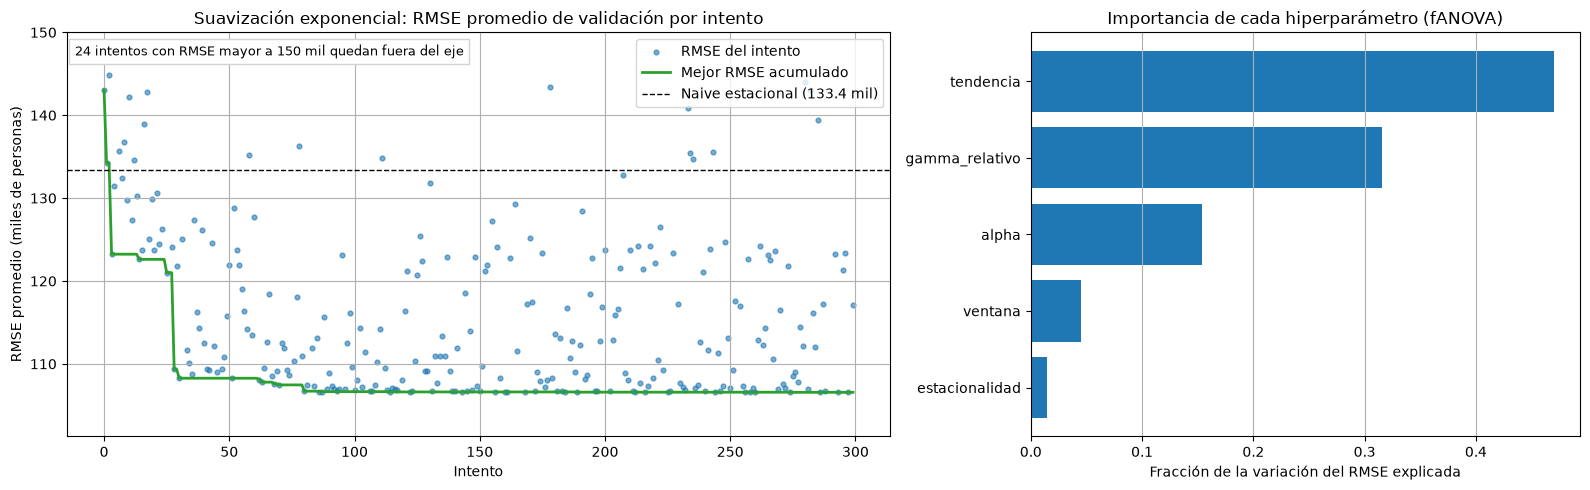


Revisión de bordes del mejor intento:
                   Valor                                  Rango En el borde
Hiperparámetro                                                             
tendencia        ninguna  ['ninguna', 'aditiva', 'amortiguada']   no aplica
estacionalidad   aditiva          ['aditiva', 'multiplicativa']   no aplica
ventana             None             [24, 36, 48, 60, 96, None]    superior
alpha           0.200455                           [0.01, 0.99]          no
gamma_relativo    0.1708                          [0.001, 0.99]          no


In [13]:
# Valores de cada hiperparámetro estructural y su traducción a los argumentos de ETSModel
TENDENCIAS_ETS = {
    "ninguna":     dict(trend=None,  damped_trend=False),
    "aditiva":     dict(trend="add", damped_trend=False),
    "amortiguada": dict(trend="add", damped_trend=True),
}
ESTACIONALIDADES_ETS = {
    "aditiva":        dict(error="add", seasonal="add"),
    "multiplicativa": dict(error="mul", seasonal="mul"),
}
VENTANAS_ETS = [24, 36, 48, 60, 96, None]   # None = ventana recursiva (toda la historia del corte)


def sugerir_configuracion_ets(trial):
    """Espacio de búsqueda de la suavización exponencial (los hiperparámetros condicionales solo
    se proponen cuando la estructura los necesita)."""
    config = {
        "tendencia": trial.suggest_categorical("tendencia", list(TENDENCIAS_ETS)),
        "estacionalidad": trial.suggest_categorical("estacionalidad", list(ESTACIONALIDADES_ETS)),
        "ventana": trial.suggest_categorical("ventana", VENTANAS_ETS),
        "alpha": trial.suggest_float("alpha", 0.01, 0.99),
        "gamma_relativo": trial.suggest_float("gamma_relativo", 0.001, 0.99),
    }
    if config["tendencia"] != "ninguna":
        config["beta_relativo"] = trial.suggest_float("beta_relativo", 0.01, 0.99)
    if config["tendencia"] == "amortiguada":
        config["phi"] = trial.suggest_float("phi", 0.80, 0.98)
    return config


def parametros_suavizacion(config):
    """Parámetros de suavización de ETSModel a partir de una configuración, con beta < alpha y gamma < 1 - alpha."""
    alpha = config["alpha"]
    parametros = {"smoothing_level": alpha, "smoothing_seasonal": config["gamma_relativo"] * (1 - alpha)}
    if "beta_relativo" in config:
        parametros["smoothing_trend"] = config["beta_relativo"] * alpha
    if "phi" in config:
        parametros["damping_trend"] = config["phi"]
    return parametros


def crear_pronostico_ets(config):
    """Función de pronóstico de una configuración ETS con parámetros de suavización fijos.

    Los estados iniciales se estiman por máxima verosimilitud en cada corte; si esa estimación
    no converge, se lanza un error y el intento se marca como fallido.
    """
    config_modelo = {**TENDENCIAS_ETS[config["tendencia"]], **ESTACIONALIDADES_ETS[config["estacionalidad"]]}
    parametros = parametros_suavizacion(config)

    def pronostico(serie_ajuste, h):
        ajuste = ajustar_ets(serie_ajuste, config_modelo, ventana=config["ventana"], parametros_fijos=parametros)
        if not ajuste.mle_retvals["converged"]:
            raise RuntimeError("la estimación de los estados iniciales no convergió")
        return ajuste.forecast(h).to_numpy()

    return pronostico


# Optimización bayesiana de la suavización exponencial
N_INTENTOS_ETS = 300
estudio_ets = optimizar(sugerir_configuracion_ets, crear_pronostico_ets, N_INTENTOS_ETS)

print("\nMejores intentos:")
print(resumir_estudio(estudio_ets).round(3).to_string())

graficar_estudio(estudio_ets, "Suavización exponencial")

print("\nRevisión de bordes del mejor intento:")
print(revisar_bordes(estudio_ets, categoricos_ordenados=("ventana",)).to_string())

### Lectura del estudio

Los 300 intentos se completaron sin fallos. En la gráfica «Suavización exponencial: RMSE promedio de validación por intento», el mejor RMSE acumulado baja rápido en los primeros 30 intentos, que incluyen los 10 iniciales al azar, y desde cerca del intento 80 se mantiene casi constante, por lo que la búsqueda se estabilizó mucho antes de terminar. Después de ese punto, muchos intentos se ubican cerca del mínimo, porque el algoritmo propone sobre todo valores parecidos a los de los mejores intentos. Los 24 intentos con errores mayores a 150 mil quedan fuera del eje.

El mejor intento obtiene un RMSE promedio de 106.57 mil personas y un MAPE de 0.86 %, y supera al naive estacional en los 6 cortes. Los 10 mejores intentos comparten la misma estructura: sin tendencia, con estacionalidad aditiva y con ventana recursiva, es decir, la misma estructura del Holt-Winters ANA del taller anterior. Lo que cambia son los parámetros de suavización: en los 10 mejores, $\alpha$ está entre 0.19 y 0.21 y la fracción de $\gamma$ entre 0.167 y 0.179, con errores entre 106.57 y 106.62 mil. Que el mínimo esté en una zona amplia, donde cambios pequeños en los parámetros casi no alteran el error, indica que el resultado no depende de un valor exacto encontrado por azar.

La gráfica de importancia de los hiperparámetros (fANOVA) de este estudio es coherente con los rasgos de la sección 2. El tipo de tendencia es el que más explica la variación del error, porque una tendencia sin amortiguar extiende el crecimiento anterior a 2016. Le siguen la fracción de $\gamma$, que controla cuánto se actualiza el patrón estacional, y $\alpha$, que controla cuánto se actualiza el nivel. La ventana y el tipo de estacionalidad explican poco: con los parámetros de suavización bien elegidos, el modelo ya da más peso a la información reciente, y en el nivel casi constante de 2016 a 2018 los efectos aditivos y multiplicativos son parecidos.

La revisión de bordes marca la ventana, porque la recursiva es la última opción de su rango. Este borde no se puede ampliar, ya que la ventana recursiva usa toda la historia disponible en cada corte. Los parámetros $\alpha$ y $\gamma$ quedaron en el interior de sus rangos, por lo que no hace falta una segunda etapa de búsqueda.

### Robustez del resultado y comparación con la máxima verosimilitud

Como los parámetros se eligieron con los mismos 6 cortes con los que se mide el error, el RMSE del mejor intento puede ser algo optimista. Se hacen tres revisiones antes de elegir el modelo de esta familia. Primero, se repite el estudio con otra semilla, para comprobar que la búsqueda llega a la misma configuración y no depende de la secuencia de intentos. Segundo, se comparan los parámetros elegidos por Optuna con los que estima la máxima verosimilitud para la misma estructura. Tercero, se compara el error por corte con el del Holt-Winters ANA del taller anterior, con el naive estacional y con el mejor modelo del taller anterior, para ver si la mejora se repite en los distintos semestres o proviene de unos pocos cortes.

Intentos: 300 | completos: 300 | fallidos: 0 | repetidos (resultado reutilizado): 0
Cortes leídos del caché: 1800 de 1800 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.00 s
Mejor RMSE promedio: 106.56 (intento 164)

Mejor intento de cada estudio:
               Semilla 2026 Semilla 2027
tendencia           ninguna      ninguna
estacionalidad      aditiva      aditiva
ventana                None         None
alpha              0.200455       0.1985
gamma_relativo       0.1708     0.172703
RMSE promedio    106.565011   106.560854

Parámetros de suavización del Holt-Winters ANA:
                        Máxima verosimilitud (taller 1)  Optuna
alpha (nivel)                                    0.5914  0.2005
gamma (estacionalidad)                           0.0000  0.1366

Resumen de la validación:
                                        RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional  Cortes mejores que Combinación ANA + regresión 

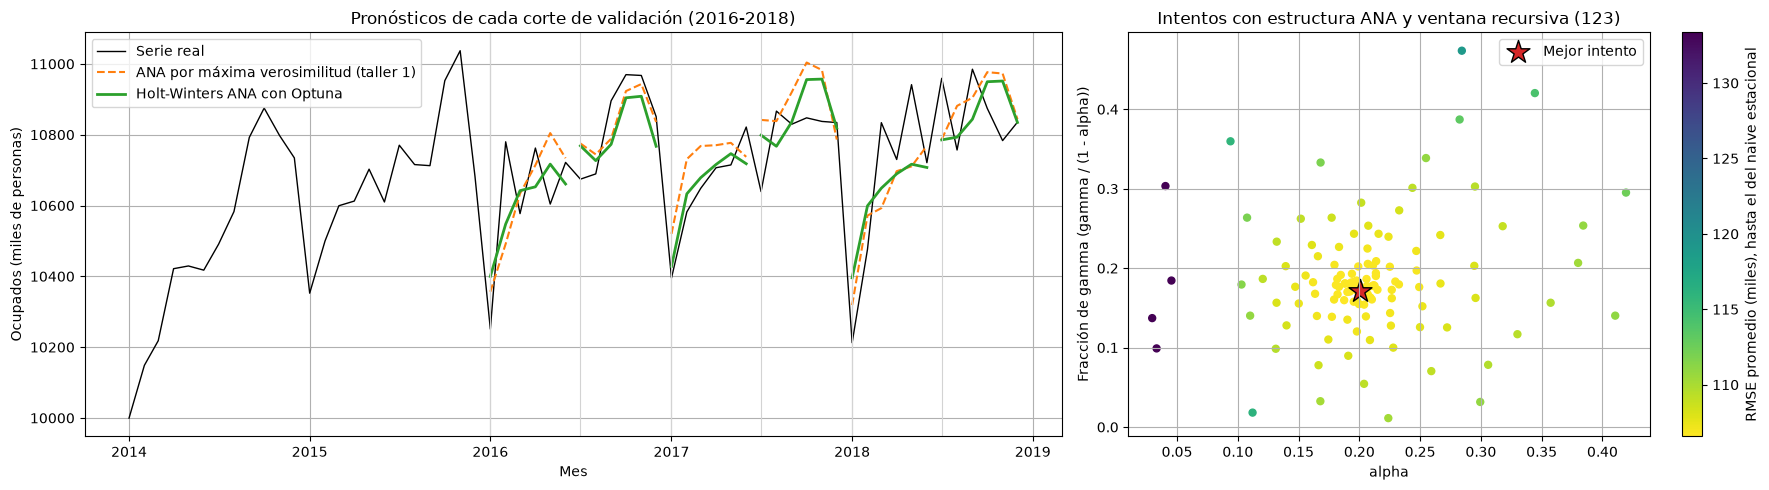

In [14]:
def parametros_estimados(ajuste):
    """Parámetros de un ajuste de statsmodels como una serie con sus nombres.

    statsmodels entrega los valores con un índice numérico y los nombres por separado (param_names).
    """
    return pd.Series(np.asarray(ajuste.params), index=ajuste.param_names)


# 1. Segundo estudio con otra semilla: ¿la búsqueda llega a la misma configuración?
estudio_ets_semilla_2 = optimizar(sugerir_configuracion_ets, crear_pronostico_ets, N_INTENTOS_ETS, semilla=SEMILLA + 1)
mejores_por_semilla = pd.DataFrame({
    f"Semilla {semilla}": {**estudio.best_trial.user_attrs["config"], "RMSE promedio": estudio.best_value}
    for semilla, estudio in [(SEMILLA, estudio_ets), (SEMILLA + 1, estudio_ets_semilla_2)]
})
print("\nMejor intento de cada estudio:")
print(mejores_por_semilla.to_string())

# 2. Registro del mejor intento del primer estudio como modelo de la familia
NOMBRE_ETS_OPTUNA = "Holt-Winters ANA con Optuna"
config_ets = registrar_mejor(estudio_ets, NOMBRE_ETS_OPTUNA, "Suavización exponencial", crear_pronostico_ets)
assert (config_ets["tendencia"], config_ets["estacionalidad"]) == ("ninguna", "aditiva"), "La estructura no es ANA"

# Parámetros de suavización con todo el entrenamiento: máxima verosimilitud frente a Optuna (misma estructura ANA)
parametros_mle = parametros_estimados(ajustar_ets(train, CONFIG_ANA))
parametros_optuna = parametros_suavizacion(config_ets)
tabla_parametros = pd.DataFrame({
    "Máxima verosimilitud (taller 1)": [parametros_mle["smoothing_level"], parametros_mle["smoothing_seasonal"]],
    "Optuna": [parametros_optuna["smoothing_level"], parametros_optuna["smoothing_seasonal"]],
}, index=["alpha (nivel)", "gamma (estacionalidad)"])
print("\nParámetros de suavización del Holt-Winters ANA:")
print(tabla_parametros.round(4).to_string())

# 3. Error por corte frente al ANA del taller anterior y a las dos referencias
modelos_comparacion_ets = ["Naive estacional", "Holt-Winters ANA (taller 1)", CAMPEON_TALLER_1, NOMBRE_ETS_OPTUNA]
print("\nResumen de la validación:")
print(resumir_validacion(modelos_comparacion_ets, referencias=("Naive estacional", CAMPEON_TALLER_1))
      .round(2).to_string())
print("\nRMSE por corte (miles):")
print(error_por_corte(modelos_comparacion_ets).round(1).to_string())

# Gráficas: pronósticos de cada corte de ambos ANA, y mapa del error según alpha y la fracción de gamma
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [3, 2]})

axes[0].plot(train.loc["2014":], color="black", linewidth=1, label="Serie real")
for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    serie_ajuste = train.iloc[idx_ajuste]
    fechas_validacion = train.index[idx_validacion]
    axes[0].plot(fechas_validacion, pronostico_ana(serie_ajuste, horizonte), color="C1", linestyle="--",
                 label="ANA por máxima verosimilitud (taller 1)" if numero == 1 else None)
    axes[0].plot(fechas_validacion, funciones_pronostico[NOMBRE_ETS_OPTUNA](serie_ajuste, horizonte),
                 color="C2", linewidth=2, label=NOMBRE_ETS_OPTUNA if numero == 1 else None)
    axes[0].axvline(fechas_validacion[0], color="lightgray", linewidth=0.8)
axes[0].set_title("Pronósticos de cada corte de validación (2016-2018)")
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Ocupados (miles de personas)")
axes[0].legend(loc="upper left")
axes[0].grid()

# Intentos con la estructura elegida (ANA, ventana recursiva): error según alpha y la fracción de gamma
intentos_ana = [t for t in estudio_ets.trials
                if t.state == optuna.trial.TrialState.COMPLETE and not t.user_attrs.get("repetido")
                and t.params["tendencia"] == "ninguna" and t.params["estacionalidad"] == "aditiva"
                and t.params["ventana"] is None]
puntos = axes[1].scatter([t.params["alpha"] for t in intentos_ana], [t.params["gamma_relativo"] for t in intentos_ana],
                         c=[t.value for t in intentos_ana], cmap="viridis_r", s=25,
                         vmax=validacion["Naive estacional"]["rmse"].mean())
axes[1].scatter(config_ets["alpha"], config_ets["gamma_relativo"], marker="*", s=300, color="C3",
                edgecolor="black", label="Mejor intento")
fig.colorbar(puntos, ax=axes[1], label="RMSE promedio (miles), hasta el del naive estacional")
axes[1].set_title(f"Intentos con estructura ANA y ventana recursiva ({len(intentos_ana)})")
axes[1].set_xlabel("alpha")
axes[1].set_ylabel("Fracción de gamma (gamma / (1 - alpha))")
axes[1].legend(loc="upper right")
axes[1].grid()

fig.tight_layout()
plt.show()

### Resultados de la robustez y elección del modelo de suavización exponencial

**Segunda semilla.** El estudio con la semilla 2027 llega a la misma estructura (sin tendencia, estacionalidad aditiva y ventana recursiva) y a parámetros casi iguales: $\alpha = 0.199$ frente a 0.200, y una fracción de $\gamma$ de 0.173 frente a 0.171, con un RMSE de 106.56 frente a 106.57 mil. La configuración elegida no depende de la secuencia de intentos.

**Parámetros frente a la máxima verosimilitud.** Con la misma estructura ANA y todo el entrenamiento, los parámetros cambian de forma importante:

| Parámetro | Máxima verosimilitud (taller 1) | Optuna |
|---|---|---|
| $\alpha$ (nivel) | 0.5914 | 0.2005 |
| $\gamma$ (estacionalidad) | 0.0000 | 0.1366 |

La máxima verosimilitud, que minimiza el error a un mes, elige un nivel que se actualiza rápido y un patrón estacional fijo. Optuna, que minimiza el error a 6 meses, elige lo contrario: un nivel que se actualiza más despacio y un patrón estacional que se actualiza con cada año. Una explicación coherente con los rasgos de la sección 2 es la siguiente. En un pronóstico a 6 meses, todos los meses parten del nivel estimado en el corte; con $\alpha = 0.59$, ese nivel sigue de cerca al último mes observado, y si ese mes es atípico, el error se traslada a los 6 meses pronosticados. Con $\gamma > 0$, en cambio, el modelo puede incorporar el cambio del patrón estacional que se observó en la caída de enero, en lugar de mantener el promedio de toda la historia. En la gráfica «Intentos con estructura ANA y ventana recursiva», los intentos con menor error forman una zona amplia alrededor de $\alpha \approx 0.2$ y una fracción de $\gamma$ entre 0.1 y 0.3, mientras que los valores de $\alpha$ menores a 0.05 tienen errores cercanos al del naive estacional.

**Error por corte.**

| Inicio del corte | Naive estacional | ANA (taller 1) | Combinación (taller 1) | ANA con Optuna |
|---|---|---|---|---|
| 2016-01 | 149.4 | 152.8 | 152.3 | **134.6** |
| 2016-07 | 113.5 | 67.8 | **53.3** | 81.8 |
| 2017-01 | 122.8 | 105.8 | 77.2 | **52.3** |
| 2017-07 | 107.3 | 127.6 | 124.3 | **101.2** |
| 2018-01 | 153.3 | **150.1** | 161.5 | **150.1** |
| 2018-07 | 153.9 | 128.0 | 130.2 | **119.4** |
| **RMSE promedio** | 133.36 | 122.02 | 116.47 | **106.57** |
| **MAPE promedio (%)** | 1.05 | 0.98 | 0.92 | **0.86** |

*RMSE en miles de personas.*

El ANA con Optuna reduce el RMSE promedio del ANA del taller anterior en cerca de 12.7 %, y el del mejor modelo del taller anterior en cerca de 8.5 %. La mejora se repite en casi todos los semestres: es el primer modelo que supera al naive estacional en los 6 cortes, mejora al ANA del taller anterior en 4 cortes y lo iguala en enero de 2018, y supera a la combinación del taller anterior en 5 de los 6 cortes. La excepción es julio de 2016, donde su error (81.8 mil) es mayor que el de los dos modelos del taller anterior; en ese semestre, el nivel que se actualiza más despacio reaccionó más tarde a los datos del primer semestre de 2016. En la gráfica «Pronósticos de cada corte de validación (2016-2018)» de esta sección, los pronósticos de Optuna quedan en general más cerca de la serie real al inicio de cada corte y en los máximos de fin de año.

Hay que tener en cuenta que los parámetros se eligieron con los mismos 6 cortes con los que se mide el error, después de evaluar 300 configuraciones, por lo que el RMSE de 106.57 mil es probablemente algo optimista. La muestra de prueba, que no se ha usado, servirá para comprobar si la mejora se mantiene.

Se elige el **Holt-Winters aditivo sin tendencia (ANA) con parámetros de suavización ajustados por Optuna** ($\alpha = 0.200$, $\gamma = 0.137$, ventana recursiva) como el mejor modelo de suavización exponencial. Tiene el menor RMSE y el menor MAPE de la familia, supera a las dos referencias en la mayoría de los cortes, y su configuración se repite con otra semilla.

### Conclusión de la Parte I

La optimización bayesiana conservó la estructura del mejor modelo de suavización exponencial del taller anterior, un Holt-Winters aditivo sin tendencia con ventana recursiva, pero cambió sus parámetros: un nivel que se actualiza más despacio y un patrón estacional que se actualiza cada año. Elegir los parámetros con el error de pronóstico a 6 meses, en lugar de la verosimilitud a un mes, reduce el RMSE promedio de validación a 106.57 mil personas, el menor obtenido hasta ahora, y es el primer modelo que supera al naive estacional en los 6 cortes.

# Parte II — Modelos ARIMA

## 6. Identificación: estacionariedad y autocorrelaciones

Un modelo ARIMA describe cada valor de la serie a partir de sus valores y errores anteriores, y requiere que la serie, o alguna de sus diferencias, sea estacionaria: con media y varianza constantes y una dependencia entre meses que no cambia en el tiempo. La serie de ocupados no lo es en su nivel, porque tiene tendencia y un patrón estacional. Las dos transformaciones habituales son la primera diferencia, $\Delta y_t = y_t - y_{t-1}$, que elimina la tendencia, y la diferencia estacional, $\Delta_{12}\, y_t = y_t - y_{t-12}$, que compara cada mes con el mismo mes del año anterior y elimina el patrón estacional.

Para elegir el orden de diferenciación se aplican dos pruebas complementarias a la serie de entrenamiento y a sus diferencias:

- **Dickey-Fuller aumentada (ADF):** la hipótesis nula es que la serie tiene raíz unitaria (no es estacionaria).
- **KPSS:** la hipótesis nula es que la serie es estacionaria.

La regla de decisión se fija antes de ver los resultados: una transformación se considera estacionaria si la prueba ADF rechaza la raíz unitaria y la prueba KPSS no rechaza la estacionariedad, ambas con un nivel de 0.05, y se prefiere la que lo logra con menos diferencias. Como complemento, se reportan los órdenes de diferenciación que sugieren las pruebas automáticas de pmdarima, incluida una prueba de raíz unitaria estacional. Las pruebas dan indicios y no una conclusión definitiva, porque el cambio de tendencia de 2016 puede afectarlas; por eso, los órdenes de diferenciación no se fijan aquí, sino que se usan para acotar el espacio de búsqueda de la sección siguiente, donde la validación decide.

Pruebas de estacionariedad sobre el entrenamiento:
                              Observaciones ADF p-valor KPSS p-valor ADF rechaza raíz unitaria KPSS no rechaza estacionariedad Estacionaria según la regla
Nivel (y)                               216      0.6822       0.0100                     False                           False                       False
Primera diferencia (Δy)                 215      0.0098       0.1000                      True                            True                        True
Diferencia estacional (Δ12 y)           204      0.4995       0.0959                     False                            True                       False
Ambas diferencias (Δ Δ12 y)             203      0.0000       0.1000                      True                            True                        True

Órdenes de diferenciación sugeridos por pmdarima:
  d (ADF):  1  |  d (KPSS): 1
  D (OCSB): 0  |  D (Canova-Hansen): 0


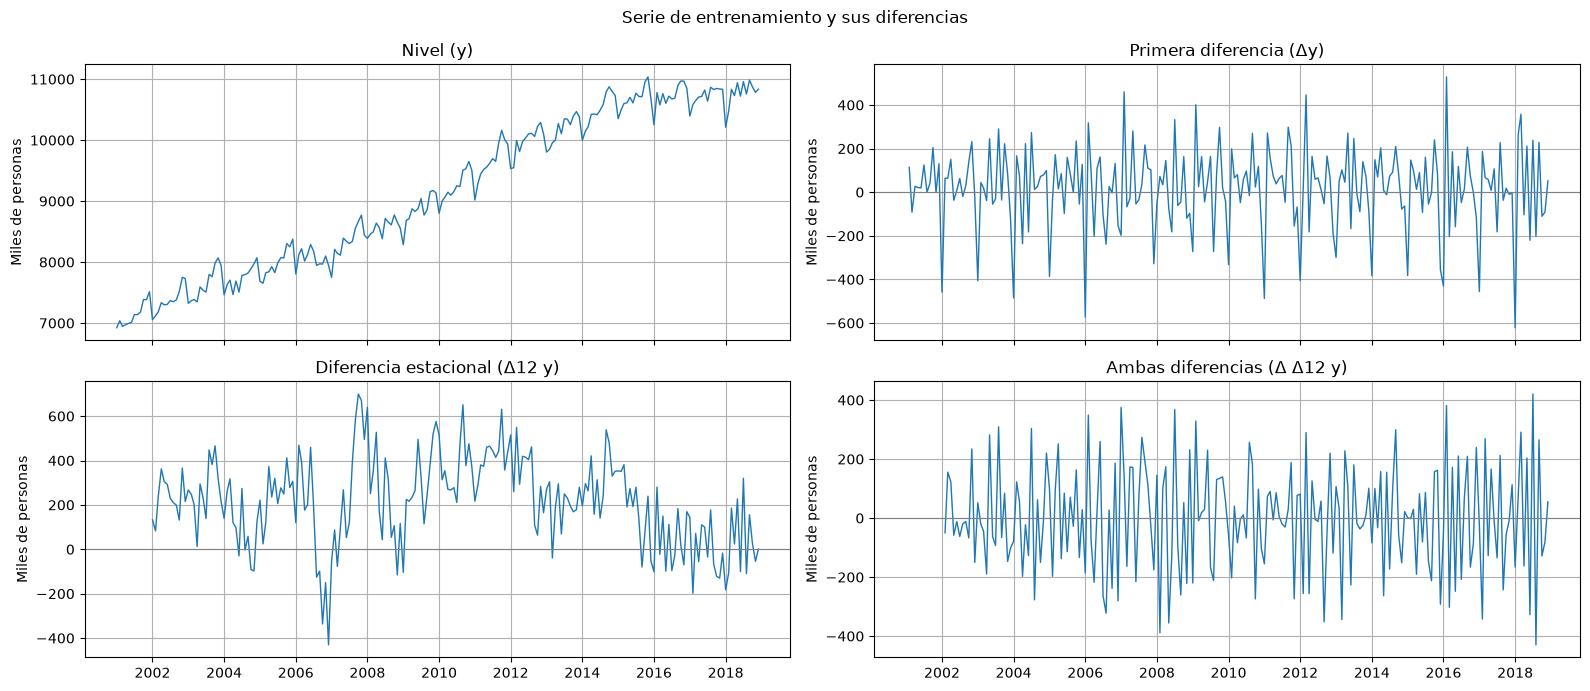

In [15]:
# Serie de entrenamiento y sus diferencias (se eliminan los valores iniciales que la diferencia deja vacíos)
transformaciones = {
    "Nivel (y)": train,
    "Primera diferencia (Δy)": train.diff().dropna(),
    "Diferencia estacional (Δ12 y)": train.diff(12).dropna(),
    "Ambas diferencias (Δ Δ12 y)": train.diff(12).diff().dropna(),
}


def pruebas_estacionariedad(serie, alfa=0.05):
    """Pruebas ADF (H0: raíz unitaria) y KPSS (H0: estacionariedad) con la regla de decisión de la sección.

    KPSS solo tabula p-valores entre 0.01 y 0.10: fuera de ese rango devuelve el extremo y emite un
    aviso, que se silencia porque la decisión con un nivel de 0.05 no cambia. result_object=False
    mantiene el resultado como tupla, que es el comportamiento actual de statsmodels.
    """
    p_adf = adfuller(serie, regression="c", autolag="AIC", result_object=False)[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        p_kpss = kpss(serie, regression="c", nlags="auto", result_object=False)[1]
    return {
        "Observaciones": len(serie),
        "ADF p-valor": p_adf,
        "KPSS p-valor": p_kpss,
        "ADF rechaza raíz unitaria": p_adf < alfa,
        "KPSS no rechaza estacionariedad": p_kpss >= alfa,
        "Estacionaria según la regla": (p_adf < alfa) and (p_kpss >= alfa),
    }


tabla_estacionariedad = pd.DataFrame({nombre: pruebas_estacionariedad(serie)
                                      for nombre, serie in transformaciones.items()}).T
print("Pruebas de estacionariedad sobre el entrenamiento:")
print(tabla_estacionariedad.to_string(formatters={"ADF p-valor": "{:.4f}".format, "KPSS p-valor": "{:.4f}".format}))

# Órdenes sugeridos por pmdarima: d con ADF y KPSS, y D con las pruebas estacionales OCSB y Canova-Hansen
print("\nÓrdenes de diferenciación sugeridos por pmdarima:")
print(f"  d (ADF):  {ndiffs(train, test='adf')}  |  d (KPSS): {ndiffs(train, test='kpss')}")
print(f"  D (OCSB): {nsdiffs(train, m=12, test='ocsb')}  |  D (Canova-Hansen): {nsdiffs(train, m=12, test='ch')}")

# Gráfica de la serie y de sus tres diferencias
fig, axes = plt.subplots(2, 2, figsize=(16, 7), sharex=True)
for ax, (nombre, serie) in zip(axes.flat, transformaciones.items()):
    ax.plot(serie, linewidth=1)
    if nombre != "Nivel (y)":
        ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(nombre)
    ax.set_ylabel("Miles de personas")
    ax.grid()
fig.suptitle("Serie de entrenamiento y sus diferencias")
fig.tight_layout()
plt.show()

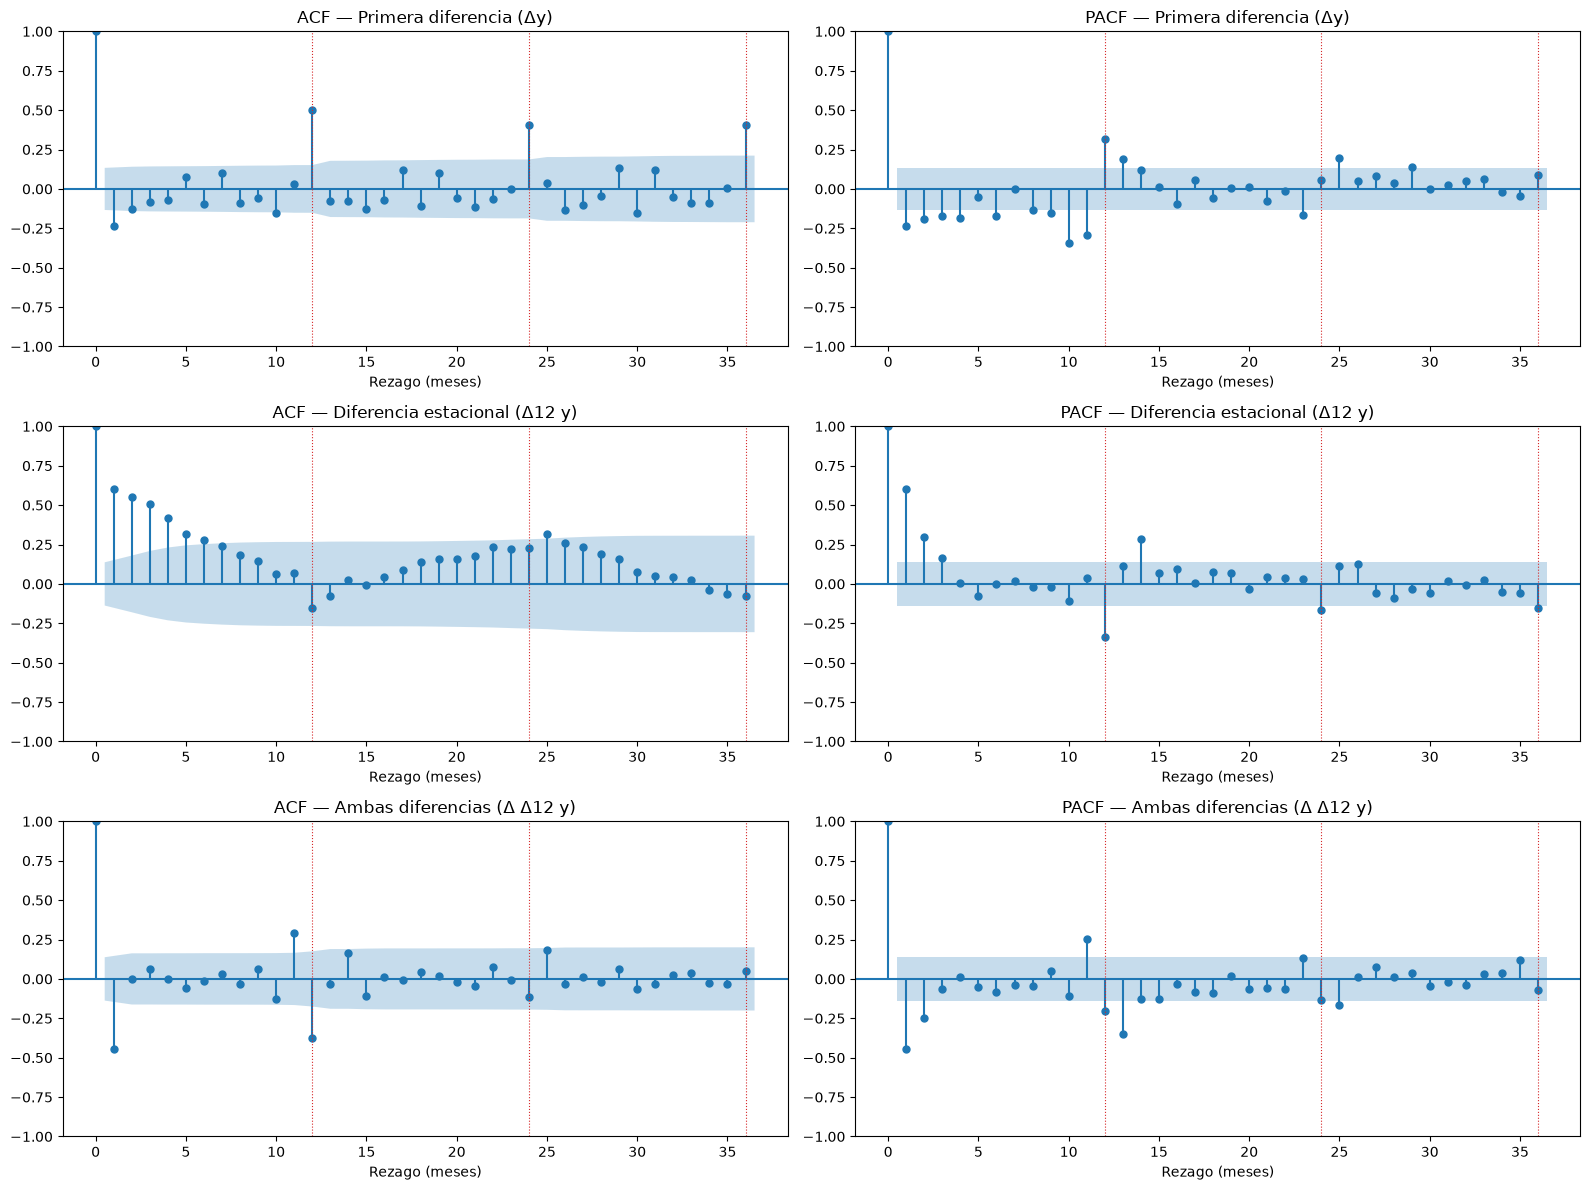

Banda aproximada de la PACF: ±0.134

Autocorrelaciones en los rezagos clave:
          Primera diferencia (Δy)        Diferencia estacional (Δ12 y)        Ambas diferencias (Δ Δ12 y)       
                              ACF   PACF                           ACF   PACF                         ACF   PACF
Rezago 1                   -0.232 -0.232                         0.599  0.599                      -0.444 -0.444
Rezago 2                   -0.124 -0.189                         0.550  0.297                      -0.003 -0.249
Rezago 3                   -0.081 -0.175                         0.506  0.165                       0.062 -0.066
Rezago 6                   -0.095 -0.171                         0.281 -0.003                      -0.011 -0.084
Rezago 11                   0.034 -0.290                         0.071  0.040                       0.291  0.251
Rezago 12                   0.499  0.319                        -0.153 -0.336                      -0.372 -0.204
Rezago 13          

In [16]:
# ACF y PACF de las tres diferencias, hasta 36 rezagos (3 años). El nivel no se incluye porque
# no es estacionario, y su ACF quedaría dominada por la tendencia.
diferencias = ["Primera diferencia (Δy)", "Diferencia estacional (Δ12 y)", "Ambas diferencias (Δ Δ12 y)"]
rezagos_clave = [1, 2, 3, 6, 11, 12, 13, 24, 36]

fig, axes = plt.subplots(len(diferencias), 2, figsize=(16, 4 * len(diferencias)))
valores_autocorrelacion = {}
for fila, nombre in enumerate(diferencias):
    serie = transformaciones[nombre]
    plot_acf(serie, lags=36, ax=axes[fila, 0], title=f"ACF — {nombre}")
    plot_pacf(serie, lags=36, ax=axes[fila, 1], method="ywm", title=f"PACF — {nombre}")
    for ax in axes[fila]:
        ax.set_xlabel("Rezago (meses)")
        for rezago_estacional in (12, 24, 36):
            ax.axvline(rezago_estacional, color="C3", linestyle=":", linewidth=0.8)
    valores_autocorrelacion[(nombre, "ACF")] = acf(serie, nlags=36)[rezagos_clave]
    valores_autocorrelacion[(nombre, "PACF")] = pacf(serie, nlags=36, method="ywm")[rezagos_clave]
fig.tight_layout()
plt.show()

# Banda aproximada de significancia al 95 % para la PACF (la de la ACF se ensancha con el rezago)
print(f"Banda aproximada de la PACF: ±{1.96 / np.sqrt(len(transformaciones[diferencias[0]])):.3f}")
print("\nAutocorrelaciones en los rezagos clave:")
print(pd.DataFrame(valores_autocorrelacion, index=[f"Rezago {r}" for r in rezagos_clave]).round(3).to_string())

### Lectura de la identificación

**Orden de diferenciación no estacional ($d$).** La serie en niveles no es estacionaria: la prueba ADF no rechaza la raíz unitaria (p-valor de 0.68) y la KPSS rechaza la estacionariedad (p-valor de 0.01 o menor). Con una primera diferencia, las dos pruebas coinciden en que la serie es estacionaria (p-valores de 0.0098 en ADF y de 0.10 o más en KPSS), y las dos pruebas de pmdarima sugieren $d = 1$. La diferencia estacional por sí sola no basta: la prueba ADF no rechaza la raíz unitaria (p-valor de 0.50); en la gráfica «ACF — Diferencia estacional (Δ12 y)», la autocorrelación baja lentamente desde 0.60 en el rezago 1; y en el panel «Diferencia estacional (Δ12 y)» de la gráfica «Serie de entrenamiento y sus diferencias», la serie diferenciada cambia de nivel, con valores altos entre 2008 y 2012 y cercanos a cero desde 2016, el mismo cambio de régimen de la sección 2. Por eso, los modelos usarán una primera diferencia ($d = 1$).

**Orden de diferenciación estacional ($D$).** Aquí la evidencia no es concluyente. Las pruebas estacionales de pmdarima (OCSB y Canova-Hansen) sugieren $D = 0$, es decir, un patrón estacional estable que no requiere diferenciación. Sin embargo, en la gráfica «ACF — Primera diferencia (Δy)», las autocorrelaciones en los rezagos estacionales son altas y casi no decaen: 0.50 en el rezago 12, 0.41 en el 24 y 0.41 en el 36. Esa persistencia puede representarse de dos formas: con $D = 0$ y términos autorregresivos estacionales, o con $D = 1$. Como las dos opciones son razonables, $D$ no se fija aquí, y entra en la búsqueda con los valores 0 y 1.

**Órdenes ARMA.** Con ambas diferencias, que es la transformación con menos autocorrelación remanente, la gráfica «ACF — Ambas diferencias (Δ Δ12 y)» tiene dos valores claramente significativos: -0.44 en el rezago 1 y -0.37 en el rezago 12, con un valor de 0.29 en el rezago 11 que acompaña al del rezago 12. La gráfica «PACF — Ambas diferencias (Δ Δ12 y)», en cambio, decae: -0.44 y -0.25 en los rezagos 1 y 2, y -0.35 en el rezago 13. Una ACF que se corta en los rezagos 1 y 12 junto con una PACF que decae es el patrón de un componente MA(1) no estacional y un MA(1) estacional, es decir, un $\text{SARIMA}(0,1,1)(0,1,1)_{12}$. Con la primera diferencia sola, la gráfica «PACF — Primera diferencia (Δy)» tiene valores significativos en varios rezagos de corto plazo y en el rezago 12, coherente con términos autorregresivos de bajo orden y un AR estacional.

En resumen, la identificación sugiere $d = 1$, deja abierto $D$ entre 0 y 1, y apunta a órdenes ARMA bajos: hasta 2 o 3 en la parte no estacional y hasta 1 o 2 en la estacional. Estos indicios acotan el espacio de búsqueda de la sección siguiente, en la que la validación decide entre las alternativas.

## 7. ARIMA y SARIMA con optimización bayesiana

Un modelo $\text{SARIMA}(p,d,q)(P,D,Q)_{12}$ combina una parte no estacional, con $p$ términos autorregresivos y $q$ de media móvil sobre la serie con $d$ diferencias, y una parte estacional, con $P$ y $Q$ términos que relacionan cada mes con el mismo mes de años anteriores, después de $D$ diferencias estacionales. Cuando $P = D = Q = 0$, el modelo es un ARIMA sin componente estacional, de modo que la misma búsqueda evalúa modelos con y sin parte estacional, y los datos deciden si esa parte hace falta.

A diferencia de la suavización exponencial, aquí la optimización bayesiana elige la especificación del modelo (los órdenes, la escala y la ventana), y los coeficientes de cada especificación se estiman por máxima verosimilitud en cada corte. El espacio de búsqueda se define a partir de la identificación de la sección anterior:

| Hiperparámetro | Valores | Justificación |
|---|---|---|
| $d$ | 1 (fijo) | Las pruebas ADF y KPSS coinciden en que basta una primera diferencia |
| $D$ | 0 o 1 | Las pruebas estacionales sugieren 0, pero la ACF de la primera diferencia muestra una estacionalidad muy persistente |
| $p$, $q$ | 0 a 3 | La ACF y la PACF de la serie diferenciada sugieren órdenes no estacionales de 1 a 2; se agrega un orden más para revisar el borde |
| $P$, $Q$ | 0 a 2 | Autocorrelaciones significativas en los rezagos 12 y 24 |
| Término determinístico | sin constante o con deriva, solo si $D = 0$ | Con $d = 1$, una constante equivale a una tendencia lineal en el nivel. Con $D = 1$ se omite, porque implicaría una tendencia cuadrática |
| Escala | original o logarítmica | Versión aditiva o multiplicativa de la estacionalidad: en escala logarítmica, los efectos estacionales son proporcionales al nivel, y los rasgos de la sección 2 no permiten descartar ninguna de las dos |
| Ventana de estimación | 48, 60 o 96 meses, o recursiva | Con diferenciación estacional y términos estacionales de orden 2, una ventana de 24 meses deja muy pocas observaciones efectivas para estimar los coeficientes |

Los coeficientes se restringen a la región estacionaria e invertible y se estiman con el optimizador L-BFGS; si este no converge, se intenta con Powell, que no usa gradientes y es más estable cuando la verosimilitud es muy plana. Si ninguno converge en algún corte, el intento se marca como fallido. En escala logarítmica, el pronóstico se devuelve a miles de personas con la exponencial, que corresponde a la mediana del pronóstico; con errores cercanos al 1 %, la diferencia con la media es despreciable.

Intentos: 200 | completos: 196 | fallidos: 4 | repetidos (resultado reutilizado): 81
Cortes leídos del caché: 690 de 690 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.01 s
Motivos de los intentos fallidos:
LinAlgError: LU decomposition error.    4
Mejor RMSE promedio: 122.65 (intento 95)

Mejores intentos:
         p  d  q  P  D  Q    escala  ventana tendencia  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Intento                                                                                                                      
95       2  1  2  2  0  0       log     96.0         n        122.650              0.972                                    4
93       1  1  2  2  0  0       log     96.0         n        123.984              0.993                                    4
85       0  1  2  2  0  0       log     96.0         n        124.231              0.981                                    4
115      2  1  3  2  0

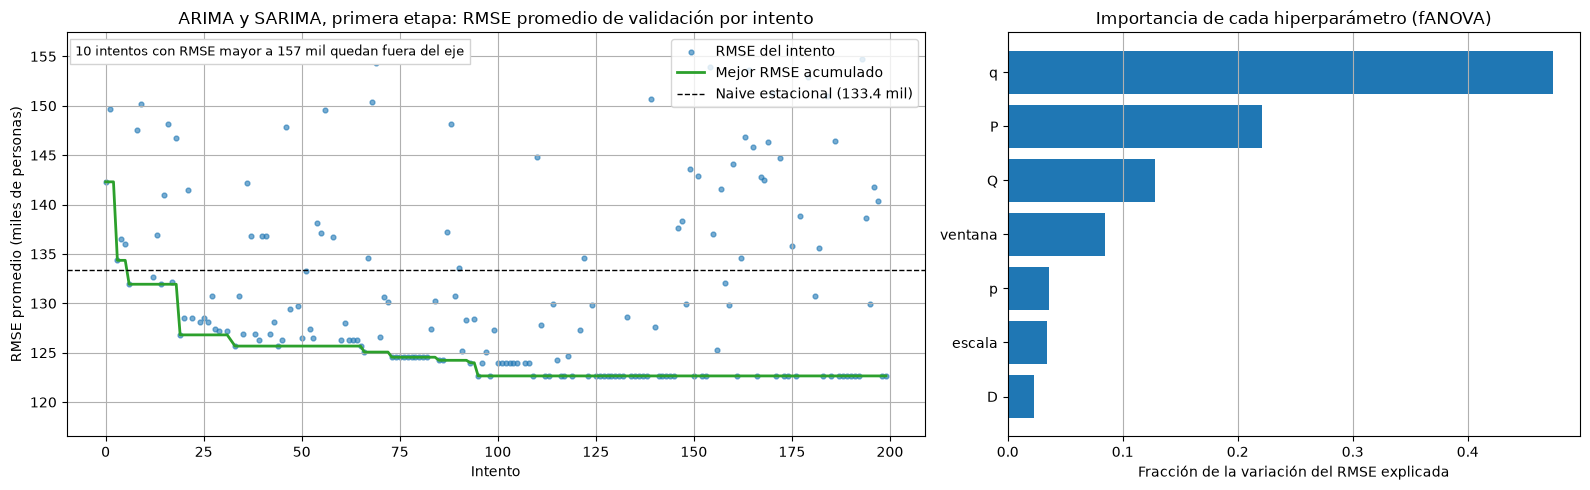


Revisión de bordes del mejor intento:
               Valor                Rango En el borde
Hiperparámetro                                       
p                  2               [0, 3]          no
q                  2               [0, 3]          no
P                  2               [0, 2]    superior
D                  0               [0, 1]   no aplica
Q                  0               [0, 2]          no
escala           log  ['original', 'log']   no aplica
ventana           96   [48, 60, 96, None]          no
tendencia          n           ['n', 'c']   no aplica


In [17]:
VENTANAS_SARIMA = [48, 60, 96, None]   # None = ventana recursiva
ESTACIONALIDAD_SARIMA = 12
# statsmodels usa por defecto L-BFGS con 50 iteraciones, que no alcanzan para converger en modelos
# con términos estacionales. Se usan hasta 500 iteraciones y, si L-BFGS no converge (por ejemplo,
# cuando la verosimilitud es muy plana cerca del borde de la región invertible), se intenta con
# Powell, que no usa gradientes. Así, un fallo indica un problema de la especificación y no del optimizador.
MAX_ITERACIONES_SARIMA = 500
OPTIMIZADORES_SARIMA = ("lbfgs", "powell")


def espacio_sarima(max_p=3, max_q=3, max_P=2, max_Q=2):
    """Devuelve la función que define el espacio de búsqueda de ARIMA y SARIMA con los órdenes máximos
    indicados. Los valores por defecto son los de la primera etapa, acotados con la sección 6."""
    def sugerir_configuracion_sarima(trial):
        config = {
            "p": trial.suggest_int("p", 0, max_p),
            "d": 1,
            "q": trial.suggest_int("q", 0, max_q),
            "P": trial.suggest_int("P", 0, max_P),
            "D": trial.suggest_int("D", 0, 1),
            "Q": trial.suggest_int("Q", 0, max_Q),
            "escala": trial.suggest_categorical("escala", ["original", "log"]),
            "ventana": trial.suggest_categorical("ventana", VENTANAS_SARIMA),
        }
        # Con D = 1 no se incluye término determinístico; con D = 0 se elige entre sin constante y con deriva
        config["tendencia"] = trial.suggest_categorical("tendencia", ["n", "c"]) if config["D"] == 0 else "n"
        return config

    return sugerir_configuracion_sarima


def ordenes_sarima(config):
    """Órdenes no estacional y estacional de SARIMAX; si no hay parte estacional, el modelo es un ARIMA."""
    orden_estacional = (config["P"], config["D"], config["Q"], ESTACIONALIDAD_SARIMA)
    if orden_estacional[:3] == (0, 0, 0):
        orden_estacional = (0, 0, 0, 0)
    return (config["p"], config["d"], config["q"]), orden_estacional


def ajustar_sarima(serie_ajuste, config):
    """Estima por máxima verosimilitud un SARIMA con la configuración indicada.

    Respeta la ventana de estimación y la escala de la configuración. Prueba los optimizadores de
    OPTIMIZADORES_SARIMA en orden y devuelve el primer ajuste que converge; si ninguno converge,
    lanza un error. Los avisos de statsmodels durante la estimación se silencian, porque la
    convergencia se revisa aquí.
    """
    if config["ventana"] is not None:
        serie_ajuste = serie_ajuste.iloc[-config["ventana"]:]
    y = np.log(serie_ajuste) if config["escala"] == "log" else serie_ajuste
    orden, orden_estacional = ordenes_sarima(config)
    modelo = SARIMAX(y, order=orden, seasonal_order=orden_estacional, trend=config["tendencia"],
                     enforce_stationarity=True, enforce_invertibility=True)
    for optimizador in OPTIMIZADORES_SARIMA:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ajuste = modelo.fit(disp=False, method=optimizador, maxiter=MAX_ITERACIONES_SARIMA)
        if ajuste.mle_retvals.get("converged", False):
            return ajuste
    raise RuntimeError("la estimación por máxima verosimilitud no convergió con ningún optimizador")


def crear_pronostico_sarima(config):
    """Función de pronóstico de una configuración SARIMA, en miles de personas."""
    def pronostico(serie_ajuste, h):
        prediccion = np.asarray(ajustar_sarima(serie_ajuste, config).forecast(h))
        # En escala logarítmica, la exponencial devuelve el pronóstico a miles de personas
        return np.exp(prediccion) if config["escala"] == "log" else prediccion

    return pronostico


# Argumentos de la revisión de bordes de SARIMA: los órdenes pueden valer 0, que es su mínimo
# posible, y D solo admite 0 o 1, de modo que en él no hay borde que ampliar
BORDES_SARIMA = dict(categoricos_ordenados=("ventana",), minimos_naturales=("p", "q", "P", "Q"),
                     sin_ampliacion=("D",))

# Primera etapa de la optimización bayesiana de ARIMA y SARIMA
N_INTENTOS_SARIMA = 200
estudio_sarima = optimizar(espacio_sarima(), crear_pronostico_sarima, N_INTENTOS_SARIMA)

print("\nMejores intentos:")
print(resumir_estudio(estudio_sarima).round(3).to_string())

graficar_estudio(estudio_sarima, "ARIMA y SARIMA, primera etapa")

print("\nRevisión de bordes del mejor intento:")
print(revisar_bordes(estudio_sarima, **BORDES_SARIMA).to_string())

In [18]:
def diagnosticar_fallos(estudio, hiperparametros=("D", "escala", "p", "q", "P", "Q", "ventana")):
    """Proporción de configuraciones distintas que no se pudieron estimar, según cada hiperparámetro.

    Si los fallos se concentran en ciertos valores, la búsqueda explora menos esa parte del espacio,
    y conviene tenerlo en cuenta al leer el resultado. Devuelve la tabla con un bloque por hiperparámetro.
    """
    intentos = pd.DataFrame([
        {**t.params, "Falló": "error" in t.user_attrs}
        for t in estudio.trials if not t.user_attrs.get("repetido")
    ])
    # La ventana recursiva se guarda como None; se convierte a texto para poder agruparla
    intentos["ventana"] = ["recursiva" if pd.isna(ventana) else str(int(ventana)) for ventana in intentos["ventana"]]
    tabla = pd.concat({
        hiperparametro: intentos.groupby(hiperparametro)["Falló"].agg(Evaluadas="size", Fallidas="sum")
        for hiperparametro in hiperparametros
    }, names=["Hiperparámetro", "Valor"])
    tabla["% fallidas"] = 100 * tabla["Fallidas"] / tabla["Evaluadas"]
    print(f"Configuraciones distintas evaluadas: {len(intentos)} | fallidas: {intentos['Falló'].sum()}")
    return tabla


print(diagnosticar_fallos(estudio_sarima).round(1).to_string())

Configuraciones distintas evaluadas: 119 | fallidas: 4
                          Evaluadas  Fallidas  % fallidas
Hiperparámetro Valor                                     
D              0                 95         4         4.2
               1                 24         0         0.0
escala         log               64         0         0.0
               original          55         4         7.3
p              0                 33         1         3.0
               1                 29         0         0.0
               2                 36         3         8.3
               3                 21         0         0.0
q              0                 20         1         5.0
               1                 38         2         5.3
               2                 42         1         2.4
               3                 19         0         0.0
P              0                 18         0         0.0
               1                 27         0         0.0
               2 

### Lectura de la primera etapa

De los 200 intentos, 119 corresponden a configuraciones distintas y los demás repiten configuraciones ya evaluadas, porque el espacio es discreto y el algoritmo vuelve a proponer las que tienen menor error. Solo 4 configuraciones fallaron, cada una una sola vez, todas por un error numérico en la estimación (una descomposición LU) y no por falta de convergencia. Las 4 tienen $D = 0$, escala original y dos términos autorregresivos estacionales; con tan pocos fallos, ninguna región del espacio quedó sin explorar.

El mejor intento es un $\text{SARIMA}(2,1,2)(2,0,0)_{12}$ en escala logarítmica, sin término determinístico y estimado con los últimos 96 meses, con un RMSE promedio de 122.65 mil personas y un MAPE de 0.97 %. Supera al naive estacional (133.36 mil) en 4 de los 6 cortes, pero su error es mayor que el del mejor modelo del taller anterior (116.47 mil) y que el del Holt-Winters ANA con Optuna (106.57 mil). En la gráfica «ARIMA y SARIMA, primera etapa: RMSE promedio de validación por intento», el mejor RMSE acumulado baja por escalones hasta cerca del intento 95 y desde allí no cambia, y en los últimos 100 intentos el algoritmo vuelve muchas veces a esa configuración.

Los 10 mejores intentos comparten varios rasgos: todos tienen $D = 0$, dos términos autorregresivos estacionales ($P = 2$), ningún término de media móvil estacional ($Q = 0$) y ningún término determinístico; ocho usan la escala logarítmica y nueve la ventana de 96 meses. Que todos los mejores tengan $D = 0$ es coherente con las pruebas estacionales de la sección 6: la persistencia de los rezagos 12, 24 y 36 se representa mejor con términos autorregresivos estacionales que con una diferencia estacional. Que ninguno tenga constante es coherente con el cambio de tendencia: con $d = 1$, una constante extendería una pendiente promedio que incluye el crecimiento anterior a 2016. La gráfica de importancia de los hiperparámetros (fANOVA) de esta etapa apunta en la misma dirección: $q$ explica cerca de la mitad de la variación del error, seguido de $P$ y $Q$, mientras que la ventana, $p$, la escala y $D$ explican poco.

La revisión de bordes muestra que $P$ quedó en el límite superior de su rango. Por eso, la búsqueda se repite en una segunda etapa con rangos más amplios.

### Segunda etapa: ampliación de los órdenes

La segunda etapa amplía el orden autorregresivo estacional $P$ hasta 3. Los órdenes no estacionales $p$ y $q$ no quedaron en el borde, pero también se amplían hasta 5: $q$ es el hiperparámetro que más explica la variación del error, y entre los 10 mejores intentos hay modelos con $p = 3$ y con $q = 3$, de modo que conviene comprobar si órdenes mayores reducen el error. El orden de media móvil estacional $Q$ conserva su rango, porque no quedó en el borde, y los demás hiperparámetros conservan sus valores.

La búsqueda empieza evaluando los 10 mejores intentos de la primera etapa, que se leen del caché, y usa la misma semilla. Como el espacio ampliado es unas tres veces mayor, se usan 300 intentos. Órdenes más altos dan más flexibilidad al modelo y, con ello, más riesgo de ajustarse a las particularidades de los 6 cortes; por eso, una mejora pequeña frente a la primera etapa no justificaría por sí sola un modelo con muchos más coeficientes.

Intentos: 300 | completos: 293 | fallidos: 7 | repetidos (resultado reutilizado): 107
Cortes leídos del caché: 1116 de 1116 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.01 s
Motivos de los intentos fallidos:
LinAlgError: LU decomposition error.    7
Mejor RMSE promedio: 120.40 (intento 69)

Mejores intentos:
         p  d  q  P  D  Q    escala  ventana tendencia  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Intento                                                                                                                      
69       3  1  3  2  0  0  original     96.0         n        120.399              0.956                                    4
0        2  1  2  2  0  0       log     96.0         n        122.650              0.972                                    4
93       3  1  5  2  0  0       log     96.0         n        122.980              0.970                                    4
145      3  1  0  2

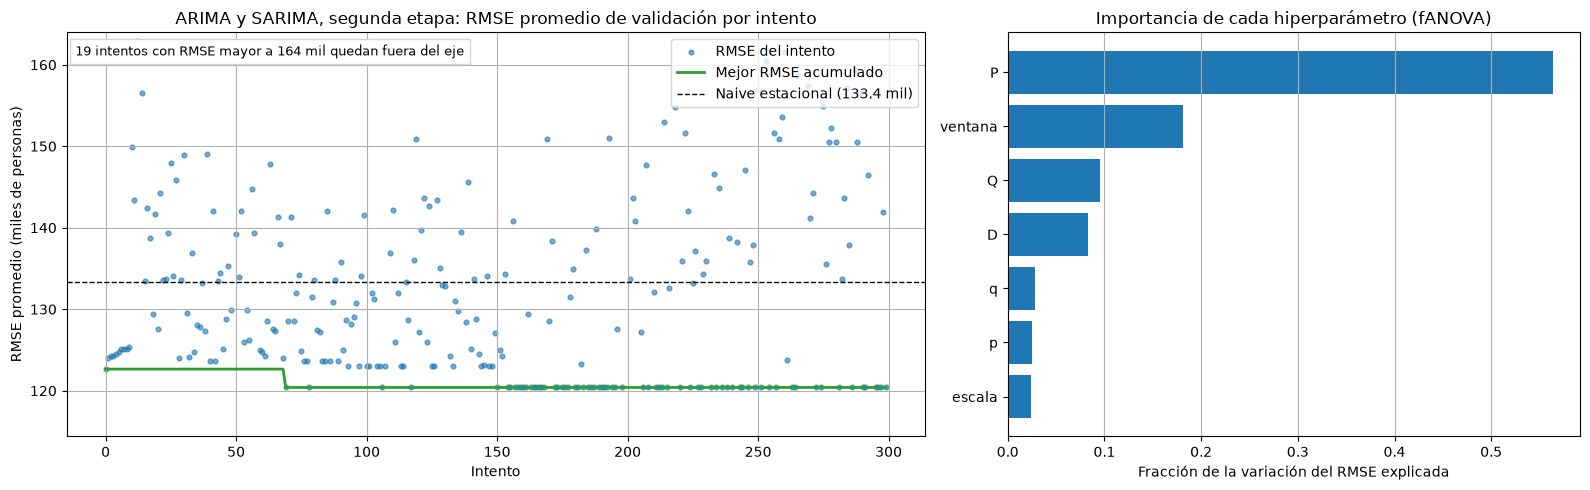


Revisión de bordes del mejor intento:
                   Valor                Rango En el borde
Hiperparámetro                                           
p                      3               [0, 5]          no
q                      3               [0, 5]          no
P                      2               [0, 3]          no
D                      0               [0, 1]   no aplica
Q                      0               [0, 2]          no
escala          original  ['original', 'log']   no aplica
ventana               96   [48, 60, 96, None]          no
tendencia              n           ['n', 'c']   no aplica

Diagnóstico de los intentos fallidos:
Configuraciones distintas evaluadas: 193 | fallidas: 7
                          Evaluadas  Fallidas  % fallidas
Hiperparámetro Valor                                     
D              0                153         7         4.6
               1                 40         0         0.0
escala         log              125         0         0

In [19]:
# Segunda etapa: órdenes no estacionales hasta 5 y orden autorregresivo estacional hasta 3.
# Empieza evaluando los 10 mejores intentos de la primera etapa (se leen del caché), y usa más
# intentos porque el espacio ampliado es mucho mayor.
N_INTENTOS_SARIMA_ETAPA_2 = 300
mejores_etapa_1 = [estudio_sarima.trials[numero].params for numero in resumir_estudio(estudio_sarima).index]
estudio_sarima_etapa_2 = optimizar(espacio_sarima(max_p=5, max_q=5, max_P=3), crear_pronostico_sarima,
                                   N_INTENTOS_SARIMA_ETAPA_2, intentos_iniciales=mejores_etapa_1)
assert estudio_sarima_etapa_2.best_value <= estudio_sarima.best_value + 1e-9, \
    "la segunda etapa no puede terminar peor que la primera, porque parte de sus mejores intentos"

print("\nMejores intentos:")
print(resumir_estudio(estudio_sarima_etapa_2).round(3).to_string())

graficar_estudio(estudio_sarima_etapa_2, "ARIMA y SARIMA, segunda etapa")

print("\nRevisión de bordes del mejor intento:")
print(revisar_bordes(estudio_sarima_etapa_2, **BORDES_SARIMA).to_string())

print("\nDiagnóstico de los intentos fallidos:")
print(diagnosticar_fallos(estudio_sarima_etapa_2).round(1).to_string())


def numero_coeficientes_arma(config):
    """Número de coeficientes autorregresivos y de media móvil de una configuración SARIMA."""
    return config["p"] + config["q"] + config["P"] + config["Q"]


# Mejor configuración de cada etapa
mejores_por_etapa = pd.DataFrame({
    nombre: {**estudio.best_trial.user_attrs["config"],
             "Coeficientes ARMA": numero_coeficientes_arma(estudio.best_trial.user_attrs["config"]),
             "RMSE promedio": estudio.best_value,
             "MAPE promedio (%)": np.mean(estudio.best_trial.user_attrs["mape_cortes"])}
    for nombre, estudio in [("Primera etapa", estudio_sarima), ("Segunda etapa", estudio_sarima_etapa_2)]
})
print("\nMejor intento de cada etapa:")
print(mejores_por_etapa.to_string())

### Lectura de la segunda etapa

De los 300 intentos, 193 corresponden a configuraciones distintas. Solo 7 fallaron, por el mismo error numérico de la primera etapa, todos con $D = 0$ y escala original, y ninguno se volvió a proponer. Ninguna región del espacio ampliado quedó sin explorar.

El mejor intento es un $\text{SARIMA}(3,1,3)(2,0,0)_{12}$ en escala original, sin término determinístico y estimado con los últimos 96 meses, con un RMSE promedio de 120.40 mil personas y un MAPE de 0.96 %. Esta configuración ya pertenecía al espacio de la primera etapa, pero no se evaluó allí. En la gráfica «ARIMA y SARIMA, segunda etapa: RMSE promedio de validación por intento», el mejor RMSE acumulado parte del mejor intento de la primera etapa (122.65), baja a 120.40 en el intento 69 y no cambia en los 230 intentos siguientes. Los órdenes más altos que agrega esta etapa no mejoran el error: el mejor modelo con $q = 5$ tiene un RMSE de 122.98 y el mejor con $p = 4$, de 123.33, y ningún modelo con $P = 3$ está entre los 10 mejores. Por eso, en la gráfica de importancia (fANOVA) de esta etapa, $P$ es el hiperparámetro que más explica la variación del error, seguido de la ventana. Los 10 mejores intentos conservan la estructura de la primera etapa: $D = 0$, $P = 2$, $Q = 0$, sin término determinístico y con ventana de 96 meses.

La revisión de bordes no muestra ningún hiperparámetro en el límite de su rango, así que la búsqueda termina aquí.

Frente al mejor modelo de la primera etapa, el $\text{SARIMA}(3,1,3)(2,0,0)_{12}$ tiene 2 coeficientes más (8 frente a 6) y un RMSE 2.25 mil menor (1.8 %), con la misma estructura estacional. Los 10 mejores intentos tienen errores entre 120.4 y 124.1 mil, de modo que las diferencias entre ellos son pequeñas en solo 6 cortes. Antes de elegir el modelo de la familia, se revisan los supuestos de sus residuales.

### Supuestos de los residuales y elección del modelo de la familia ARIMA

Un modelo ARIMA supone que sus errores son ruido blanco: sin autocorrelación y con varianza constante. Si los residuales están autocorrelacionados, el modelo deja sin representar parte de la dinámica de la serie, y si su varianza cambia en el tiempo, sus intervalos de predicción no tienen la cobertura que indican; la normalidad, además, es necesaria para que los intervalos calculados con la distribución normal sean válidos. Por eso, como en la regresión del taller anterior, el modelo de la familia no se elige solo por su error de validación, sino con un procedimiento en dos pasos que se fija antes de ver los resultados:

- **Candidatos:** las configuraciones distintas de las dos etapas con un RMSE promedio de validación menor que el del naive estacional, en orden de RMSE. Un modelo que pronostica peor que repetir los valores del año anterior no se considera, aunque cumpla los supuestos.
- **Residuales:** los de cada candidato ajustado con su ventana de estimación al final del entrenamiento, que es el modelo que se usaría en la muestra de prueba. En un ARIMA, los residuales son los errores de pronóstico a un mes dentro de la muestra. Se descartan las primeras $d + 12D$ observaciones, cuyo residual depende de la inicialización de la parte diferenciada y no es un error de pronóstico.
- **Independencia:** se cumple si la prueba de Ljung-Box no rechaza la hipótesis nula en la mayoría de los rezagos revisados, hasta el rezago 24, que cubre dos ciclos estacionales. Como los residuales provienen de un modelo con $p + q + P + Q$ coeficientes estimados, los grados de libertad de la prueba se reducen en ese número, y solo se revisan los rezagos mayores que él. Este ajuste no se usa con los residuales de una regresión, pero es el que corresponde a los residuales de un modelo ARMA.
- **Varianza constante:** se cumple con la misma regla, aplicada a la prueba de Ljung-Box sobre los residuales centrados al cuadrado, en los rezagos 1 a 24.
- **Normalidad:** se cumple si ni la prueba de Jarque-Bera ni la de Shapiro-Wilk rechazan la hipótesis nula.
- **Complementos:** la prueba de rachas y la prueba ARCH-LM de Engle se reportan, pero no entran en la decisión.

Todas las pruebas usan un nivel de 0.05. Se evalúan todos los candidatos, para ver cuántos cumplen cada supuesto, y el modelo de la familia es el primero en orden de RMSE que cumple los tres. Si ninguno los cumple, se conserva el candidato con menor RMSE, y sus intervalos de predicción se construyen con *bootstrap* de sus residuales, que no supone normalidad.

Candidatos con RMSE promedio menor que el del naive estacional (133.36): 102

Supuestos de los 10 primeros candidatos, en orden de RMSE de validación:
                                                 RMSE promedio  Residuales  Rachas (p-valor) Rezagos revisados, Ljung-Box Rechazos Ljung-Box Rechazos Ljung-Box sobre cuadrados  ARCH-LM, 12 rezagos (p-valor)  Jarque-Bera (p-valor)  Shapiro-Wilk (p-valor)  Independencia  Varianza constante  Normalidad  Cumple los supuestos
Candidato                                                                                                                                                                                                                                                                                                                         
1. SARIMA(3,1,3)(2,0,0)12, original, ventana 96        120.399          95             0.256                       9 a 24           10 de 16                           24 de 24                          0.

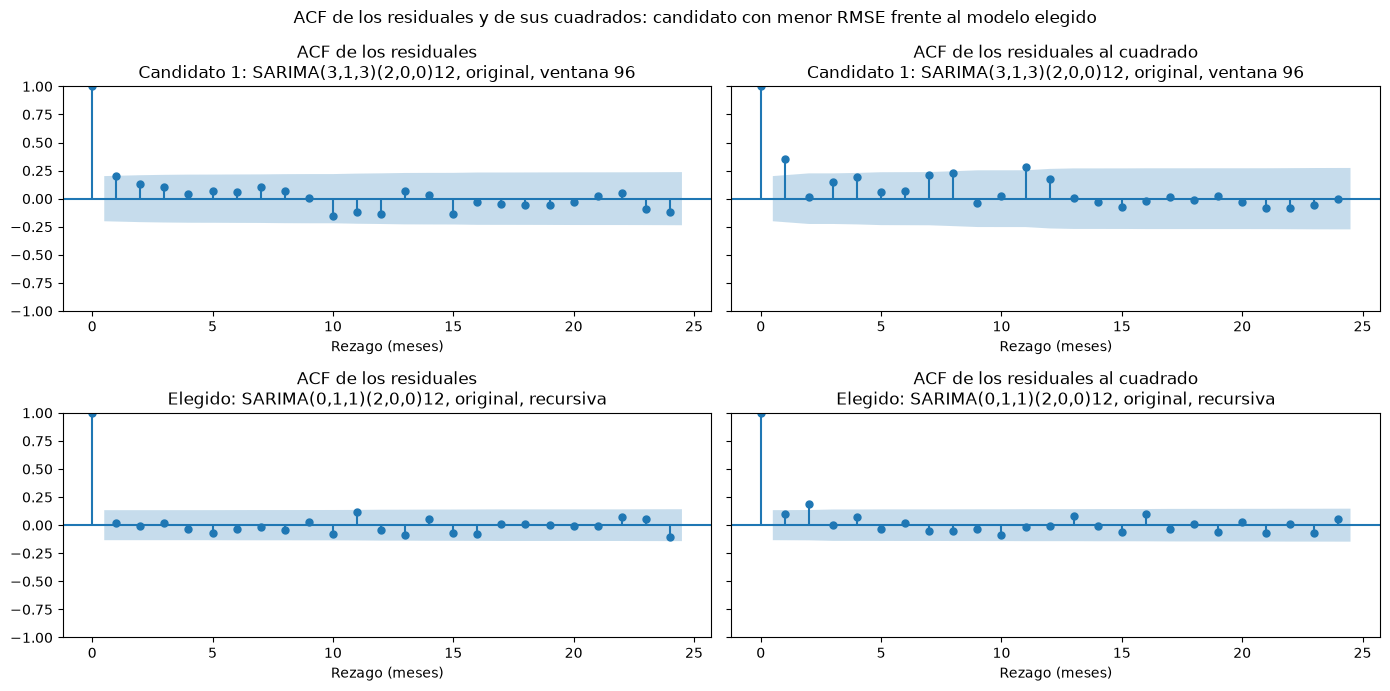

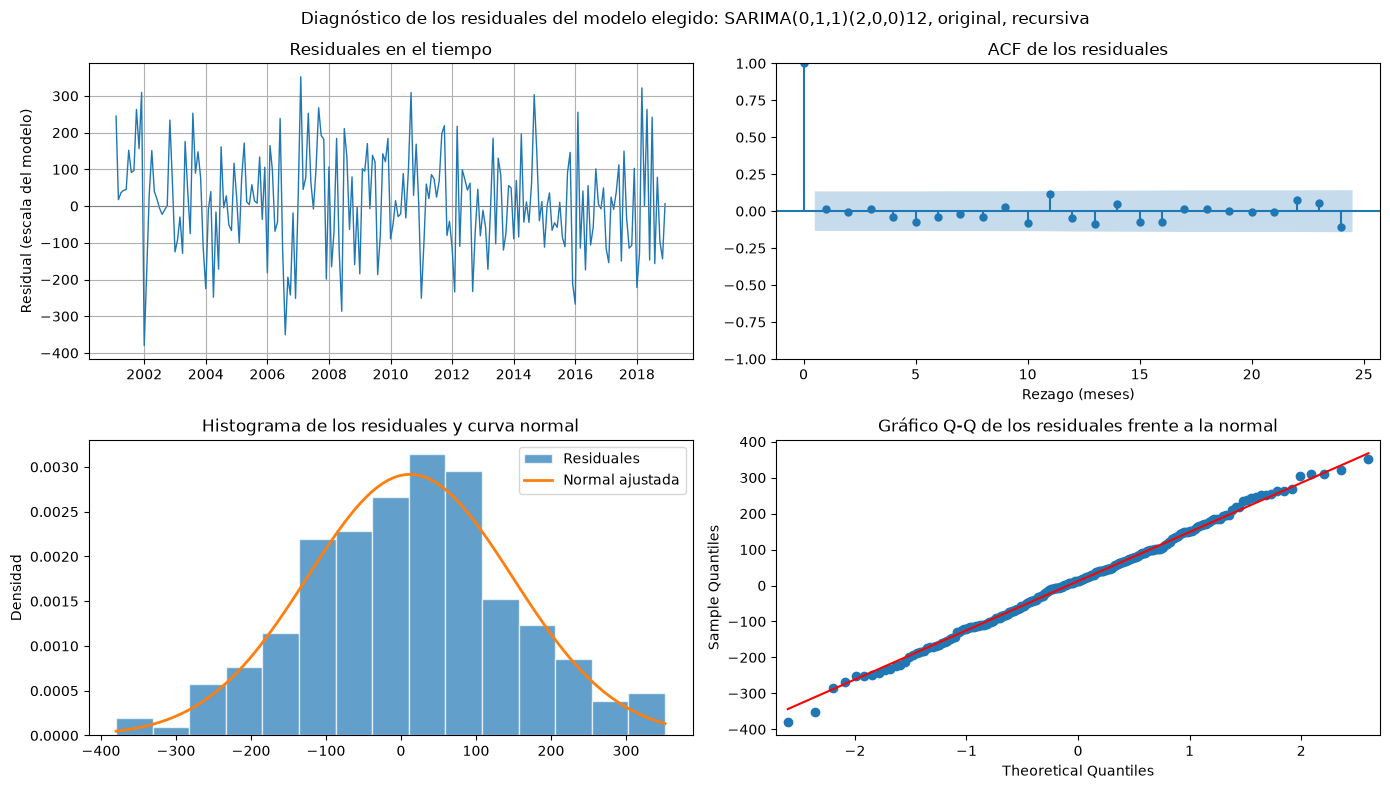

In [20]:
REZAGO_MAXIMO_SUPUESTOS = 24   # dos ciclos estacionales completos
ALFA_SUPUESTOS = 0.05


def candidatos_sarima(estudios, rmse_maximo):
    """Configuraciones distintas de los estudios con un RMSE promedio menor que rmse_maximo, en orden de RMSE."""
    candidatos = {}
    for estudio in estudios:
        for intento in estudio.trials:
            if intento.state != optuna.trial.TrialState.COMPLETE or intento.value >= rmse_maximo:
                continue
            config = intento.user_attrs["config"]
            candidatos.setdefault(tuple(sorted(config.items())), {
                "config": config, "RMSE promedio": intento.value, "rmse_cortes": intento.user_attrs["rmse_cortes"],
            })
    return sorted(candidatos.values(), key=lambda candidato: candidato["RMSE promedio"])


def describir_sarima(config):
    """Descripción corta de una configuración SARIMA: órdenes, escala, ventana y término determinístico."""
    (p, d, q), (P, D, Q, _) = ordenes_sarima(config)
    ventana = "recursiva" if config["ventana"] is None else f"ventana {config['ventana']}"
    constante = ", con deriva" if config["tendencia"] == "c" else ""
    return f"SARIMA({p},{d},{q})({P},{D},{Q})12, {config['escala']}, {ventana}{constante}"


def residuales_sarima(config, serie=train):
    """Residuales del SARIMA ajustado con su ventana al final de la serie, sin las observaciones iniciales
    que la inicialización difusa de la parte diferenciada deja sin un error interpretable."""
    ajuste = ajustar_sarima(serie, config)
    return ajuste.resid.iloc[ajuste.loglikelihood_burn:]


def evaluar_supuestos_residuales(residuos, coeficientes_arma, rezago_maximo=REZAGO_MAXIMO_SUPUESTOS,
                                 alfa=ALFA_SUPUESTOS):
    """Pruebas de los supuestos de los residuales y regla de decisión del taller anterior.

    Independencia: Ljung-Box no rechaza en la mayoría de los rezagos revisados. Los grados de libertad
    se reducen en el número de coeficientes ARMA estimados, de modo que solo se revisan los rezagos
    mayores que ese número. Varianza constante: la misma regla con Ljung-Box sobre los residuales
    centrados al cuadrado, en los rezagos 1 a rezago_maximo. Normalidad: no rechazan ni Jarque-Bera ni
    Shapiro-Wilk. La prueba de rachas y la ARCH-LM se reportan como complemento.
    """
    rezagos_independencia = list(range(coeficientes_arma + 1, rezago_maximo + 1))
    rezagos_varianza = list(range(1, rezago_maximo + 1))
    centrados = residuos - residuos.mean()
    rechazos_independencia = int((acorr_ljungbox(residuos, lags=rezagos_independencia, model_df=coeficientes_arma,
                                                 return_df=True)["lb_pvalue"] < alfa).sum())
    rechazos_varianza = int((acorr_ljungbox(centrados ** 2, lags=rezagos_varianza,
                                            return_df=True)["lb_pvalue"] < alfa).sum())
    p_jarque_bera = stats.jarque_bera(residuos).pvalue
    p_shapiro_wilk = stats.shapiro(residuos).pvalue

    independencia = rechazos_independencia < len(rezagos_independencia) / 2
    varianza_constante = rechazos_varianza < len(rezagos_varianza) / 2
    normalidad = p_jarque_bera >= alfa and p_shapiro_wilk >= alfa
    return {
        "Residuales": len(residuos),
        "Rachas (p-valor)": runstest_1samp(residuos, cutoff=0, correction=False)[1],
        "Rezagos revisados, Ljung-Box": f"{rezagos_independencia[0]} a {rezago_maximo}",
        "Rechazos Ljung-Box": f"{rechazos_independencia} de {len(rezagos_independencia)}",
        "Rechazos Ljung-Box sobre cuadrados": f"{rechazos_varianza} de {len(rezagos_varianza)}",
        "ARCH-LM, 12 rezagos (p-valor)": het_arch(centrados, nlags=12, result_object=True).lmpval,
        "Jarque-Bera (p-valor)": p_jarque_bera,
        "Shapiro-Wilk (p-valor)": p_shapiro_wilk,
        "Independencia": independencia,
        "Varianza constante": varianza_constante,
        "Normalidad": normalidad,
        "Cumple los supuestos": independencia and varianza_constante and normalidad,
    }


def diagnosticar_candidato(config):
    """Supuestos de los residuales de un candidato SARIMA ajustado con todo el entrenamiento."""
    return evaluar_supuestos_residuales(residuales_sarima(config), numero_coeficientes_arma(config))


# Candidatos: configuraciones de las dos etapas con menor RMSE que el naive estacional, en orden de RMSE
rmse_naive_estacional = validacion["Naive estacional"]["rmse"].mean()
candidatos = candidatos_sarima([estudio_sarima, estudio_sarima_etapa_2], rmse_naive_estacional)
print(f"Candidatos con RMSE promedio menor que el del naive estacional ({rmse_naive_estacional:.2f}): {len(candidatos)}")

# Supuestos de todos los candidatos, en paralelo; cada ajuste usa todo el entrenamiento con la ventana del candidato
diagnosticos = Parallel(n_jobs=N_PROCESOS)(delayed(diagnosticar_candidato)(c["config"]) for c in candidatos)
tabla_supuestos_sarima = pd.DataFrame([
    {"Candidato": f"{posicion}. {describir_sarima(c['config'])}", "RMSE promedio": c["RMSE promedio"], **diagnostico}
    for posicion, (c, diagnostico) in enumerate(zip(candidatos, diagnosticos), start=1)
]).set_index("Candidato")

print("\nSupuestos de los 10 primeros candidatos, en orden de RMSE de validación:")
print(tabla_supuestos_sarima.head(10).map(lambda v: round(v, 3) if isinstance(v, float) else v).to_string())
print("\nCandidatos que cumplen cada supuesto:")
print(tabla_supuestos_sarima[["Independencia", "Varianza constante", "Normalidad", "Cumple los supuestos"]]
      .sum().astype(int).to_string())

# Elección: el primer candidato que cumple los tres supuestos; si ninguno, el de menor RMSE
posicion_elegida = next((i for i, d in enumerate(diagnosticos) if d["Cumple los supuestos"]), None)
SARIMA_CUMPLE_SUPUESTOS = posicion_elegida is not None
CANDIDATO_SARIMA = candidatos[posicion_elegida if SARIMA_CUMPLE_SUPUESTOS else 0]
descripcion_elegido = describir_sarima(CANDIDATO_SARIMA["config"])
if SARIMA_CUMPLE_SUPUESTOS:
    print("\nPrimeros 5 candidatos que cumplen los tres supuestos:")
    print(tabla_supuestos_sarima[tabla_supuestos_sarima["Cumple los supuestos"]].head(5)
          .map(lambda v: round(v, 3) if isinstance(v, float) else v).to_string())
    print(f"\nModelo elegido de la familia ARIMA: candidato {posicion_elegida + 1} de {len(candidatos)}, "
          f"{descripcion_elegido} (RMSE {CANDIDATO_SARIMA['RMSE promedio']:.2f})")
else:
    print(f"\nNingún candidato cumple los supuestos; se conserva el de menor RMSE: {descripcion_elegido}")

# ACF de los residuales y de sus cuadrados: candidato con menor RMSE frente al modelo elegido
residuos_por_modelo = {f"Candidato 1: {describir_sarima(candidatos[0]['config'])}": residuales_sarima(candidatos[0]["config"]),
                       f"Elegido: {descripcion_elegido}": residuales_sarima(CANDIDATO_SARIMA["config"])}
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=True)
for fila, (nombre, residuos) in enumerate(residuos_por_modelo.items()):
    plot_acf(residuos, lags=REZAGO_MAXIMO_SUPUESTOS, ax=axes[fila, 0], title=f"ACF de los residuales\n{nombre}")
    plot_acf((residuos - residuos.mean()) ** 2, lags=REZAGO_MAXIMO_SUPUESTOS, ax=axes[fila, 1],
             title=f"ACF de los residuales al cuadrado\n{nombre}")
for ax in axes.flat:
    ax.set_xlabel("Rezago (meses)")
fig.suptitle("ACF de los residuales y de sus cuadrados: candidato con menor RMSE frente al modelo elegido")
fig.tight_layout()
plt.show()

# Gráficas de diagnóstico de los residuales del modelo elegido
residuos_elegido = residuos_por_modelo[f"Elegido: {descripcion_elegido}"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(residuos_elegido, linewidth=1)
axes[0, 0].axhline(0, color="gray", linewidth=0.8)
axes[0, 0].set_title("Residuales en el tiempo")
axes[0, 0].set_ylabel("Residual (escala del modelo)")
axes[0, 0].grid()
plot_acf(residuos_elegido, lags=REZAGO_MAXIMO_SUPUESTOS, ax=axes[0, 1], title="ACF de los residuales")
axes[0, 1].set_xlabel("Rezago (meses)")
media_normal, desviacion_normal = stats.norm.fit(residuos_elegido)
valores_x = np.linspace(residuos_elegido.min(), residuos_elegido.max(), 100)
axes[1, 0].hist(residuos_elegido, bins=15, density=True, edgecolor="white", alpha=0.7, label="Residuales")
axes[1, 0].plot(valores_x, stats.norm.pdf(valores_x, media_normal, desviacion_normal), color="C1", linewidth=2,
                label="Normal ajustada")
axes[1, 0].set_title("Histograma de los residuales y curva normal")
axes[1, 0].set_ylabel("Densidad")
axes[1, 0].legend()
sm.qqplot(residuos_elegido, line="s", ax=axes[1, 1])
axes[1, 1].set_title("Gráfico Q-Q de los residuales frente a la normal")
fig.suptitle(f"Diagnóstico de los residuales del modelo elegido: {descripcion_elegido}")
fig.tight_layout()
plt.show()

### Lectura de los supuestos y elección del modelo de la familia

De los 102 candidatos con un RMSE menor que el del naive estacional, 47 cumplen la independencia, 36 la varianza constante y 86 la normalidad, y solo 30 cumplen los tres supuestos. Ninguno de los 26 candidatos con menor RMSE los cumple. La tabla de los 10 primeros muestra el patrón: todos se estiman con la ventana de 96 meses, ninguno cumple la varianza constante (la prueba de Ljung-Box sobre los cuadrados rechaza en 14 a 24 de los 24 rezagos) y siete tampoco cumplen la independencia.

En la gráfica «ACF de los residuales y de sus cuadrados: candidato con menor RMSE frente al modelo elegido», el primer candidato, el $\text{SARIMA}(3,1,3)(2,0,0)_{12}$ con ventana de 96 meses, tiene una autocorrelación de los residuales al cuadrado de cerca de 0.36 en el rezago 1 y de cerca de 0.28 y 0.18 en los rezagos 11 y 12: los errores grandes tienden a seguir a otros errores grandes y a repetirse cerca del mismo mes del año siguiente. Es un indicio coherente con el cambio del tamaño de la caída de enero descrito en la sección 2, que un modelo con coeficientes fijos no puede seguir. Sus residuales tienen además una autocorrelación de cerca de 0.2 en el rezago 1, en el límite de la banda.

El primer candidato que cumple los tres supuestos es el número 27: el $\text{SARIMA}(0,1,1)(2,0,0)_{12}$ en escala original, sin término determinístico y estimado con toda la historia (ventana recursiva), con un RMSE promedio de 125.67 mil personas, 5.27 mil (4.4 %) más que el candidato con menor RMSE. Sus 215 residuales no muestran autocorrelación (la prueba de Ljung-Box no rechaza en ninguno de los rezagos 4 a 24, y la de rachas tiene un p-valor de 0.754), su varianza es estable (la prueba sobre los cuadrados rechaza en 4 de los 24 rezagos, y la ARCH-LM tiene un p-valor de 0.367) y son compatibles con una distribución normal (p-valores de 0.852 en Jarque-Bera y de 0.943 en Shapiro-Wilk). En la gráfica «Diagnóstico de los residuales del modelo elegido: SARIMA(0,1,1)(2,0,0)12, original, recursiva», los residuales oscilan alrededor de cero sin tramos claros de mayor variabilidad, su ACF queda dentro de la banda en todos los rezagos, y el histograma y el gráfico Q-Q siguen la distribución normal, salvo los dos valores más bajos.

Este modelo cumple los supuestos con 215 residuales, más del doble que los candidatos con ventana de 96 meses, de modo que el resultado no se debe a pruebas con poca potencia. Los cinco primeros candidatos que cumplen los supuestos usan la ventana recursiva y tienen errores entre 125.7 y 127.2 mil. Además, el modelo elegido coincide con lo que sugería la identificación de la sección 6 para la parte no estacional, un componente MA(1) sobre la primera diferencia, y representa la persistencia estacional con dos términos autorregresivos estacionales, como los demás candidatos con menor error.

Se elige el $\text{SARIMA}(0,1,1)(2,0,0)_{12}$ en escala original y con ventana recursiva como modelo de la familia ARIMA. Se renuncia a 5.27 mil personas de RMSE de validación a cambio de un modelo que no deja dinámica sin representar en sus residuales, y cuyos intervalos de predicción tienen fundamento.

### Referencia: selección automática con `auto_arima`

La optimización bayesiana elige la especificación por el error de pronóstico fuera de la muestra. El procedimiento clásico la elige con un criterio de información calculado dentro de la muestra, como hace `auto_arima` de pmdarima. En cada corte, elige el orden de diferenciación $d$ con la prueba KPSS y el estacional $D$ con la prueba OCSB. Luego recorre los órdenes de forma escalonada: parte de un modelo inicial y prueba cambios de una unidad en cada orden hasta encontrar el de menor AIC (criterio de información de Akaike).

El modelo se evalúa en los mismos 6 cortes, con toda la historia disponible en cada uno y en escala original. Se usan los valores por defecto de `auto_arima`: órdenes no estacionales hasta 5 y estacionales hasta 2, y una constante que solo puede incluirse cuando $d + D < 2$ y que la búsqueda decide si conserva. Se cambian dos valores. El periodo estacional se fija en 12 meses, porque por defecto el modelo no tiene parte estacional. El número máximo de iteraciones del optimizador se fija en 500, como en la búsqueda con Optuna, en lugar de las 50 por defecto. Así, la diferencia entre los dos modelos refleja el criterio de selección y no la estimación. Como el modelo elegido puede cambiar de un corte a otro, se registra la especificación de cada corte.

In [21]:
# Referencia: SARIMA elegido por AIC en cada corte con auto_arima, con sus valores por defecto salvo el
# periodo estacional y el número máximo de iteraciones, que se iguala al de la búsqueda con Optuna
CONFIG_AUTO_ARIMA = {"m": ESTACIONALIDAD_SARIMA, "criterio": "aic"}
PROCESOS_POR_MODELO["crear_pronostico_auto_arima"] = N_PROCESOS


def crear_pronostico_auto_arima(config):
    """Función de pronóstico que, en cada corte, elige un SARIMA con auto_arima y pronostica con él.

    Devuelve los pronósticos como una serie cuyo atributo "Modelo elegido" describe la especificación
    seleccionada en el corte, para que quede registrada junto con las métricas.
    """
    def pronostico(serie_ajuste, h):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            modelo = auto_arima(serie_ajuste, seasonal=True, m=config["m"], information_criterion=config["criterio"],
                                maxiter=MAX_ITERACIONES_SARIMA, error_action="ignore", suppress_warnings=True)
        p, d, q = modelo.order
        P, D, Q, _ = modelo.seasonal_order
        salida = pd.Series(np.asarray(modelo.predict(n_periods=h), dtype=float))
        salida.attrs["Modelo elegido"] = (f"SARIMA({p},{d},{q})({P},{D},{Q})12"
                                          + (" con constante" if modelo.with_intercept else ""))
        return salida

    return pronostico


NOMBRE_AUTO_ARIMA = "SARIMA elegido por AIC en cada corte (auto_arima)"
registrar_modelo(NOMBRE_AUTO_ARIMA, "ARIMA", crear_pronostico_auto_arima(CONFIG_AUTO_ARIMA),
                 identidad=identidad_cache(crear_pronostico_auto_arima, CONFIG_AUTO_ARIMA),
                 n_procesos=PROCESOS_POR_MODELO["crear_pronostico_auto_arima"])

print("Modelo elegido y error en cada corte:")
print(validacion[NOMBRE_AUTO_ARIMA].round(2).to_string())
print("\nResumen de la validación:")
print(resumir_validacion([NOMBRE_AUTO_ARIMA], referencias=("Naive estacional", CAMPEON_TALLER_1))
      .round(2).to_string())

# Supuestos de los residuales del modelo que auto_arima elige con todo el entrenamiento, con las mismas
# pruebas y la misma regla de los candidatos. Es una referencia: con un RMSE mayor que el del naive
# estacional, no es candidato a modelo de la familia
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    modelo_auto_arima = auto_arima(train, seasonal=True, m=CONFIG_AUTO_ARIMA["m"],
                                   information_criterion=CONFIG_AUTO_ARIMA["criterio"], maxiter=MAX_ITERACIONES_SARIMA,
                                   error_action="ignore", suppress_warnings=True)
(p_auto, d_auto, q_auto), (P_auto, D_auto, Q_auto, _) = modelo_auto_arima.order, modelo_auto_arima.seasonal_order
descripcion_auto_arima = (f"SARIMA({p_auto},{d_auto},{q_auto})({P_auto},{D_auto},{Q_auto})12, original, recursiva"
                          + (", con constante" if modelo_auto_arima.with_intercept else ""))
ajuste_auto_arima = modelo_auto_arima.arima_res_
residuos_auto_arima = ajuste_auto_arima.resid.iloc[ajuste_auto_arima.loglikelihood_burn:]
supuestos_auto_arima = evaluar_supuestos_residuales(residuos_auto_arima, p_auto + q_auto + P_auto + Q_auto)

print("\nSupuestos de los residuales con todo el entrenamiento: modelo elegido de la familia frente a auto_arima")
print(pd.DataFrame({
    f"Elegido: {describir_sarima(CANDIDATO_SARIMA['config'])}": tabla_supuestos_sarima.iloc[candidatos.index(CANDIDATO_SARIMA)],
    f"auto_arima: {descripcion_auto_arima}": pd.Series({"RMSE promedio": validacion[NOMBRE_AUTO_ARIMA]["rmse"].mean(),
                                                         **supuestos_auto_arima}),
}).map(lambda v: round(v, 3) if isinstance(v, float) else v).to_string())

Modelo elegido y error en cada corte:
                     rmse  mape                        Modelo elegido  estado
inicio_validacion                                                            
2016-01            146.13  1.23  SARIMA(2,1,0)(1,0,1)12 con constante  loaded
2016-07             86.16  0.71  SARIMA(2,1,0)(1,0,1)12 con constante  loaded
2017-01            119.80  1.08  SARIMA(2,1,0)(1,0,1)12 con constante  loaded
2017-07            190.74  1.58  SARIMA(2,1,0)(1,0,1)12 con constante  loaded
2018-01            140.44  1.18  SARIMA(2,1,0)(1,0,1)12 con constante  loaded
2018-07            166.59  1.39  SARIMA(2,1,0)(1,0,1)12 con constante  loaded

Resumen de la validación:
                                                   RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional  Cortes mejores que Combinación ANA + regresión (taller 1)
SARIMA elegido por AIC en cada corte (auto_arima)         141.64               1.19                                    4           

### Lectura de la referencia

En los 6 cortes, `auto_arima` elige la misma especificación, un $\text{SARIMA}(2,1,0)(1,0,1)_{12}$ con constante. Las pruebas de raíz unitaria le dan los mismos órdenes de diferenciación que la identificación de la sección 6 ($d = 1$ y $D = 0$). Su RMSE promedio es de 141.64 mil personas y su MAPE de 1.19 %, ambos mayores que los del naive estacional (133.36 mil y 1.05 %), aunque lo supera en 4 de los 6 cortes. El promedio sube por los cortes que empiezan en julio de 2017 y julio de 2018, con errores de 190.7 y 166.6 mil. Frente al mejor modelo del taller anterior, solo tiene menor error en 2 de los 6 cortes.

Con todo el entrenamiento, `auto_arima` elige el mismo modelo, y sus residuales también cumplen los tres supuestos: la prueba de Ljung-Box rechaza en 1 de 20 rezagos, la prueba sobre los cuadrados en ninguno, y las de Jarque-Bera y Shapiro-Wilk no rechazan la normalidad (p-valores de 0.076 y 0.237). Por la regla de la sección, no es candidato, porque su RMSE es mayor que el del naive estacional. Que cumpla los supuestos y aun así pronostique peor que repetir los valores del año anterior muestra que las dos revisiones miden cosas distintas: los supuestos evalúan los errores a un mes dentro de la muestra, y la validación, el error a 6 meses fuera de ella.

El SARIMA elegido para la familia tiene un RMSE de 125.67 mil. Los dos modelos usan toda la historia y los dos cumplen los supuestos, de modo que difieren en el criterio con el que se eligen, en los órdenes y en el término determinístico.

El criterio es la diferencia de fondo. El AIC mide qué tan bien se ajusta el modelo dentro de la muestra, a un paso, mientras que la optimización bayesiana mide directamente el error de pronóstico a 6 meses fuera de la muestra, que es el objetivo de este trabajo.

El término determinístico es la diferencia más visible en el pronóstico. Con $d = 1$, la constante que elige `auto_arima` funciona como una deriva: cada mes pronosticado suma el crecimiento mensual promedio de toda la historia del corte, que incluye el crecimiento anterior a 2016. Ninguno de los mejores intentos de la optimización bayesiana incluye constante.

### Comparación y elección del modelo de la familia ARIMA

El SARIMA elegido con la revisión de los supuestos se registra como el modelo de la familia y se compara, corte por corte, con la referencia de `auto_arima`, con el naive estacional, con el mejor modelo del taller anterior y con el Holt-Winters ANA con Optuna. Como el término determinístico es una de las diferencias entre los dos SARIMA, también se calcula el error medio de cada corte, es decir, el promedio de los valores reales menos los pronósticos. Un error medio negativo indica que el modelo sobreestima el número de ocupados en ese corte, y uno positivo, que lo subestima. Los pronósticos de cada corte se leen del caché, de modo que no hace falta volver a ajustar los modelos.

Resumen de la validación:
                                                   RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional  Cortes mejores que Combinación ANA + regresión (taller 1)
Holt-Winters ANA con Optuna                               106.57               0.86                                    6                                                          5
Combinación ANA + regresión (taller 1)                    116.47               0.92                                    3                                                          0
SARIMA(0,1,1)(2,0,0)12 con Optuna                         125.67               0.99                                    3                                                          2
Naive estacional                                          133.36               1.05                                    0                                                          3
SARIMA elegido por AIC en cada corte (auto_arima)         141.64          

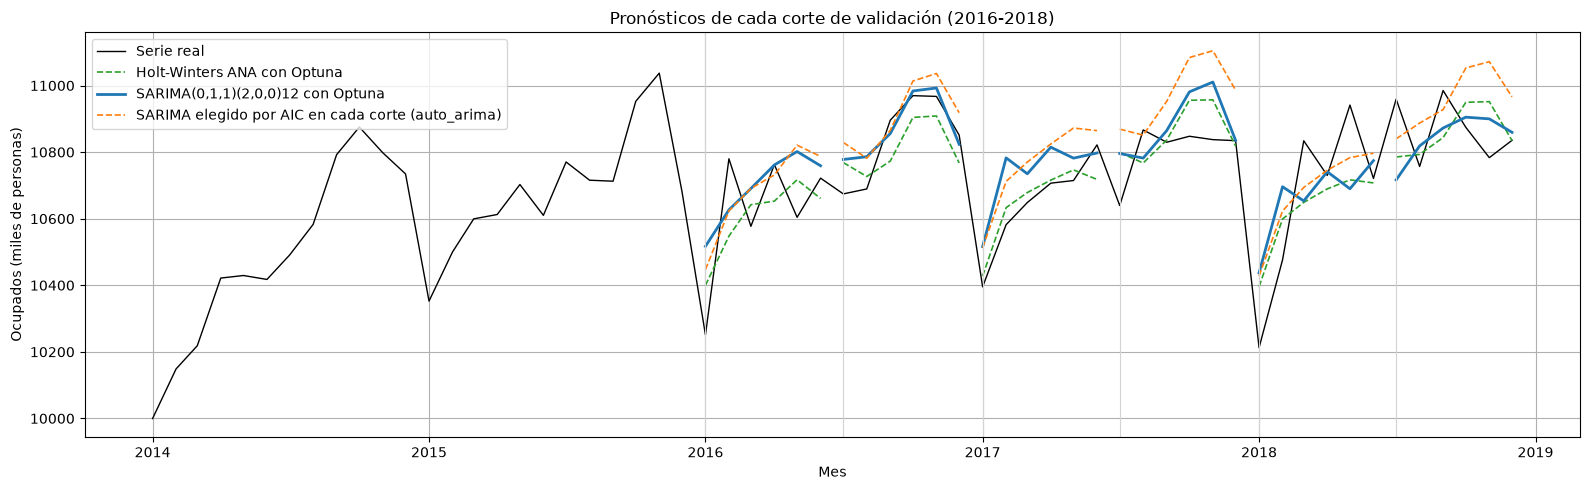

In [22]:
def pronosticos_validacion(crear_pronostico, config, serie=train, cv=tscv):
    """Pronósticos de cada corte de una configuración, leídos del caché.

    Primero se asegura de que la configuración esté evaluada (si falta algún corte, se ajusta y se
    guarda). Devuelve un diccionario {inicio del corte: serie de pronósticos de ese corte}.
    """
    identidad = identidad_cache(crear_pronostico, config)
    evaluar_validacion(crear_pronostico(config), serie=serie, cv=cv, identidad=identidad,
                       n_procesos=PROCESOS_POR_MODELO.get(crear_pronostico.__name__, 1))
    pronosticos = {}
    for numero, (idx_ajuste, idx_validacion) in enumerate(cv.split(serie), start=1):
        campos = campos_corte(identidad, serie.iloc[idx_ajuste], serie.iloc[idx_validacion], cv)
        resultado, estado = leer_cache(ruta_cache(identidad, numero), campos)
        assert estado == "loaded", f"el corte {numero} no está en el caché"
        pronosticos[serie.index[idx_validacion[0]].strftime("%Y-%m")] = resultado["pronostico"]
    return pronosticos


# Registro del SARIMA elegido con la revisión de los supuestos como modelo de la familia ARIMA
config_sarima = CANDIDATO_SARIMA["config"]
(p, d, q), (P, D, Q, _) = ordenes_sarima(config_sarima)
NOMBRE_SARIMA_OPTUNA = f"SARIMA({p},{d},{q})({P},{D},{Q})12 con Optuna"
resultados_sarima = registrar_modelo(NOMBRE_SARIMA_OPTUNA, "ARIMA", crear_pronostico_sarima(config_sarima),
                                     identidad=identidad_cache(crear_pronostico_sarima, config_sarima),
                                     n_procesos=PROCESOS_POR_MODELO["crear_pronostico_sarima"])
assert np.allclose(resultados_sarima["rmse"], CANDIDATO_SARIMA["rmse_cortes"], rtol=1e-3), \
    "el error al reevaluar no coincide con el de la optimización"

# Resumen y error por corte frente a las referencias y al mejor modelo de suavización exponencial
modelos_comparacion_arima = ["Naive estacional", CAMPEON_TALLER_1, NOMBRE_ETS_OPTUNA,
                             NOMBRE_SARIMA_OPTUNA, NOMBRE_AUTO_ARIMA]
print("Resumen de la validación:")
print(resumir_validacion(modelos_comparacion_arima, referencias=("Naive estacional", CAMPEON_TALLER_1))
      .round(2).to_string())
print("\nRMSE por corte (miles):")
print(error_por_corte(modelos_comparacion_arima).round(1).to_string())

# Error medio de cada corte (real - pronóstico): negativo si el modelo sobreestima
pronosticos_comparacion = {
    NOMBRE_ETS_OPTUNA: pronosticos_validacion(crear_pronostico_ets, config_ets),
    NOMBRE_SARIMA_OPTUNA: pronosticos_validacion(crear_pronostico_sarima, config_sarima),
    NOMBRE_AUTO_ARIMA: pronosticos_validacion(crear_pronostico_auto_arima, CONFIG_AUTO_ARIMA),
}
error_medio = pd.DataFrame({
    nombre: {corte: (train.loc[pronostico.index] - pronostico).mean() for corte, pronostico in pronosticos.items()}
    for nombre, pronosticos in pronosticos_comparacion.items()
})
error_medio.loc["Promedio"] = error_medio.mean()
print("\nError medio por corte (real - pronóstico, miles):")
print(error_medio.round(1).to_string())

# Pronósticos de cada corte de los dos SARIMA y del Holt-Winters ANA con Optuna
colores_comparacion = {NOMBRE_ETS_OPTUNA: "C2", NOMBRE_SARIMA_OPTUNA: "C0", NOMBRE_AUTO_ARIMA: "C1"}
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(train.loc["2014":], color="black", linewidth=1, label="Serie real")
for nombre, pronosticos in pronosticos_comparacion.items():
    for numero, pronostico in enumerate(pronosticos.values()):
        ax.plot(pronostico, color=colores_comparacion[nombre], linewidth=2 if nombre == NOMBRE_SARIMA_OPTUNA else 1.2,
                linestyle="-" if nombre == NOMBRE_SARIMA_OPTUNA else "--", label=nombre if numero == 0 else None)
for pronostico in pronosticos_comparacion[NOMBRE_SARIMA_OPTUNA].values():
    ax.axvline(pronostico.index[0], color="lightgray", linewidth=0.8)
ax.set_title("Pronósticos de cada corte de validación (2016-2018)")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left")
ax.grid()
plt.tight_layout()
plt.show()

### Lectura de la comparación

El SARIMA elegido tiene menor error que el de `auto_arima` en 4 de los 6 cortes, y su RMSE promedio es 16.0 mil personas menor (125.67 frente a 141.64). El error medio explica buena parte de la diferencia. El modelo de `auto_arima` tiene un error medio negativo en los 6 cortes, de −88.5 mil en promedio, es decir, sobreestima el número de ocupados de forma sistemática; en la gráfica «Pronósticos de cada corte de validación (2016-2018)» de esta sección, su pronóstico (línea naranja discontinua) queda por encima de la serie real en casi todos los meses validados. Es el efecto esperado de la deriva: cada mes pronosticado suma el crecimiento promedio de una historia que incluye el crecimiento anterior a 2016. El SARIMA elegido también tiende a sobreestimar, con un error medio negativo en 5 de los 6 cortes y de −43.3 mil en promedio, aunque menos que la mitad que el de `auto_arima`; en la misma gráfica, su pronóstico (línea azul continua) queda por encima de la serie real al inicio de los cortes de enero de 2016 y de enero de 2017 y en el máximo de fin de año de 2017. El Holt-Winters ANA con Optuna, en cambio, no tiene un sesgo sistemático: sus errores medios cambian de signo entre cortes, con un promedio de 3.9 mil.

Frente a los demás modelos, el SARIMA elegido supera al naive estacional en 3 de los 6 cortes y al mejor modelo del taller anterior en 2. El Holt-Winters ANA con Optuna tiene menor error que el SARIMA en 5 de los 6 cortes; solo en el corte de julio de 2016 el SARIMA es mejor (62.3 frente a 81.8 mil). Los errores más grandes del SARIMA están en los cortes de enero de 2016 (156.8 mil) y de enero de 2018 (181.4 mil), los mayores de todos los modelos en esos cortes, y en la gráfica los tres modelos se quedan cortos en las caídas de enero de 2016 y de 2018.

### Conclusión de la Parte II

Las pruebas de estacionariedad y las autocorrelaciones indicaron una diferencia no estacional y una estacionalidad persistente, que la optimización bayesiana representó con dos términos autorregresivos estacionales y sin diferencia estacional. Los candidatos con menor error de validación, estimados con los últimos 96 meses, no cumplen los supuestos de los residuales, principalmente el de varianza constante, y el modelo elegido para la familia es el primero que los cumple: el $\text{SARIMA}(0,1,1)(2,0,0)_{12}$ en escala original, sin término determinístico y con ventana recursiva, con un RMSE promedio de validación de 125.67 mil personas y un MAPE de 0.99 %. Frente al modelo elegido por AIC, que también cumple los supuestos, reduce el error en 16.0 mil personas, principalmente porque no incluye la deriva. Aun así, tiende a sobreestimar y no supera al mejor modelo del taller anterior ni al Holt-Winters ANA con Optuna, que sigue siendo el modelo con menor error.

# Parte III — Prophet

## 8. Prophet con optimización bayesiana

Prophet descompone la serie en una tendencia y una estacionalidad, que se suman o, en el modo multiplicativo, se multiplican. La tendencia es lineal por tramos: su pendiente puede cambiar en puntos de cambio distribuidos en la primera parte de la historia, y una distribución a priori de Laplace, cuya escala es `changepoint_prior_scale`, controla qué tan grandes pueden ser esos cambios. La estacionalidad anual se representa con una serie de Fourier, con una distribución a priori normal cuya escala es `seasonality_prior_scale`. Los parámetros se estiman por máximo a posteriori. Este diseño es pertinente para la serie, porque permite representar de forma explícita el cambio de pendiente de 2016.

La configuración se adapta a datos mensuales. Se desactivan las estacionalidades semanal y diaria, que no existen en una serie mensual, y no se incluyen festivos, porque su efecto queda dentro del efecto de cada mes. La estacionalidad anual se fija en 6 pares de términos de Fourier, el máximo que se puede distinguir con 12 observaciones por año, en lugar de los 10 que Prophet usa por defecto; su flexibilidad se controla con `seasonality_prior_scale`. En la validación no se calculan intervalos de pronóstico (`uncertainty_samples=0`), porque no cambian el pronóstico puntual y su simulación hace más lento cada ajuste. Prophet estima con el método de Newton cuando la ventana tiene menos de 100 observaciones y con L-BFGS en las demás, y calcula los valores iniciales de la optimización a partir de los datos, de modo que el ajuste es determinístico.

| Hiperparámetro | Valores | Justificación |
|---|---|---|
| Tendencia | lineal por tramos o plana | La tendencia plana mantiene constante el nivel y representa el estancamiento de la serie desde 2016, como la estructura sin tendencia de la suavización exponencial |
| `changepoint_prior_scale` | 0.001 a 0.5, escala logarítmica (solo con tendencia lineal) | Flexibilidad de la tendencia: valores pequeños dan una tendencia casi rígida y valores grandes la acercan a los datos |
| `changepoint_range` | 0.8 a 0.95 (solo con tendencia lineal) | Proporción de la historia con puntos de cambio. Con el valor por defecto (0.8) y la ventana recursiva, el último 20 % de la historia queda sin puntos de cambio; en el último corte son 42 meses, desde 2015, de modo que el cambio de 2016 no podría representarse |
| Modo estacional | aditivo o multiplicativo | Los rasgos de la sección 2 no permiten descartar ninguno de los dos |
| `seasonality_prior_scale` | 0.01 a 10, escala logarítmica | Magnitud de los efectos estacionales: valores pequeños los reducen hacia cero |
| Ventana de estimación | 48, 60 o 96 meses, o recursiva | Las mismas ventanas de la búsqueda de ARIMA |

Intentos: 200 | completos: 200 | fallidos: 0 | repetidos (resultado reutilizado): 0
Cortes leídos del caché: 1200 de 1200 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.00 s
Mejor RMSE promedio: 109.40 (intento 182)

Mejores intentos:
        tendencia modo_estacional  seasonality_prior_scale  ventana  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional  changepoint_prior_scale  changepoint_range
Intento                                                                                                                                                                               
182        lineal        additive                    8.172     96.0        109.396              0.845                                    5                    0.335              0.838
196        lineal        additive                    5.856     96.0        109.403              0.846                                    5                    0.327              

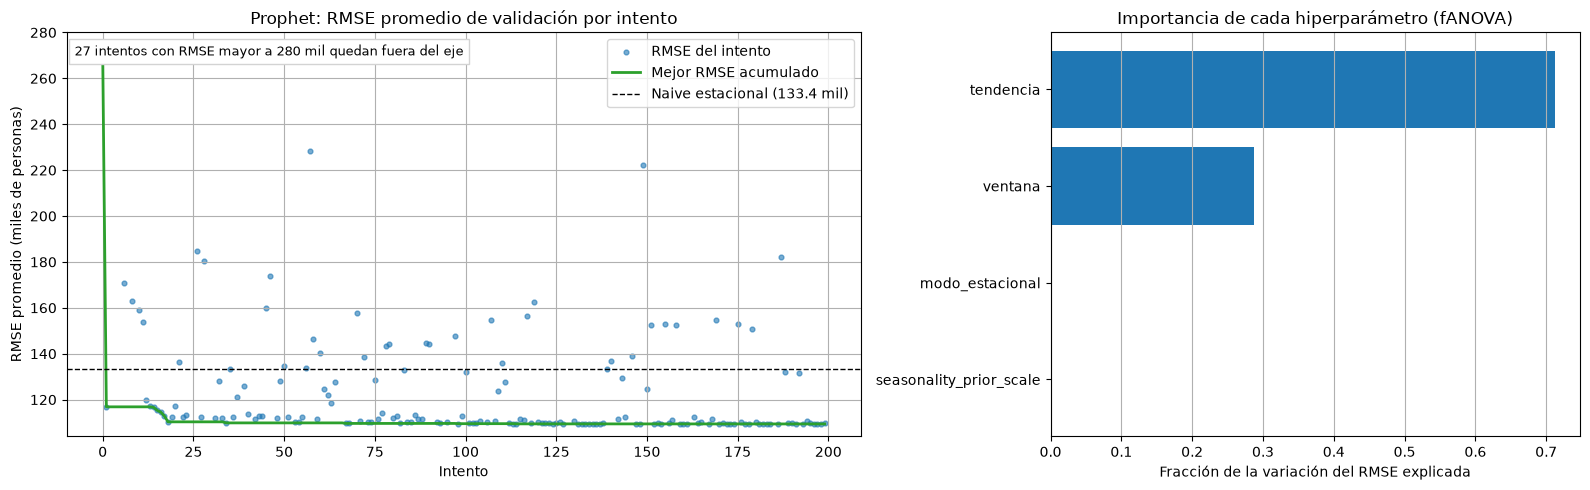


Revisión de bordes del mejor intento:
                            Valor                           Rango En el borde
Hiperparámetro                                                               
tendencia                  lineal             ['lineal', 'plana']   no aplica
modo_estacional          additive  ['additive', 'multiplicative']   no aplica
seasonality_prior_scale   8.17194                    [0.01, 10.0]          no
ventana                        96              [48, 60, 96, None]          no
changepoint_prior_scale  0.334509                    [0.001, 0.5]          no
changepoint_range        0.838147                     [0.8, 0.95]          no


In [23]:
VENTANAS_PROPHET = [48, 60, 96, None]   # None = ventana recursiva
TENDENCIAS_PROPHET = ["lineal", "plana"]
ORDEN_FOURIER_PROPHET = 6               # máximo número de pares de Fourier distinguibles con datos mensuales


def sugerir_configuracion_prophet(trial):
    """Espacio de búsqueda de Prophet; los hiperparámetros de los puntos de cambio solo se proponen
    cuando la tendencia es lineal."""
    config = {
        "tendencia": trial.suggest_categorical("tendencia", TENDENCIAS_PROPHET),
        "modo_estacional": trial.suggest_categorical("modo_estacional", ["additive", "multiplicative"]),
        "seasonality_prior_scale": trial.suggest_float("seasonality_prior_scale", 0.01, 10, log=True),
        "ventana": trial.suggest_categorical("ventana", VENTANAS_PROPHET),
    }
    if config["tendencia"] == "lineal":
        config["changepoint_prior_scale"] = trial.suggest_float("changepoint_prior_scale", 0.001, 0.5, log=True)
        config["changepoint_range"] = trial.suggest_float("changepoint_range", 0.8, 0.95)
    return config


def silenciar_registros_prophet():
    """Deja solo las advertencias y los errores de Prophet y cmdstanpy.

    Los procesos que ajustan los cortes en paralelo no heredan la configuración de logging del
    notebook, así que se repite en cada ajuste. cmdstanpy reinicia su nivel a DEBUG la primera vez que
    se usa si su logger no tiene un manejador; por eso se le agrega uno que no imprime nada.
    """
    logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)
    logging.getLogger("prophet").setLevel(logging.WARNING)
    registro_stan = logging.getLogger("cmdstanpy")
    if not registro_stan.handlers:
        registro_stan.addHandler(logging.NullHandler())
    registro_stan.setLevel(logging.WARNING)


def ajustar_prophet(serie_ajuste, config):
    """Ajusta Prophet por máximo a posteriori con la configuración indicada (ventana, tendencia y estacionalidad).

    La semilla solo documenta la reproducibilidad: Prophet calcula los valores iniciales de la
    optimización a partir de los datos, de modo que el ajuste es determinístico.
    """
    silenciar_registros_prophet()
    # Se importa aquí, después de configurar los registros, para que los procesos en paralelo no
    # muestren el aviso de plotly al importar Prophet
    from prophet import Prophet
    if config["ventana"] is not None:
        serie_ajuste = serie_ajuste.iloc[-config["ventana"]:]
    if config["tendencia"] == "lineal":
        tendencia = dict(growth="linear", changepoint_prior_scale=config["changepoint_prior_scale"],
                         changepoint_range=config["changepoint_range"])
    else:
        tendencia = dict(growth="flat")
    modelo = Prophet(**tendencia, yearly_seasonality=ORDEN_FOURIER_PROPHET, weekly_seasonality=False,
                     daily_seasonality=False, seasonality_mode=config["modo_estacional"],
                     seasonality_prior_scale=config["seasonality_prior_scale"], uncertainty_samples=0)
    return modelo.fit(pd.DataFrame({"ds": serie_ajuste.index, "y": serie_ajuste.to_numpy()}), seed=SEMILLA)


def crear_pronostico_prophet(config):
    """Función de pronóstico de una configuración de Prophet, en miles de personas."""
    def pronostico(serie_ajuste, h):
        modelo = ajustar_prophet(serie_ajuste, config)
        return modelo.predict(pd.DataFrame({"ds": fechas_siguientes(serie_ajuste, h)}))["yhat"].to_numpy()

    return pronostico


# Prophet se ajusta en paralelo en los 6 cortes; en la revisión de bordes, la ventana es un categórico ordenado
PROCESOS_POR_MODELO["crear_pronostico_prophet"] = N_PROCESOS
BORDES_PROPHET = dict(categoricos_ordenados=("ventana",))

# Optimización bayesiana de Prophet
N_INTENTOS_PROPHET = 200
estudio_prophet = optimizar(sugerir_configuracion_prophet, crear_pronostico_prophet, N_INTENTOS_PROPHET)

print("\nMejores intentos:")
print(resumir_estudio(estudio_prophet).round(3).to_string())

graficar_estudio(estudio_prophet, "Prophet")

print("\nRevisión de bordes del mejor intento:")
print(revisar_bordes(estudio_prophet, **BORDES_PROPHET).to_string())

### Lectura del estudio

Los 200 intentos se completaron sin fallos y ninguno repitió una configuración, porque tres de los hiperparámetros son continuos. El mejor intento tiene tendencia lineal, estacionalidad aditiva y ventana de 96 meses, con `changepoint_prior_scale` de 0.335, `changepoint_range` de 0.838 y `seasonality_prior_scale` de 8.17. Su RMSE promedio es de 109.40 mil personas y su MAPE de 0.85 %, y supera al naive estacional en 5 de los 6 cortes.

En la gráfica «Prophet: RMSE promedio de validación por intento», el mejor RMSE acumulado baja a cerca de 117 mil en los primeros intentos y a cerca de 110 mil hacia el intento 20, y desde allí casi no cambia. Además, 27 intentos tienen errores mayores a 280 mil y quedan fuera del eje. Los 10 mejores intentos tienen errores entre 109.40 y 109.44 mil, todos con la misma estructura (tendencia lineal, estacionalidad aditiva y ventana de 96 meses) y con valores muy parecidos de los dos hiperparámetros de los puntos de cambio: `changepoint_prior_scale` entre 0.30 y 0.34 y `changepoint_range` entre 0.835 y 0.844. En cambio, `seasonality_prior_scale` va de 2.1 a 9.5 entre esos intentos sin que el error cambie: por encima de cierto valor, la distribución a priori deja de restringir los efectos estacionales. El óptimo es plano, de modo que el resultado no depende de un valor exacto de los hiperparámetros.

En la gráfica de importancia de los hiperparámetros (fANOVA) de este estudio, la tendencia explica cerca del 70 % de la variación del error y la ventana el resto; el modo estacional y `seasonality_prior_scale` no explican casi nada. Los dos hiperparámetros de los puntos de cambio no entran en este cálculo, porque solo existen con tendencia lineal. La revisión de bordes no muestra ningún hiperparámetro en el límite de su rango, así que no hace falta una segunda etapa.

### Estructura de los intentos y registro del modelo

El estudio incluye intentos con errores muy superiores a los del naive estacional, y la importancia de los hiperparámetros indica que la tendencia y la ventana explican casi toda la variación del error entre intentos. Para ver qué estructuras producen esos errores, se calcula el menor RMSE promedio de cada combinación de tendencia y ventana, y de cada modo estacional. Luego, el mejor intento se registra como el modelo de la familia y se compara corte por corte con las referencias y con los mejores modelos de las dos familias anteriores, incluido el error medio de cada corte.

Por último, el modelo elegido se ajusta con su ventana de estimación al final del entrenamiento para mostrar sus dos componentes: la tendencia, con los puntos de cambio en los que su pendiente varía de forma apreciable, y la estacionalidad anual. Para comparar la tendencia con la de la sección 2, se calcula cuánto aumenta cada año, de diciembre a diciembre.

Menor RMSE promedio según la tendencia (filas) y la ventana (columnas):
ventana       48     60     96  recursiva
tendencia                                
lineal     132.1  117.3  109.4      132.7
plana      269.4  361.8  754.0     1818.2

Menor RMSE promedio según la tendencia y el modo estacional:
modo_estacional  additive  multiplicative
tendencia                                
lineal              109.4           111.5
plana               269.8           269.4

Resumen de la validación:
                                        RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional  Cortes mejores que Combinación ANA + regresión (taller 1)
Holt-Winters ANA con Optuna                    106.57               0.86                                    6                                                          5
Prophet con Optuna                             109.40               0.85                                    5                                                        

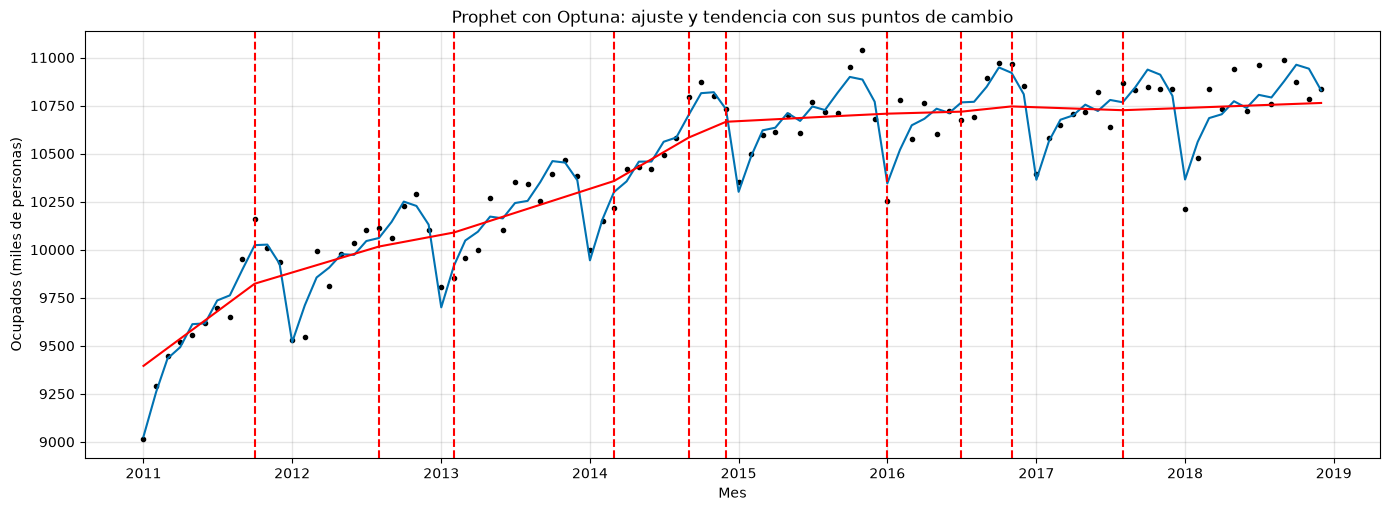

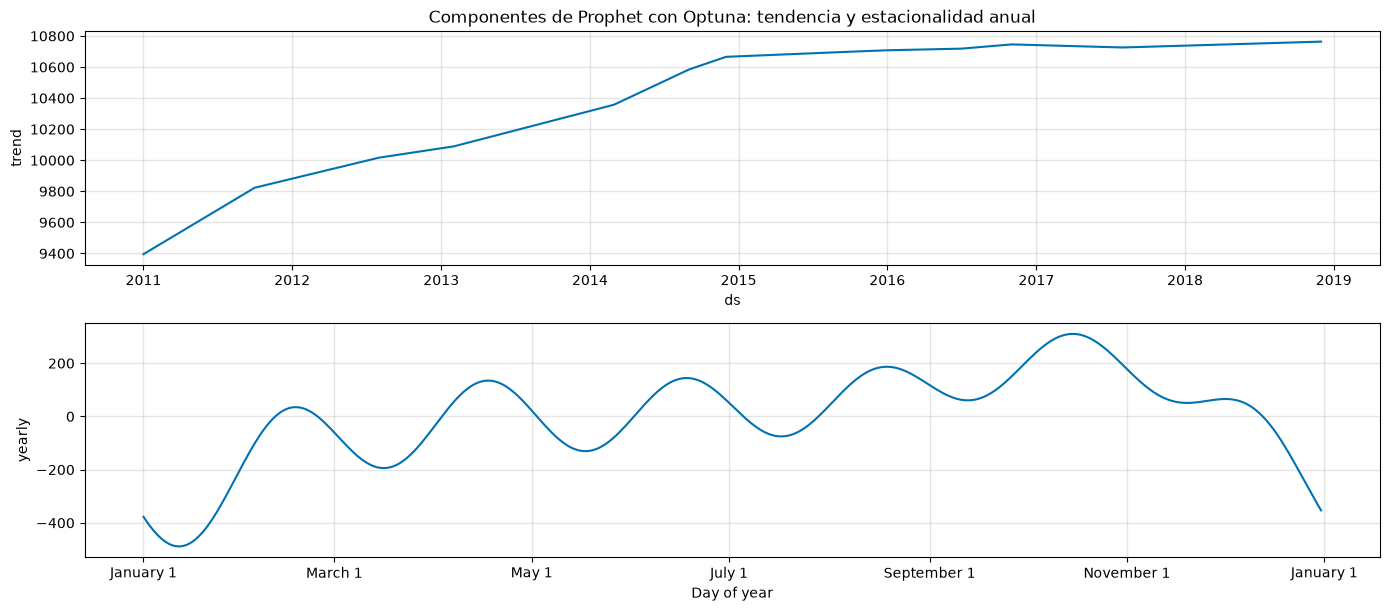

In [24]:
# Menor RMSE promedio de los intentos completos según la tendencia, la ventana y el modo estacional
intentos_prophet = pd.DataFrame([
    {**t.params, "RMSE promedio": t.value} for t in estudio_prophet.trials
    if t.state == optuna.trial.TrialState.COMPLETE and not t.user_attrs.get("repetido")
])
intentos_prophet["ventana"] = ["recursiva" if pd.isna(ventana) else str(int(ventana))
                               for ventana in intentos_prophet["ventana"]]
print("Menor RMSE promedio según la tendencia (filas) y la ventana (columnas):")
print(intentos_prophet.pivot_table(index="tendencia", columns="ventana", values="RMSE promedio", aggfunc="min")
      [["48", "60", "96", "recursiva"]].round(1).to_string())
print("\nMenor RMSE promedio según la tendencia y el modo estacional:")
print(intentos_prophet.pivot_table(index="tendencia", columns="modo_estacional", values="RMSE promedio",
                                   aggfunc="min").round(1).to_string())

# Registro del mejor intento como modelo de la familia Prophet
NOMBRE_PROPHET_OPTUNA = "Prophet con Optuna"
config_prophet = registrar_mejor(estudio_prophet, NOMBRE_PROPHET_OPTUNA, "Prophet", crear_pronostico_prophet)
assert (config_prophet["tendencia"], config_prophet["modo_estacional"], config_prophet["ventana"]) == \
    ("lineal", "additive", 96), "la estructura no coincide con la descrita"

# Comparación con las referencias y con los mejores modelos de suavización exponencial y ARIMA
modelos_comparacion_prophet = ["Naive estacional", CAMPEON_TALLER_1, NOMBRE_ETS_OPTUNA,
                               NOMBRE_SARIMA_OPTUNA, NOMBRE_PROPHET_OPTUNA]
print("\nResumen de la validación:")
print(resumir_validacion(modelos_comparacion_prophet, referencias=("Naive estacional", CAMPEON_TALLER_1))
      .round(2).to_string())
print("\nRMSE por corte (miles):")
print(error_por_corte(modelos_comparacion_prophet).round(1).to_string())

pronosticos_comparacion[NOMBRE_PROPHET_OPTUNA] = pronosticos_validacion(crear_pronostico_prophet, config_prophet)
error_medio_prophet = pd.DataFrame({
    nombre: {corte: (train.loc[pronostico.index] - pronostico).mean()
             for corte, pronostico in pronosticos_comparacion[nombre].items()}
    for nombre in [NOMBRE_ETS_OPTUNA, NOMBRE_SARIMA_OPTUNA, NOMBRE_PROPHET_OPTUNA]
})
error_medio_prophet.loc["Promedio"] = error_medio_prophet.mean()
print("\nError medio por corte (real - pronóstico, miles):")
print(error_medio_prophet.round(1).to_string())

# Componentes del modelo elegido, ajustado con su ventana al final del entrenamiento
modelo_prophet = ajustar_prophet(train, config_prophet)
ajuste_prophet = modelo_prophet.predict(modelo_prophet.history[["ds"]])
tendencia_prophet = ajuste_prophet.set_index("ds")["trend"]
aumento_anual = tendencia_prophet[tendencia_prophet.index.month == 12].diff().dropna()
aumento_anual.index = aumento_anual.index.year
print("\nAumento de la tendencia de Prophet de diciembre a diciembre (miles de personas):")
print(aumento_anual.round(1).to_string())

figura = modelo_prophet.plot(ajuste_prophet, uncertainty=False, xlabel="Mes", ylabel="Ocupados (miles de personas)",
                             figsize=(14, 5))
add_changepoints_to_plot(figura.gca(), modelo_prophet, ajuste_prophet)
figura.gca().set_title("Prophet con Optuna: ajuste y tendencia con sus puntos de cambio")
plt.show()

figura = modelo_prophet.plot_components(ajuste_prophet, uncertainty=False, figsize=(14, 6))
figura.axes[0].set_title("Componentes de Prophet con Optuna: tendencia y estacionalidad anual")
plt.show()

### Lectura de la estructura y de la comparación

**Estructura.** Todos los intentos con errores muy grandes tienen tendencia plana: el menor RMSE con tendencia plana es de 269.4 mil, con la ventana de 48 meses, y sube a 361.8, 754.0 y 1818.2 mil con las ventanas de 60 y 96 meses y la recursiva. Con tendencia plana, el nivel del modelo es el mismo en toda la ventana, de modo que queda por debajo de los valores recientes de una serie que creció durante buena parte de ella, y cuanto más larga la ventana, más crecimiento queda por fuera. El estancamiento desde 2016 no basta para que un nivel constante funcione con estas ventanas. Con tendencia lineal, la ventana de 96 meses da el menor error (109.4 mil), seguida de la de 60 (117.3 mil); con las de 48 meses y recursiva, el error sube a cerca de 132 mil. La estacionalidad aditiva es algo mejor que la multiplicativa (109.4 frente a 111.5 mil), una diferencia pequeña, coherente con los rasgos de la sección 2.

**Comparación.** Prophet es el segundo modelo con menor error de validación (109.40 mil), después del Holt-Winters ANA con Optuna (106.57 mil), y su MAPE es ligeramente menor (0.85 % frente a 0.86 %). Supera al naive estacional en 5 de los 6 cortes y al mejor modelo del taller anterior en 4. Frente al Holt-Winters, tiene menor error en 2 cortes: en el de enero de 2017, con 39.3 mil, el menor error de todos los modelos en cualquier corte, y en el de enero de 2018, por una diferencia mínima (149.1 frente a 150.1 mil). Su peor corte es el de julio de 2017, con 133.6 mil, peor que el naive estacional, porque sobreestima en 88.1 mil en promedio. Su error medio es negativo en 4 de los 6 cortes, con un promedio de −16.8 mil: tiende a sobreestimar más que el Holt-Winters (3.9 mil), pero menos que el SARIMA (−43.3 mil) y mucho menos que el modelo elegido por AIC (−88.5 mil).

**Componentes.** El modelo se ajustó con la ventana de 96 meses al final del entrenamiento (2011 a 2018). En la gráfica «Prophet con Optuna: ajuste y tendencia con sus puntos de cambio», la tendencia (línea roja) aumenta entre 203 y 370 mil personas por año de 2012 a 2014, y desde finales de 2014 se aplana: aumenta 39.1 mil en 2015, 38.8 mil en 2016, −8.2 mil en 2017 y 28.2 mil en 2018. Las líneas verticales marcan los puntos de cambio en los que la pendiente varía de forma apreciable. Prophet ubica el cambio de pendiente a finales de 2014, un año antes del corte usado en la sección 2, y el aumento promedio de 2016 a 2018 (19.6 mil por año) es cercano a la pendiente estimada allí (15.2 mil por año).

En el panel inferior de la gráfica «Componentes de Prophet con Optuna: tendencia y estacionalidad anual», la estacionalidad anual reproduce el patrón de la sección 2: el valor más bajo es el de enero, cerca de −375 mil frente a la tendencia, y los más altos están entre octubre y noviembre. Como los datos son mensuales, la estacionalidad solo se evalúa el primer día de cada mes; las oscilaciones de la curva entre un mes y otro provienen de los términos de Fourier y no afectan los pronósticos.

### Conclusión de la Parte III

Prophet, con tendencia lineal por tramos, estacionalidad aditiva y una ventana de 96 meses, alcanza un RMSE promedio de validación de 109.40 mil personas y un MAPE de 0.85 %. Es el segundo mejor modelo, cerca del Holt-Winters ANA con Optuna, y mejor que el SARIMA y que el mejor modelo del taller anterior. Su ventaja es que representa de forma explícita el cambio de la tendencia: sus puntos de cambio ubican el aplanamiento a finales de 2014, con un crecimiento cercano a cero desde entonces. La tendencia plana, que supone un nivel constante en toda la ventana, no es una alternativa con estas ventanas, porque todas incluyen años de crecimiento.

# Parte IV — Comparación final, prueba y pronóstico

## 9. Comparación de los modelos y elección del modelo final

En esta sección se comparan, con el mismo protocolo de validación, los modelos de las tres partes anteriores y los del taller anterior: el naive y el naive estacional como referencias, los tres modelos del taller anterior que sirven de comparación y su mejor modelo, el mejor modelo de cada familia nueva, la referencia de `auto_arima` y una combinación. Las reglas de la comparación se fijan antes de ver sus resultados.

**Combinación definida de antemano.** Se agrega una sola combinación: el promedio simple del mejor modelo de cada familia (el Holt-Winters ANA, el SARIMA y Prophet con Optuna). La combinación se define con una regla, un modelo por familia, y no a partir de los resultados, porque elegir qué modelos combinar mirando los mismos cortes con los que se evalúa haría su error artificialmente bajo. Sus pronósticos se construyen con los pronósticos de cada corte ya guardados, y se verifica en el último corte que coinciden con los de volver a ajustar los tres modelos.

**Regla de elección.** Como en el taller anterior, el modelo final es el de menor RMSE promedio de validación entre los modelos comparados. El MAPE, el número de cortes en que cada modelo supera a las referencias y el error medio complementan la lectura, pero no cambian la elección. Cada familia llega a esta comparación con el modelo elegido en su sección; en la familia ARIMA, ese modelo ya pasó por la revisión de los supuestos de sus residuales. La muestra de prueba no cambia la elección: solo sirve para comprobar si el desempeño se mantiene en meses que ningún modelo vio.

**Prueba de Diebold-Mariano.** Para saber si las diferencias de error entre modelos son sistemáticas o pueden deberse a los semestres particulares de la validación, se aplica la prueba de Diebold-Mariano con pérdida cuadrática. Los pronósticos de validación cubren cada mes de 2016 a 2018 una sola vez, con horizontes de 1 a 6 meses, de modo que cada modelo tiene una secuencia de 36 errores. Cada modelo se compara con el mejor modelo del taller anterior y con el modelo final. Como los errores de un mismo corte comparten el origen del pronóstico, están correlacionados; por eso, la varianza del estadístico incluye las autocovarianzas hasta el rezago 5, y se aplica la corrección de Harvey, Leybourne y Newbold para muestras pequeñas, con una distribución t de Student de 35 grados de libertad y un nivel de 0.05. La prueba tiene dos limitaciones: con 36 meses, su potencia es baja, de modo que un p-valor alto indica que los datos no bastan para distinguir los modelos y no que sean iguales; y los modelos con Optuna se eligieron con estos mismos cortes, por lo que su ventaja frente a los demás puede estar sobreestimada.

**Error por horizonte.** Por último, se calcula el RMSE de cada horizonte, de 1 a 6 meses, con los 6 cortes. Como los cortes empiezan siempre en enero o en julio, cada horizonte corresponde a los mismos dos meses del calendario (el horizonte 1 a enero y julio, y el 6 a junio y diciembre), de modo que este cálculo mezcla el efecto de alejarse del último dato observado con el de esos meses, y cada valor se calcula con solo 6 errores.

Comparación final de la validación (RMSE y error medio en miles de personas):
                                                                          Familia  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional  Cortes mejores que Combinación ANA + regresión (taller 1)  Error medio  p-valor DM frente al campeón del taller 1  p-valor DM frente al modelo final
Holt-Winters ANA con Optuna                               Suavización exponencial        106.565              0.860                                    6                                                          5        3.895                                      0.045                                NaN
Combinación ANA + SARIMA + Prophet con Optuna                         Combinación        109.363              0.866                                    4                                                          5      -18.726                                      0.032                              0.190
Prophet con O

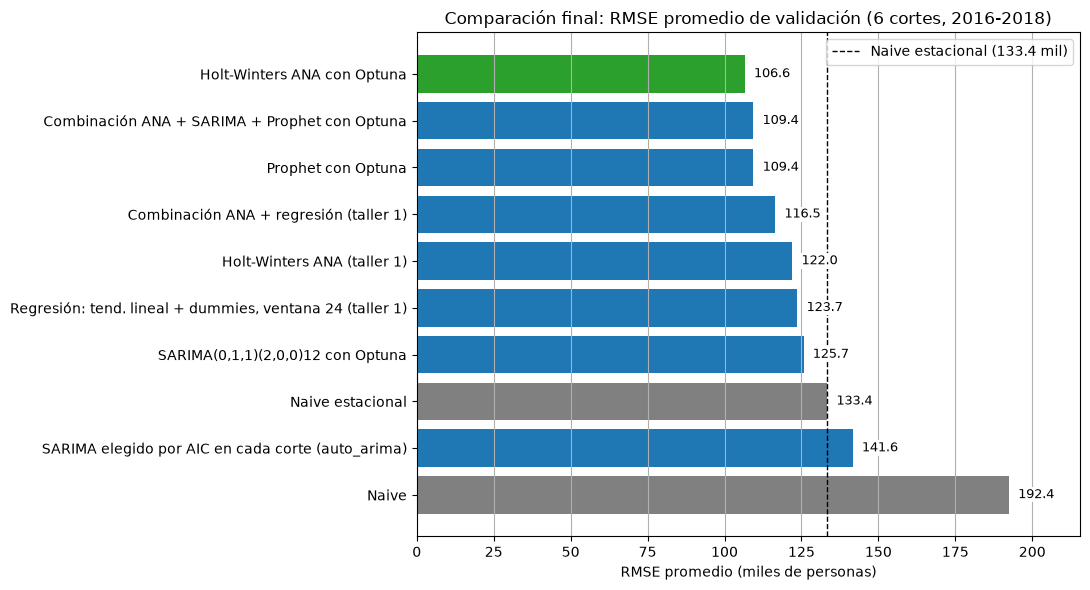


RMSE por corte (miles):
                   Naive estacional  Combinación ANA + regresión (taller 1)  Holt-Winters ANA con Optuna  SARIMA(0,1,1)(2,0,0)12 con Optuna  Prophet con Optuna  Combinación ANA + SARIMA + Prophet con Optuna
inicio_validacion                                                                                                                                                                                             
2016-01                       149.4                                   152.3                        134.6                              156.8               139.2                                          138.4
2016-07                       113.5                                    53.3                         81.8                               62.3                72.6                                           65.8
2017-01                       122.8                                    77.2                         52.3                              114.8        

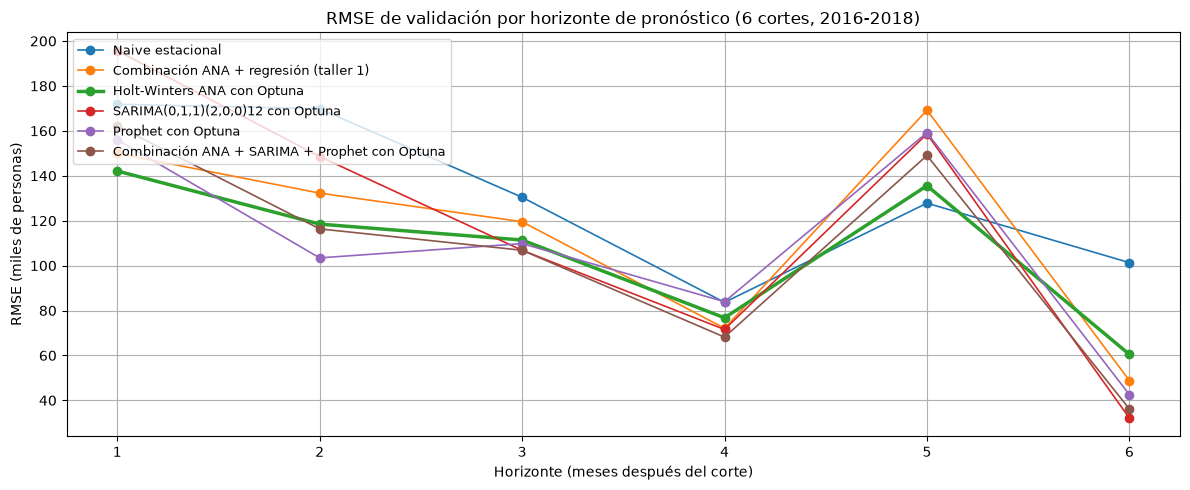

In [25]:
def pronosticos_por_corte(nombre, serie=train, cv=tscv):
    """Pronósticos de cada corte de un modelo registrado, como {inicio del corte: serie de pronósticos}.

    Usa los pronósticos ya leídos del caché si están disponibles; si no, los calcula con la función de
    pronóstico del modelo (solo modelos rápidos de estimar, como los del taller anterior).
    """
    if nombre in pronosticos_comparacion:
        return pronosticos_comparacion[nombre]
    pronosticos = {}
    for idx_ajuste, idx_validacion in cv.split(serie):
        fechas = serie.index[idx_validacion]
        valores = funciones_pronostico[nombre](serie.iloc[idx_ajuste], len(fechas))
        pronosticos[fechas[0].strftime("%Y-%m")] = pd.Series(np.asarray(valores, dtype=float), index=fechas)
    return pronosticos


def diebold_mariano(errores_a, errores_b, h=horizonte):
    """Prueba de Diebold-Mariano con pérdida cuadrática y la corrección de Harvey, Leybourne y Newbold.

    La varianza de la diferencia de pérdidas incluye sus autocovarianzas hasta el rezago h - 1, porque
    los errores de pronósticos con el mismo origen están correlacionados. Devuelve el estadístico
    corregido (negativo si el modelo a tiene menor error) y su p-valor bilateral con una t de Student
    de n - 1 grados de libertad; si la varianza estimada no es positiva, devuelve NaN.
    """
    diferencia = (errores_a ** 2 - errores_b ** 2).to_numpy()
    n = len(diferencia)
    centrada = diferencia - diferencia.mean()
    autocovarianzas = [np.sum(centrada[rezago:] * centrada[:n - rezago]) / n for rezago in range(h)]
    varianza_media = (autocovarianzas[0] + 2 * sum(autocovarianzas[1:])) / n
    if varianza_media <= 0:
        return np.nan, np.nan
    correccion = np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    estadistico = correccion * diferencia.mean() / np.sqrt(varianza_media)
    return estadistico, 2 * stats.t.sf(abs(estadistico), df=n - 1)


# Combinación definida de antemano: promedio simple del mejor modelo de cada familia
NOMBRE_COMBINACION_FAMILIAS = "Combinación ANA + SARIMA + Prophet con Optuna"
MODELOS_COMBINACION = [NOMBRE_ETS_OPTUNA, NOMBRE_SARIMA_OPTUNA, NOMBRE_PROPHET_OPTUNA]
pronosticos_combinacion = {
    corte: pd.concat([pronosticos_comparacion[nombre][corte] for nombre in MODELOS_COMBINACION], axis=1).mean(axis=1)
    for corte in pronosticos_comparacion[NOMBRE_ETS_OPTUNA]
}
resultados_combinacion = pd.DataFrame([
    {"inicio_validacion": corte, **calcular_metricas(train.loc[pronostico.index], pronostico), "estado": "loaded"}
    for corte, pronostico in pronosticos_combinacion.items()
]).set_index("inicio_validacion")
registrar_modelo(NOMBRE_COMBINACION_FAMILIAS, "Combinación",
                 combinar(*(funciones_pronostico[nombre] for nombre in MODELOS_COMBINACION)),
                 resultados=resultados_combinacion)
pronosticos_comparacion[NOMBRE_COMBINACION_FAMILIAS] = pronosticos_combinacion

# Verificación: en el último corte, volver a ajustar los tres modelos da el mismo pronóstico combinado
idx_ajuste, idx_validacion = list(tscv.split(train))[-1]
pronostico_reajustado = funciones_pronostico[NOMBRE_COMBINACION_FAMILIAS](train.iloc[idx_ajuste], horizonte)
assert np.allclose(pronostico_reajustado, list(pronosticos_combinacion.values())[-1], rtol=1e-4), \
    "la combinación construida desde el caché no coincide con la reajustada"

# Modelos de la comparación final: referencias, taller anterior, mejor de cada familia, auto_arima y combinación
MODELOS_FINALES = [*RESULTADOS_TALLER_1, NOMBRE_ETS_OPTUNA, NOMBRE_SARIMA_OPTUNA, NOMBRE_AUTO_ARIMA,
                   NOMBRE_PROPHET_OPTUNA, NOMBRE_COMBINACION_FAMILIAS]

# Errores de validación de cada modelo (real - pronóstico): una secuencia de 36 meses, de 2016-01 a 2018-12
errores_validacion = pd.DataFrame({
    nombre: pd.concat(pronosticos_por_corte(nombre).values()).pipe(lambda pronostico: train.loc[pronostico.index] - pronostico)
    for nombre in MODELOS_FINALES
})
assert len(errores_validacion) == n_cortes * horizonte and errores_validacion.index.is_unique

# Tabla resumen ordenada por RMSE promedio, con el error medio y las pruebas de Diebold-Mariano
resumen_final = resumir_validacion(MODELOS_FINALES, referencias=("Naive estacional", CAMPEON_TALLER_1))
resumen_final.insert(0, "Familia", [familias[nombre] for nombre in resumen_final.index])
resumen_final["Error medio"] = errores_validacion.mean()
MODELO_FINAL = resumen_final.index[0]   # regla de elección: menor RMSE promedio de validación
for nombre_columna, referencia in [("p-valor DM frente al campeón del taller 1", CAMPEON_TALLER_1),
                                   ("p-valor DM frente al modelo final", MODELO_FINAL)]:
    resumen_final[nombre_columna] = [
        np.nan if nombre == referencia else diebold_mariano(errores_validacion[nombre], errores_validacion[referencia])[1]
        for nombre in resumen_final.index
    ]
print("Comparación final de la validación (RMSE y error medio en miles de personas):")
print(resumen_final.round(3).to_string())
print(f"\nModelo final (menor RMSE promedio de validación): {MODELO_FINAL}")

# Gráfica de barras del RMSE promedio, con el modelo final resaltado
graficar_resumen_validacion({nombre: nombre for nombre in MODELOS_FINALES}, destacado=MODELO_FINAL,
                            titulo="Comparación final: RMSE promedio de validación (6 cortes, 2016-2018)")

# RMSE por corte de los mejores modelos de cada familia, la combinación y las dos referencias
MODELOS_FINALISTAS = ["Naive estacional", CAMPEON_TALLER_1, NOMBRE_ETS_OPTUNA, NOMBRE_SARIMA_OPTUNA,
                      NOMBRE_PROPHET_OPTUNA, NOMBRE_COMBINACION_FAMILIAS]
print("\nRMSE por corte (miles):")
print(error_por_corte(MODELOS_FINALISTAS).round(1).to_string())

# RMSE por horizonte: en cada corte, el mes h del pronóstico tiene horizonte h
horizonte_de_cada_mes = np.tile(np.arange(1, horizonte + 1), n_cortes)
rmse_por_horizonte = (errores_validacion[MODELOS_FINALISTAS] ** 2).groupby(horizonte_de_cada_mes).mean() ** 0.5
rmse_por_horizonte.index.name = "Horizonte (meses)"
print("\nRMSE por horizonte de pronóstico (miles):")
print(rmse_por_horizonte.round(1).to_string())

fig, ax = plt.subplots(figsize=(12, 5))
for nombre in MODELOS_FINALISTAS:
    ax.plot(rmse_por_horizonte.index, rmse_por_horizonte[nombre], marker="o",
            linewidth=2.5 if nombre == MODELO_FINAL else 1.2, label=nombre)
ax.set_title("RMSE de validación por horizonte de pronóstico (6 cortes, 2016-2018)")
ax.set_xlabel("Horizonte (meses después del corte)")
ax.set_ylabel("RMSE (miles de personas)")
ax.legend(loc="upper left", fontsize=9)
ax.grid()
plt.tight_layout()
plt.show()

### Lectura de la comparación final y elección del modelo

**Elección.** Según la regla, el modelo final es el **Holt-Winters aditivo sin tendencia (ANA) con parámetros de suavización ajustados por Optuna**, con el menor RMSE promedio de validación (106.57 mil personas) y un MAPE de 0.86 %. En la gráfica «Comparación final: RMSE promedio de validación (6 cortes, 2016-2018)» es la barra verde, y es el único modelo que supera al naive estacional en los 6 cortes. Supera al mejor modelo del taller anterior en 5 de los 6 cortes, con un RMSE 8.5 % menor, y la prueba de Diebold-Mariano indica que esa diferencia es estadísticamente distinguible (p-valor de 0.045). Además, su error medio es de 3.9 mil personas, el más cercano a cero de todos los modelos: es el único sin una tendencia a sobreestimar o subestimar la serie.

**Modelos cercanos.** Prophet (109.40 mil) y la combinación de las tres familias (109.36 mil) quedan muy cerca del modelo final, y la prueba de Diebold-Mariano no distingue su error del de él (p-valores de 0.237 y 0.190). Prophet tiene incluso un MAPE ligeramente menor (0.85 %), pero tiende a sobreestimar (error medio de −16.8 mil). La combinación no supera al Holt-Winters: queda entre sus componentes en la mayoría de los cortes y solo lo supera en el de julio de 2016 (65.8 frente a 81.8 mil), porque uno de sus tres componentes, el SARIMA, tiene errores mayores y sesgados (error medio de −43.3 mil). Con un RMSE apenas 0.03 mil menor que el de Prophet, la combinación no aporta una mejora frente a su mejor componente.

**Resto de los modelos.** Los modelos del taller anterior quedan detrás: su mejor modelo (116.47 mil), el Holt-Winters ANA estimado por máxima verosimilitud (122.02 mil) y la regresión (123.68 mil). La diferencia entre los dos Holt-Winters ANA, que solo se distinguen por cómo se eligen sus parámetros de suavización, es estadísticamente distinguible (p-valor de 0.004). El SARIMA elegido (125.67 mil) supera al naive estacional, pero su error es significativamente mayor que el del modelo final (p-valor de 0.001), y el modelo elegido por AIC (141.64 mil) no supera al naive estacional. Frente al mejor modelo del taller anterior, ningún modelo distinto del Holt-Winters con Optuna y de la combinación que lo incluye tiene una diferencia estadísticamente distinguible.

**Error por corte.** El Holt-Winters con Optuna tiene el menor error de los finalistas en 2 cortes (enero de 2016 y julio de 2017) y no es el peor en ninguno; su mayor error es el del corte de enero de 2018 (150.1 mil), un semestre difícil para todos los modelos. Los demás cortes los ganan modelos distintos: el mejor modelo del taller anterior en julio de 2016, Prophet en enero de 2017 y enero de 2018, y la combinación en julio de 2018, por una diferencia de 0.1 mil frente al modelo final.

**Error por horizonte.** En la gráfica «RMSE de validación por horizonte de pronóstico (6 cortes, 2016-2018)», el error no crece de forma regular con el horizonte. En cuatro de los seis modelos el mayor error está en el horizonte 1, que corresponde a enero y julio y, con ellos, a la caída de enero, y en los otros dos está en el horizonte 5, que corresponde a mayo y noviembre. Los menores errores están en el horizonte 6 (junio y diciembre) en cinco de los seis modelos. Con 6 errores por horizonte y cada horizonte ligado a dos meses del calendario, estas diferencias reflejan sobre todo la dificultad de esos meses y no el efecto del horizonte. Por eso, los intervalos del pronóstico final se construyen con los errores de pronóstico desde todos los meses de origen de la historia, en los que cada horizonte incluye todos los meses del año.

Hay que tener en cuenta que los modelos con Optuna se eligieron con estos mismos 6 cortes, de modo que su error de validación es probablemente algo optimista. La muestra de prueba, que se usa por primera vez en la sección siguiente, permite comprobar si el desempeño del modelo final se mantiene.

## 10. Evaluación en la muestra de prueba

Con el modelo final ya elegido, se usa por primera vez la muestra de prueba, de enero a junio de 2019. Cada modelo de la comparación final se ajusta con todo el entrenamiento, con su propia regla de estimación (por ejemplo, el SARIMA con toda la historia y Prophet con los últimos 96 meses), y pronostica los 6 meses de prueba sin usar ninguno de sus valores reales. Los resultados de los modelos del taller anterior se verifican contra los obtenidos en ese taller.

Estos resultados no cambian la elección del modelo final. Sirven para estimar el error que se puede esperar de él en datos que no participaron en ninguna decisión, y para revisar si el orden de los modelos en la validación se mantiene en un periodo nuevo. Hay que tener en cuenta que la prueba tiene solo 6 meses, un único semestre con su propia caída de enero, de modo que sus diferencias entre modelos son menos confiables que las de los 6 cortes de validación.

Verificación: los modelos del taller anterior reproducen sus resultados en la muestra de prueba.

Resumen de la validación y de la prueba (RMSE y error medio en miles de personas):
                                                                          Familia  RMSE validación  MAPE validación (%)  RMSE prueba  MAPE prueba (%)  Error medio prueba  Posición validación  Posición prueba
Combinación ANA + SARIMA + Prophet con Optuna                         Combinación           109.36                 0.87        69.14             0.56              -15.15                    2                6
Combinación ANA + regresión (taller 1)                                Combinación           116.47                 0.92        62.72             0.52                4.74                    4                1
Holt-Winters ANA (taller 1)                               Suavización exponencial           122.02                 0.98       108.16             0.83               51.95                    5     

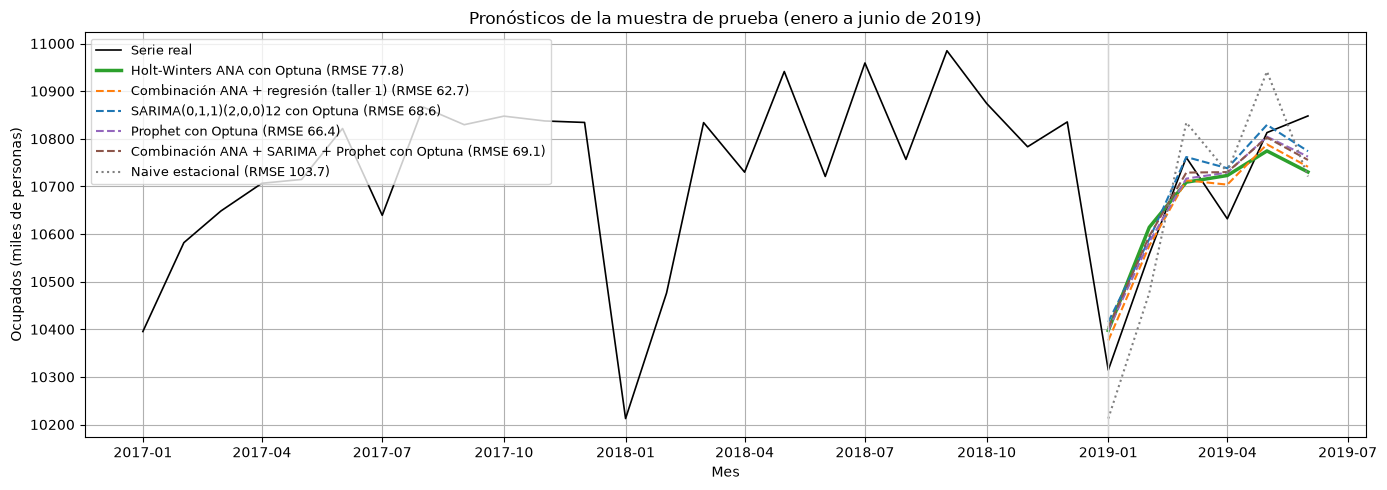

In [26]:
# Pronósticos de enero a junio de 2019: cada modelo se ajusta con todo el entrenamiento, con su propia regla
pronosticos_prueba = pd.DataFrame({
    nombre: np.asarray(funciones_pronostico[nombre](train, horizonte), dtype=float) for nombre in MODELOS_FINALES
}, index=test.index)

# Métricas en la prueba y verificación contra el taller anterior (misma tolerancia que en la sección 4)
metricas_prueba = pd.DataFrame({nombre: calcular_metricas(test, pronosticos_prueba[nombre])
                                for nombre in MODELOS_FINALES}).T
for nombre, (_, _, _, rmse_prueba, mape_prueba) in RESULTADOS_TALLER_1.items():
    tolerancia = 0.5 if familias[nombre] in ("Suavización exponencial", "Combinación") else 0.01
    assert np.isclose(metricas_prueba.loc[nombre, "rmse"], rmse_prueba, atol=tolerancia), f"{nombre}: RMSE de prueba"
    assert np.isclose(metricas_prueba.loc[nombre, "mape"], mape_prueba, atol=0.01), f"{nombre}: MAPE de prueba"
print("Verificación: los modelos del taller anterior reproducen sus resultados en la muestra de prueba.\n")

# Tabla resumen: validación y prueba de los 10 modelos, en el orden de la validación
tabla_resumen = pd.DataFrame({
    "Familia": resumen_final["Familia"],
    "RMSE validación": resumen_final["RMSE promedio"],
    "MAPE validación (%)": resumen_final["MAPE promedio (%)"],
    "RMSE prueba": metricas_prueba["rmse"],
    "MAPE prueba (%)": metricas_prueba["mape"],
    "Error medio prueba": (test.to_numpy()[:, None] - pronosticos_prueba).mean(),
})
tabla_resumen["Posición validación"] = tabla_resumen["RMSE validación"].rank().astype(int)
tabla_resumen["Posición prueba"] = tabla_resumen["RMSE prueba"].rank().astype(int)
print("Resumen de la validación y de la prueba (RMSE y error medio en miles de personas):")
print(tabla_resumen.round(2).to_string())

# Error de cada mes de prueba del modelo final y de las dos referencias
modelos_detalle_prueba = [MODELO_FINAL, CAMPEON_TALLER_1, "Naive estacional"]
print("\nError de cada mes de prueba (real - pronóstico, miles):")
print((test.to_numpy()[:, None] - pronosticos_prueba[modelos_detalle_prueba]).round(1).to_string())

# Pronósticos de la prueba de los finalistas frente a la serie real
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ocupados.loc["2017":], color="black", linewidth=1.2, label="Serie real")
estilos_prueba = {MODELO_FINAL: dict(color="C2", linewidth=2.5), CAMPEON_TALLER_1: dict(color="C1", linestyle="--"),
                  NOMBRE_SARIMA_OPTUNA: dict(color="C0", linestyle="--"), NOMBRE_PROPHET_OPTUNA: dict(color="C4", linestyle="--"),
                  NOMBRE_COMBINACION_FAMILIAS: dict(color="C5", linestyle="--"),
                  "Naive estacional": dict(color="gray", linestyle=":")}
for nombre, estilo in estilos_prueba.items():
    ax.plot(pronosticos_prueba[nombre], label=f"{nombre} (RMSE {metricas_prueba.loc[nombre, 'rmse']:.1f})", **estilo)
ax.axvline(test.index[0], color="lightgray", linewidth=1)
ax.set_title("Pronósticos de la muestra de prueba (enero a junio de 2019)")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left", fontsize=9)
ax.grid()
plt.tight_layout()
plt.show()